In [1]:
import gc
import joblib

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap

import optuna
import optuna.visualization as vis
from optuna.integration import XGBoostPruningCallback

from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr

from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, make_scorer, r2_score, root_mean_squared_error
from sklearn.model_selection import (
    KFold,
    TimeSeriesSplit,
    cross_val_score,
    cross_validate,
    train_test_split
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MultiLabelBinarizer, OneHotEncoder, StandardScaler

import xgboost as xgb
from xgboost import XGBRegressor, plot_importance
from sklearn.inspection import PartialDependenceDisplay

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestRegressor

from sklearn.neural_network import MLPRegressor

<h2>Read-in Data</h2>

In [2]:
campd_type_dict = {
    'State': 'string',
    'Facility Name': 'string',
    'Facility ID': 'Int32',
    'Unit ID': 'string',
    'Hour': 'Int8',
    'Operating Time': 'float32',
    'Gross Load (MW)': 'float32',
    'Steam Load (1000 lb/hr)': 'float32',
    'SO2 Mass (lbs)': 'float64',
    'SO2 Mass Measure Indicator': 'string',
    'SO2 Rate (lbs/mmBtu)': 'float32',
    'SO2 Rate Measure Indicator': 'string',
    'CO2 Mass (short tons)': 'float32',
    'CO2 Mass Measure Indicator': 'string',
    'CO2 Rate (short tons/mmBtu)': 'float32',
    'CO2 Rate Measure Indicator': 'string',
    'NOx Mass (lbs)': 'float32',
    'NOx Mass Measure Indicator': 'string',
    'NOx Rate (lbs/mmBtu)': 'float32',
    'NOx Rate Measure Indicator': 'string',
    'Heat Input (mmBtu)': 'float64',
    'Heat Input Measure Indicator': 'string',
    'Primary Fuel Type': 'string',
    'Secondary Fuel Type': 'string',
    'Unit Type': 'string',
    'SO2 Controls': 'string',
    'NOx Controls': 'string',
    'Program Code': 'string',
    'Year': 'int16',
    'Source Category': 'string',
    'Latitude': 'float32',
    'Longitude': 'float32',
    'SO2 Phase': 'string',
    'NOx Phase': 'string',
    'Operating Status': 'string',
    'Max Hourly HI Rate (mmBtu/hr)': 'float32',
    'Associated Generators & Nameplate Capacity (MWe)': 'string',
    'Nameplate Capacity (MWe)': 'float32',
    'Month': 'Int8',
    'hourly_capacity_factor': 'float32',
    'hourly_ramping_factor': 'float32',
    'Nameplate Capacity (MW) - EIA': 'float32',
    'Summer Capacity (MW)': 'float32',
    'Winter Capacity (MW)': 'float32',
    'Minimum Load (MW)': 'float32',
    'Operating Year_min': 'float32',
    'Operating Year_max': 'float32',
    'Operating Year_mean': 'float32',
    'Planned Retirement Year': 'Int16',
    'unit_age_min': 'Int8',
    'unit_age_max': 'Int8',
    'unit_age_mean': 'float32',
    'Day': 'float32',
    'Temperature (F)': 'float32'
}

In [ ]:
# Combine both operating and non-operating data into a full dataset for consistent time series analysis

# Data with operations
campd_wy_operating = pd.read_csv("WY/Hourly/Concatted File/wy_2019_2024_complete_cleaned.csv", dtype=campd_type_dict, date_format=["Date"])
# Data without operations
campd_wy_nonoperating = pd.read_csv("WY/Hourly/Concatted File/wy_2019_2024_complete_cleaned_NonOperating.csv", dtype=campd_type_dict, date_format=["Date"])

campd_wy = pd.concat([campd_wy_operating, campd_wy_nonoperating])
del campd_wy_nonoperating
del campd_wy_operating
gc.collect()

# create full datetime column (date + hour)
campd_wy["datetime"] = pd.to_datetime(campd_wy["Date"].astype(str) + ' ' + campd_wy["Hour"].astype(str).str.zfill(2) + ":00:00")

campd_wy.to_csv("WY/Hourly/Concatted File/wy_2019_2024_complete_cleaned_Full.csv", index=False)

In [44]:
campd_wy = pd.read_csv("WY/Hourly/Concatted File/wy_2019_2024_complete_cleaned_Full.csv", dtype=campd_type_dict)
campd_wy["Date"] = pd.to_datetime(campd_wy["Date"])
campd_wy["datetime"] = pd.to_datetime(campd_wy["datetime"])

In [23]:
campd_nd = pd.read_csv("ND/Hourly/Concatted File/nd_2019_2024_complete_cleaned.csv", dtype=campd_type_dict)
campd_nd["datetime"] = pd.to_datetime(campd_nd["Date"].astype(str) + ' ' + campd_nd["Hour"].astype(str).str.zfill(2) + ":00:00")

In [24]:
campd_mt = pd.read_csv("MT/Hourly/Concatted File/mt_2019_2024_complete_cleaned.csv", dtype=campd_type_dict)
campd_mt["datetime"] = pd.to_datetime(campd_mt["Date"].astype(str) + ' ' + campd_mt["Hour"].astype(str).str.zfill(2) + ":00:00")


<h2>Regression Models</h2>

<h3>Linear Regression</h3>

<h5>WY Only</h5>

In [5]:
campd_df = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/wy_2019_2024_complete_cleaned_Full_manually_encoded", dtype=campd_type_dict)

In [ ]:
df_control_cols = ['Dry Low NOx Burners', 'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Overfire Air',
       'Selective Catalytic Reduction',
       'Selective Catalytic Reduction (Began Jun 27, 2019)',
       'Selective Non-catalytic Reduction']
df_code_cols = ['ARP', 'MATS']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ]

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) #+ lag_cols #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

# use simple imputer to fill nan values with median (necessary for linear regression)
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), 
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features) 
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [76]:
print(X_train.shape)
print(X_test.shape)

(2106900, 32)
(435797, 32)


In [100]:
print(X_train.shape)
print(X_test.shape)

(600234, 106)
(191914, 106)


In [79]:
train_not_in_test = set(X_train.columns) - set(X_test.columns)
test_not_in_train = set(X_test.columns) - set(X_train.columns)
print("In train but not in test:", train_not_in_test)
print("In test but not in train:", test_not_in_train)

In train but not in test: {'cat__Primary Fuel Type_Coal, Pipeline Natural Gas'}
In test but not in train: set()


In [96]:
X_test["cat__Primary Fuel Type_Coal, Pipeline Natural Gas"] = 0

In [ ]:
position_in_train = X_train.columns.get_loc("cat__Primary Fuel Type_Coal, Pipeline Natural Gas")
print(f"Position in X_train: {position_in_train}")

Position in X_train: 78


In [63]:
display(X_test)
display(y_test)

,cat__Month_1.0,cat__Month_2.0,cat__Month_3.0,cat__Month_4.0,cat__Month_5.0,cat__Month_6.0,cat__Month_7.0,cat__Month_8.0,cat__Month_9.0,cat__Month_10.0,...,encoded__Low NOx Burner Technology w/ Overfire Air,encoded__Low NOx Burner Technology w/ Separated OFA,encoded__Nothing,encoded__Overfire Air,encoded__Selective Catalytic Reduction,"encoded__Selective Catalytic Reduction (Began Jun 27, 2019)",encoded__Selective Non-catalytic Reduction,encoded__ARP,encoded__MATS,"cat__Primary Fuel Type_Coal, Pipeline Natural Gas"
87525,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,1,0,0,0,0,1,1,0
87526,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,1,0,0,0,0,1,1,0
192616,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,1,0,0,0,0,1,1,0
192617,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,1,0,0,0,0,1,1,0
297707,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1,0,0,0,0,0,0,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2332422,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,1,0,0,1,0,0
2437558,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,1,0,0,1,0,0
2437559,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,1,0,0,1,0,0
2542695,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,1,0,0,1,0,0


87525      199.492996
87526      199.492996
192616     158.149994
192617     158.149994
297707     264.080994
              ...    
2332422      2.772000
2437558      0.000000
2437559      0.000000
2542695      0.000000
2542696      0.000000
Name: NOx Mass (lbs), Length: 435797, dtype: float32

In [ ]:
# Reorder columns accordingly (cols need to be in same order for X_train and X_test)

columns = list(X_test.columns)
columns.remove("cat__Primary Fuel Type_Coal, Pipeline Natural Gas")
columns.insert(position_in_train, "cat__Primary Fuel Type_Coal, Pipeline Natural Gas")
X_test = X_test[columns]

In [71]:
display(X_test)
display(y_test)

,cat__Month_1.0,cat__Month_2.0,cat__Month_3.0,cat__Month_4.0,cat__Month_5.0,cat__Month_6.0,cat__Month_7.0,cat__Month_8.0,cat__Month_9.0,cat__Month_10.0,...,encoded__Low NOx Burner Technology w/ Closed-coupled OFA,encoded__Low NOx Burner Technology w/ Overfire Air,encoded__Low NOx Burner Technology w/ Separated OFA,encoded__Nothing,encoded__Overfire Air,encoded__Selective Catalytic Reduction,"encoded__Selective Catalytic Reduction (Began Jun 27, 2019)",encoded__Selective Non-catalytic Reduction,encoded__ARP,encoded__MATS
87525,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,1,0,0,0,0,1,1
87526,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,1,0,0,0,0,1,1
192616,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,1,0,0,0,0,1,1
192617,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,1,0,0,0,0,1,1
297707,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,1,0,0,0,0,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2332422,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,1,0,0,1,0
2437558,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,1,0,0,1,0
2437559,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,1,0,0,1,0
2542695,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,1,0,0,1,0


87525      199.492996
87526      199.492996
192616     158.149994
192617     158.149994
297707     264.080994
              ...    
2332422      2.772000
2437558      0.000000
2437559      0.000000
2542695      0.000000
2542696      0.000000
Name: NOx Mass (lbs), Length: 435797, dtype: float32

In [98]:
navals_train = X_train.isna().sum()
print(navals_train[navals_train>0])

navals_test = X_test.isna().sum()
print(navals_test[navals_test>0])


num__hourly_ramping_factor         10
num__Summer Capacity (MW)     1482389
num__Winter Capacity (MW)     1482389
num__Minimum Load (MW)        1482389
num__Temperature (F)            88076
dtype: int64
num__Summer Capacity (MW)    243207
num__Winter Capacity (MW)    243207
num__Minimum Load (MW)       243207
num__Temperature (F)           3505
dtype: int64


In [99]:
X_train = X_train.dropna(axis=0, how='any')  # drop rows with any NaN values
y_train = y_train[X_train.index]  # align y_train with X_train after dropping NaN rows

X_test = X_test.dropna(axis=0, how='any')
y_test = y_test[X_test.index]  

In [ ]:
# default model (no lags, no unmeasured, with temps)

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict on test set
y_pred = lr_model.predict(X_test)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0

# Evaluate performance
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

# Plot actual vs predicted
plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (Linear Regression)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()



In [ ]:
X_train = X_train.dropna(axis=0, how='any')  # drop rows with any NaN values
y_train = y_train[X_train.index]  # align y_train with X_train after dropping NaN rows

R^2 Score: 0.9426
Mean Squared Error (MSE): 211.2194
Root Mean Squared Error (RMSE): 14.5334
Normalized RMSE (by std): 0.2393


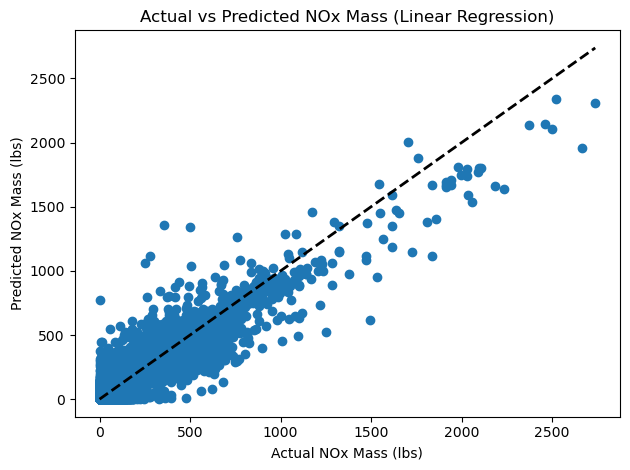

In [ ]:
# default model (with lags, no unmeasured, with temps)

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict on test set
y_pred = lr_model.predict(X_test)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0

# Evaluate performance
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

# Plot actual vs predicted
plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (Linear Regression)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

<h3>Random Forest</h3>

In [ ]:
# default params are:
# n_estimators=100, *, criterion='gini', max_depth=None, min_samples_split=2, 
# min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features='sqrt', 
# max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=True, oob_score=False,
#  n_jobs=None, random_state=None, verbose=0, warm_start=False, class_weight=None, 
# ccp_alpha=0.0, max_samples=None, monotonic_cst=None

<h5>WY Only</h5>

In [82]:
campd_df = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/wy_2019_2024_complete_cleaned_Full_manually_encoded", dtype=campd_type_dict)

In [ ]:
df_control_cols = ['Dry Low NOx Burners', 'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Overfire Air',
       'Selective Catalytic Reduction',
       'Selective Catalytic Reduction (Began Jun 27, 2019)',
       'Selective Non-catalytic Reduction']
df_code_cols = ['ARP', 'MATS']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ]

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) + lag_cols #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features) 
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [84]:
# Add column from X_train and reorder accordingly (cols need to be in same order for X_train and X_test)

X_test["cat__Primary Fuel Type_Coal, Pipeline Natural Gas"] = 0
position_in_train = X_train.columns.get_loc("cat__Primary Fuel Type_Coal, Pipeline Natural Gas")
print(f"Position in X_train: {position_in_train}")
columns = list(X_test.columns)
columns.remove("cat__Primary Fuel Type_Coal, Pipeline Natural Gas")
columns.insert(position_in_train, "cat__Primary Fuel Type_Coal, Pipeline Natural Gas")
X_test = X_test[columns]

Position in X_train: 78


In [ ]:
# takes approx. 11 mins to compute (full train data), model size is >11gb

rf_model_no_lags_full_train = RandomForestRegressor(random_state=42, n_jobs=-1)

# Train Random Forest model with default parameters
rf_model_no_lags_full_train.fit(X_train, y_train.values.ravel())

RandomForestRegressor(n_jobs=-1, random_state=42)

R^2 Score: 0.8845
Mean Squared Error (MSE): 5361.0393
Root Mean Squared Error (RMSE): 73.2191
Normalized RMSE (by std): 0.3400


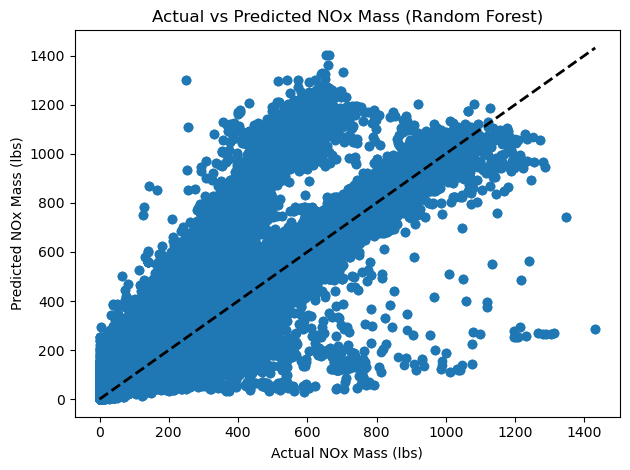

In [ ]:
# default model (no lags, no unmeasured data, with temps)

# rf model trained on full training data
# only very small improvement

y_pred = rf_model_no_lags_full_train.predict(X_test)

# Set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (Random Forest)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

In [ ]:
print(len(rf_model_no_lags_full_train.estimators_))  # Number of trees

100


In [ ]:
# per default, sklearn sets no max_depth for rf trees so we look at efective depth

tree_depths = [estimator.tree_.max_depth for estimator in rf_model_no_lags_full_train.estimators_]
print("Effective max depth:", max(tree_depths))
print("Average depth:", sum(tree_depths) / len(tree_depths))
print("Depths of first 5 trees:", tree_depths[:5])

# deep trees

Effective max depth: 94
Average depth: 82.01
Depths of first 5 trees: [81, 80, 80, 89, 78]


In [ ]:
# downsample the training data to 50%
X_sampled, y_sampled = (
    X_train.sample(frac=0.5, random_state=42),
    y_train.loc[X_train.sample(frac=0.5, random_state=42).index]
)
X_sampled.shape

(1053450, 106)

In [ ]:
# still takes approx. 5 mins to compute (50% sample)

rf_model_no_lags = RandomForestRegressor(random_state=42, n_jobs=-1)

# Train Random Forest model with default parameters
rf_model_no_lags.fit(X_sampled, y_sampled.values.ravel())

RandomForestRegressor(n_jobs=-1, random_state=42)

In [ ]:
joblib.dump(rf_model_no_lags, "WY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_wy_no_lags_with_unmeasured_with_temps.json", compress=True)

['WY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_wy_no_lags_with_unmeasured_with_temps.json']

In [9]:
rf_model_no_lags = joblib.load("WY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_wy_no_lags_with_unmeasured_with_temps.json")

R^2 Score: 0.8840
Mean Squared Error (MSE): 5382.8188
Root Mean Squared Error (RMSE): 73.3677
Normalized RMSE (by std): 0.3407


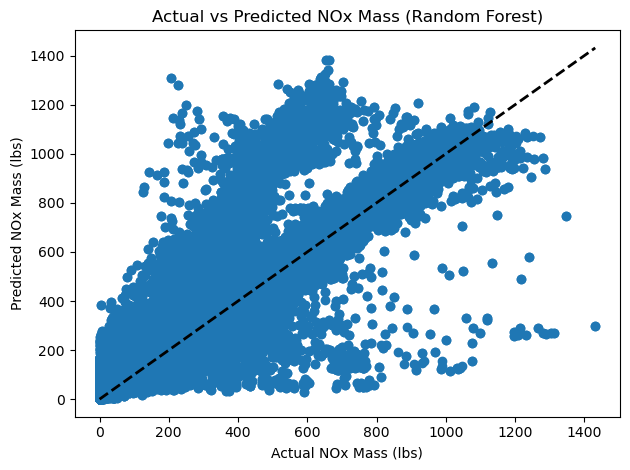

In [ ]:
# default model (no lags, no unmeasured data, with temps)

# rf model trained on 50% sampled train data

y_pred = rf_model_no_lags.predict(X_test)

# Set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (Random Forest)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

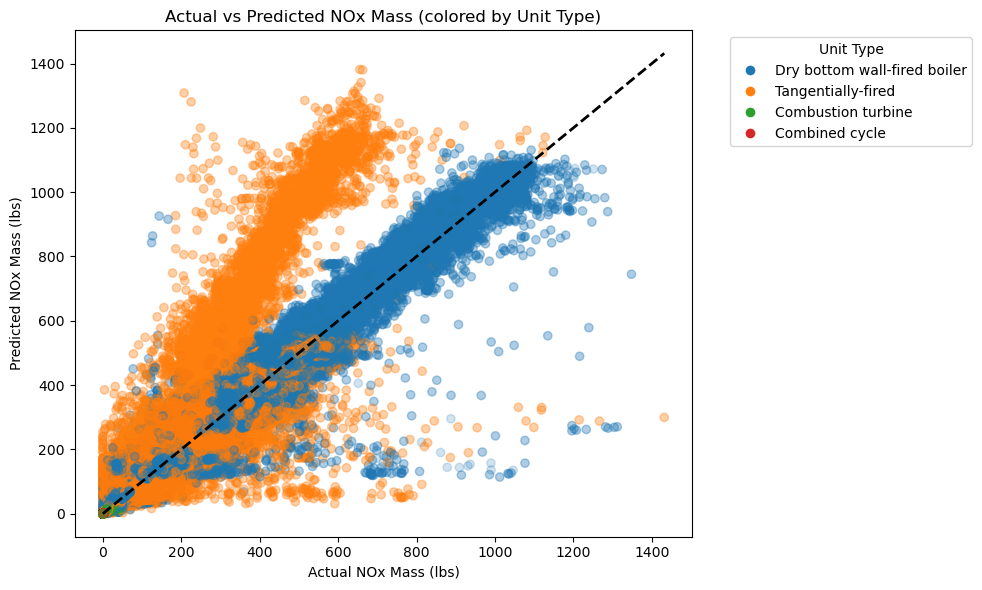

In [124]:
train_mask = (campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())
test_mask = (campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())

unit_types_test = campd_df.loc[test_mask, "Unit Type"].reset_index(drop=True)

y_test = pd.Series(y_test).reset_index(drop=True)
y_pred = pd.Series(y_pred).reset_index(drop=True)

unique_unit_types = unit_types_test.unique()
palette = sns.color_palette("tab10", len(unique_unit_types))  
color_mapping = dict(zip(unique_unit_types, palette))
colors = unit_types_test.map(color_mapping)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(y_test, y_pred, c=colors, alpha=0.2)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (colored by Unit Type)")
plt.plot(
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    'k--', lw=2
)

handles = [plt.Line2D([0], [0], marker='o', color='w', label=ut,
                      markerfacecolor=color_mapping[ut], markersize=8)
           for ut in unique_unit_types]
plt.legend(handles=handles, title="Unit Type", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()




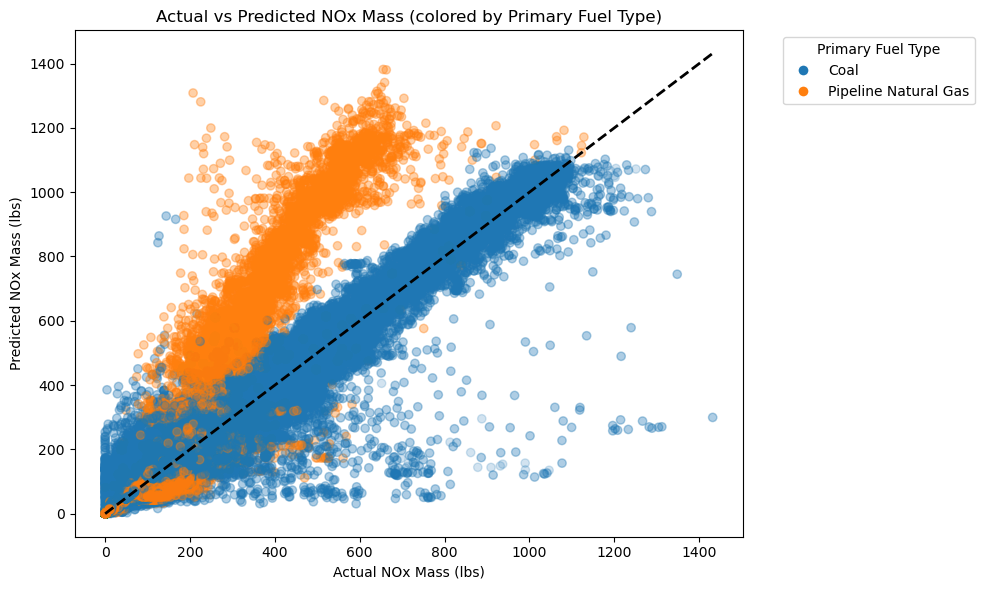

In [ ]:
train_mask = (campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())
test_mask = (campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())

fuel_types_test = campd_df.loc[test_mask, "Primary Fuel Type"].reset_index(drop=True)

y_test = pd.Series(y_test).reset_index(drop=True)
y_pred = pd.Series(y_pred).reset_index(drop=True)

unique_fuel_types = fuel_types_test.unique()
palette = sns.color_palette("tab10", len(unique_fuel_types))  
color_mapping = dict(zip(unique_fuel_types, palette))
colors = fuel_types_test.map(color_mapping)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(y_test, y_pred, c=colors, alpha=0.2)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (colored by Primary Fuel Type)")
plt.plot(
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    'k--', lw=2
)

handles = [plt.Line2D([0], [0], marker='o', color='w', label=ut,
                      markerfacecolor=color_mapping[ut], markersize=8)
           for ut in unique_fuel_types]
plt.legend(handles=handles, title="Primary Fuel Type", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

In [ ]:
rf_model_with_lags = joblib.load("WY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_wy_with_lags_with_unmeasured_with_temps.json")

In [ ]:
# downsample the training data to 50%
X_sampled, y_sampled = (
    X_train.sample(frac=0.5, random_state=42),
    y_train.loc[X_train.sample(frac=0.5, random_state=42).index]
)
X_sampled.shape

(1053450, 113)

In [ ]:
# took approx. 15 mins to compute (50% sample)

rf_model_with_lags = RandomForestRegressor(random_state=42, n_jobs=-1)

# Train Random Forest model with default parameters
rf_model_with_lags.fit(X_sampled, y_sampled.values.ravel())

RandomForestRegressor(n_jobs=-1, random_state=42)

In [144]:
joblib.dump(rf_model_with_lags, "WY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_wy_with_lags_with_unmeasured_with_temps.json", compress=True)

['WY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_wy_with_lags_with_unmeasured_with_temps.json']

In [ ]:
rf_model_with_lags = joblib.load("WY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_wy_with_lags_with_unmeasured_with_temps.json")

R^2 Score: 0.9865
Mean Squared Error (MSE): 625.4343
Root Mean Squared Error (RMSE): 25.0087
Normalized RMSE (by std): 0.1161


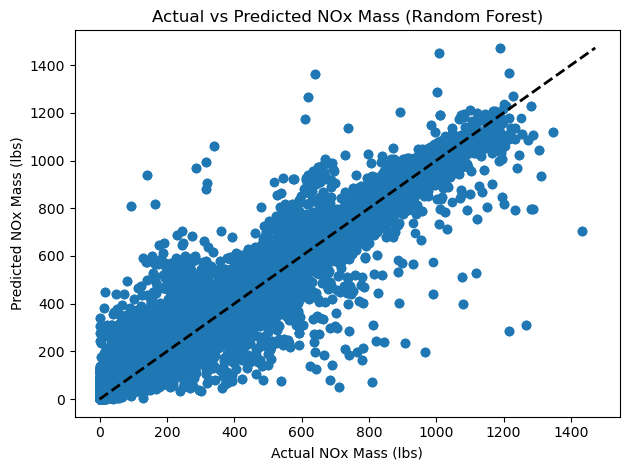

In [ ]:
# default model (with lags, no unmeasured data, with temps)

# using loaded model

y_pred = rf_model_with_lags.predict(X_test)

# Set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

# Evaluate performance
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

# Plot actual vs predicted
plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (Random Forest)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

<h3>MLP</h3>

In [4]:
campd_df = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/wy_2019_2024_complete_cleaned_Full_manually_encoded", dtype=campd_type_dict)

In [ ]:
df_control_cols = ['Dry Low NOx Burners', 'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Overfire Air',
       'Selective Catalytic Reduction',
       'Selective Catalytic Reduction (Began Jun 27, 2019)',
       'Selective Non-catalytic Reduction']
df_code_cols = ['ARP', 'MATS']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]
# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ]

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) #+ lag_cols #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

numeric_imputer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', numeric_imputer, num_features), # scale since MLPs are very sensitive to scale + impute using median (NN cannot handle nans)
        ('encoded', 'passthrough', encoded_cat_features) 
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [26]:
mlp_default_model = MLPRegressor(random_state=42)

In [38]:
X_train.shape

(2106900, 106)

In [ ]:
mlp_default_model.fit(X_train, y_train)

# using the full training data, this took 37mins

joblib.dump(mlp_default_model, "WY/Hourly/Concatted File/Modeling/MLP/NOx/Trained Models/mlp_default_model_wy_no_lags_with_unmeasured_with_temps.json", compress=True)

mlp_default_model.score(X_test, y_test) # note that this still allows predictions < 0

In [47]:
mlp_default_model = joblib.load("WY/Hourly/Concatted File/Modeling/MLP/NOx/Trained Models/mlp_default_model_wy_no_lags_with_unmeasured_with_temps.json")

In [48]:
y_pred = mlp_default_model.predict(X_test)

R^2 Score: 0.8925
Mean Squared Error (MSE): 4988.0603
Root Mean Squared Error (RMSE): 70.6262
Normalized RMSE (by std): 0.3279


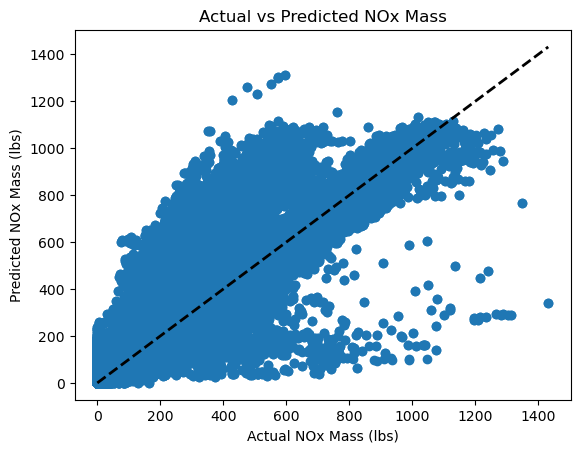

In [ ]:
# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h3>XGBoost</h3>

<h5>Preprocessing Methods</h5>

In [3]:
# manually create lag columns
def create_lag_features_per_group(group, emission_type):
    group["lag_1_hour"] = group[emission_type].shift(1)  # 1 hour lag
    group["lag_2_hours"] = group[emission_type].shift(2)  # 2 hours lag
    group["lag_1_day"] = group[emission_type].shift(24)  # 1 day lag (24 hours)
    group["lag_2_days"] = group[emission_type].shift(48)  # 2 days lag (48 hours)
    group["lag_1_week"] = group[emission_type].shift(24 * 7)  # 1 week lag (168 hours)
    group["lag_1_month"] = group[emission_type].shift(24 * 30)  # ~1 month lag (720 hours)
    group["lag_1_year"] = group[emission_type].shift(24 * 365)  # ~1 year lag (8760 hours)
    return group

def preprocess_lag_features(df, previous_year_df, emission_type):
    cutoff_year = df["Year"].min()

    # Combine the two dfs
    df = pd.concat([df, previous_year_df])

    # Set datetime as the index for time-series operations
    df = df.set_index("datetime")

    # Sort the DataFrame by the datetime index to ensure proper alignment
    df = df.sort_index()

    # Sort the DataFrame by Facility ID, Unit ID, and datetime to ensure proper alignment
    df = df.sort_values(by=["Facility ID", "Unit ID", "datetime"])

    # Apply the lag feature function to each group
    df = df.groupby(["Facility ID", "Unit ID"], group_keys=False).apply(
    create_lag_features_per_group, emission_type=emission_type)

    df = df.reset_index()

    # Filter out the previous year again
    df = df[df["Year"] >= cutoff_year]

    # ensure to add datetime back as normal column
    df["datetime"] = pd.to_datetime(df["Date"].astype(str) + ' ' + df["Hour"].astype(str).str.zfill(2) + ":00:00")


    return df


In [4]:
# manually one-hot encode NOx Controls
def split_outside_parentheses(s):
    parts = []
    current = []
    depth = 0  # track parentheses depth

    for char in s:
        if char == '(':
            depth += 1
        elif char == ')':
            depth = max(depth - 1, 0)
        
        # Split on ',' or '|' only if outside parentheses
        if (char == ',' or char == '|') and depth == 0:
            part = ''.join(current).strip()
            if part:
                parts.append(part)
            current = []
        else:
            current.append(char)
    
    # Append last part
    part = ''.join(current).strip()
    if part:
        parts.append(part)
    
    return parts

# function for one-hot encoding NOx Controls
def preprocess_nox_controls(df):
    df = df.copy()
    df = df.dropna(subset=['NOx Controls'])
    
    # Apply custom splitting
    control_lists = df['NOx Controls'].apply(split_outside_parentheses)
    
    # One-hot encode controls
    mlb = MultiLabelBinarizer()
    control_matrix = mlb.fit_transform(control_lists)
    
    # Create a DataFrame from the binary matrix
    controls_df = pd.DataFrame(control_matrix, columns=mlb.classes_, index=df.index)
    
    df = df.drop(columns=['NOx Controls'])
    df = pd.concat([df, controls_df], axis=1)
    
    return df, mlb.classes_  # return control column names for later use

# campd_wy, wy_control_cols = preprocess_nox_controls(campd_wy)
# wy_control_cols

In [5]:
# manually one-hot encode Program Codes
def preprocess_program_codes(df):

    # Split the strings into lists
    program_lists = df['Program Code'].str.split(', ')

    mlb = MultiLabelBinarizer()
    program_dummies = pd.DataFrame(mlb.fit_transform(program_lists), 
                                columns=mlb.classes_, 
                                index=df.index)

    # Concatenate with original DataFrame or add to your features
    df = pd.concat([df, program_dummies], axis=1)

    return df, mlb.classes_


# campd_wy, wy_code_cols = preprocess_program_codes(campd_wy)
# wy_code_cols

<h5>Actual Preprocessing</h5>

In [18]:
campd_wy["Day"] = campd_wy["datetime"].dt.day

In [24]:
# read in previous year to get according lags
campd_wy_2018 = pd.read_csv("WY/Hourly/Before 2019/emissions-hourly-2018-wy.csv", dtype=campd_type_dict, date_format=["Date"])
campd_wy_2018 = campd_wy_2018[["Facility ID", "Unit ID", "Date", "Hour", "NOx Mass (lbs)"]]
campd_wy_2018["datetime"] = pd.to_datetime(campd_wy_2018["Date"].astype(str) + ' ' + campd_wy_2018["Hour"].astype(str).str.zfill(2) + ":00:00")
campd_wy_2018["NOx Mass (lbs)"] = campd_wy_2018["NOx Mass (lbs)"].fillna(0)

# compute lags
campd_df = preprocess_lag_features(campd_wy, campd_wy_2018, "NOx Mass (lbs)")

In [26]:
campd_df.to_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/wy_2019_2024_complete_cleaned_Full_with_NOx_lags.csv", index=False)

In [ ]:
campd_df = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/wy_2019_2024_complete_cleaned_Full_with_NOx_lags.csv", dtype=campd_type_dict)
campd_df["Date"] = pd.to_datetime(campd_df["Date"])
campd_df["datetime"] = pd.to_datetime(campd_df["datetime"])

In [27]:
# manually one-hot encode nox controls and program codes
campd_df, df_control_cols = preprocess_nox_controls(campd_df)
campd_df, df_code_cols = preprocess_program_codes(campd_df)

# manually sin/cos encode cyclical features hour, day, month
def encode_cyclical(df, col, max_val):
    df[f"{col}_sin"] = np.sin(2 * np.pi * df[col] / max_val)
    df[f"{col}_cos"] = np.cos(2 * np.pi * df[col] / max_val)
    col_names = [f"{col}_sin", f"{col}_cos"]
    return df, col_names
campd_df, hour_cols = encode_cyclical(campd_df, "Hour", 24) # Daily seasonality
campd_df, day_cols = encode_cyclical(campd_df, "Day", 7)  # Weekly seasonality
campd_df, month_cols = encode_cyclical(campd_df, "Month", 12) # Yearly seasonality
cyclical_cols = hour_cols + day_cols + month_cols

In [28]:
campd_df.to_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/wy_2019_2024_complete_cleaned_Full_manually_encoded", index=False)

In [41]:
campd_df = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/wy_2019_2024_complete_cleaned_Full_manually_encoded", dtype=campd_type_dict)

skip downsampling, file size is not a constraint here

In [43]:
campd_df["NOx Mass Measure Indicator"].value_counts()

NOx Mass Measure Indicator
Calculated    1925653
Nothing        617044
Name: count, dtype: Int64

In [ ]:
df_control_cols = ['Dry Low NOx Burners', 'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Overfire Air',
       'Selective Catalytic Reduction',
       'Selective Catalytic Reduction (Began Jun 27, 2019)',
       'Selective Non-catalytic Reduction']
df_code_cols = ['ARP', 'MATS']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

In [ ]:
# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ]

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) #+ lag_cols #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (NOx Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan


ColumnTransformer(transformers=[('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['Month', 'Hour', 'Day', 'Source Category',
                                  'NOx Phase', 'Unit Type', 'Primary Fuel Type',
                                  'Secondary Fuel Type']),
                                ('num', 'passthrough',
                                 ['Gross Load (MW)', 'Heat Input (mmBtu)',
                                  'Latitude', 'Longitude',
                                  'Nameplate Capacity (MWe)',
                                  'hourly_capacity_factor',
                                  'hourly_ramping_facto...
                                ('encoded', 'passthrough',
                                 ['Dry Low NOx Burners',
                                  'Low NOx Burner Technology (Dry Bottom only)',
                                  'Low NOx Burner Technology w/ Closed-coupled '
                                  'OFA',
                                  'Low NOx Burner Technology w/ Overfire Air',
                                  'Low NOx Burner Technology w/ Separated OFA',
                                  'Nothing', 'Overfire Air',
                                  'Selective Catalytic Reduction',
                                  'Selective Catalytic Reduction (Began Jun '
                                  '27, 2019)',
                                  'Selective Non-catalytic Reduction', 'ARP',
                                  'MATS'])])

In [16]:
X_train.to_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_train", index=False)
X_test.to_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_test", index=False)
y_train.to_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/y_train", index=False)
y_test.to_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/y_test", index=False)

In [ ]:
X_train = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_train", dtype=campd_type_dict)
X_test = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_test", dtype=campd_type_dict)

In [ ]:
y_train = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/y_train")
y_test = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/y_test")

In [ ]:
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [18]:
X_train.to_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed", index=False)
X_test.to_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed", index=False)

In [58]:
X_train = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed", dtype=campd_type_dict)
X_test = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed", dtype=campd_type_dict)

In [7]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

In [20]:
dtrain.save_binary("WY/Hourly/Concatted File/Modeling/XGB/NOx/dtrain_wy_full_2019_2023.buffer")
dtest.save_binary("WY/Hourly/Concatted File/Modeling/XGB/NOx/dtest_wy_full_2024.buffer")

In [130]:
dtrain = xgb.DMatrix("WY/Hourly/Concatted File/Modeling/XGB/NOx/dtrain_wy_full_2019_2023.buffer")
dtest = xgb.DMatrix("WY/Hourly/Concatted File/Modeling/XGB/NOx/dtest_wy_full_2024.buffer")

In [22]:
# default parameters for comparison
default_params = {
    # "n_estimators": 100, # number of trees (larger value, more likely to overfit)
    # "max_depth":  6, # max depth of a tree (larger value, more complex, more likely to overfit)
    # "learning_rate": 0.5, # step size shrinkage eta (lower value, more conservative)
    # "subsample": 1, # random subset size of data to use for each tree (lower value, more conservative)
    # "colsample_bytree": 1, # random subset of features to consider for each tree (lower value, more conservative)
    # "gamma": 0, # min loss reduction to make a split (larger value, more conservative)
    # "reg_alpha": 0, # L1 regularization on weights (larger value, more conservative)
    # "reg_lambda": 1, # L2 regularization on weights (larger value, more conservative)
    # "min_child_weight": 1, # min sum of instance weight (hessian) needed in a child (larger value, more conservative)
    # "tree_method": "auto" # automatically chooses exact or approximation method based on data size

    # needed params for xgb.train
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
    #"tree_method": "auto", # uses approximation for large datasets
    #"device": "cuda", # use gpu (if unavailable, will use cpu)
    'seed': 42 # like random_state, but for xgb.train
}

<h5>WY Only</h5>

R^2 Score: 0.9043
Mean Squared Error (MSE): 4439.2427
Root Mean Squared Error (RMSE): 66.6276
Normalized RMSE (by std): 0.3093


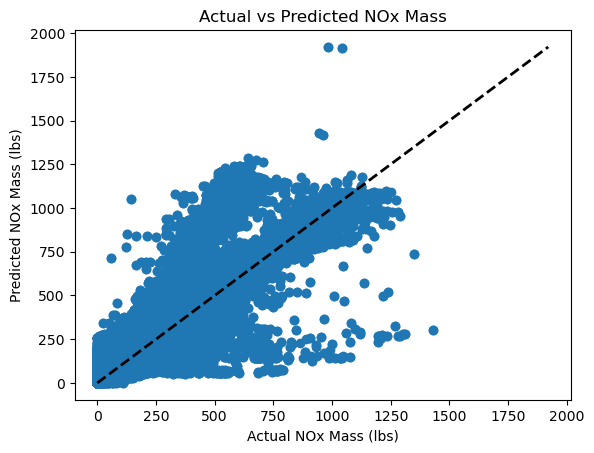

In [ ]:
# model with default parameters (no lags, no unmeasured data, with temps)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
xgb_default_model.save_model("WY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_wy_no_lags_with_unmeasured_with_temps.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

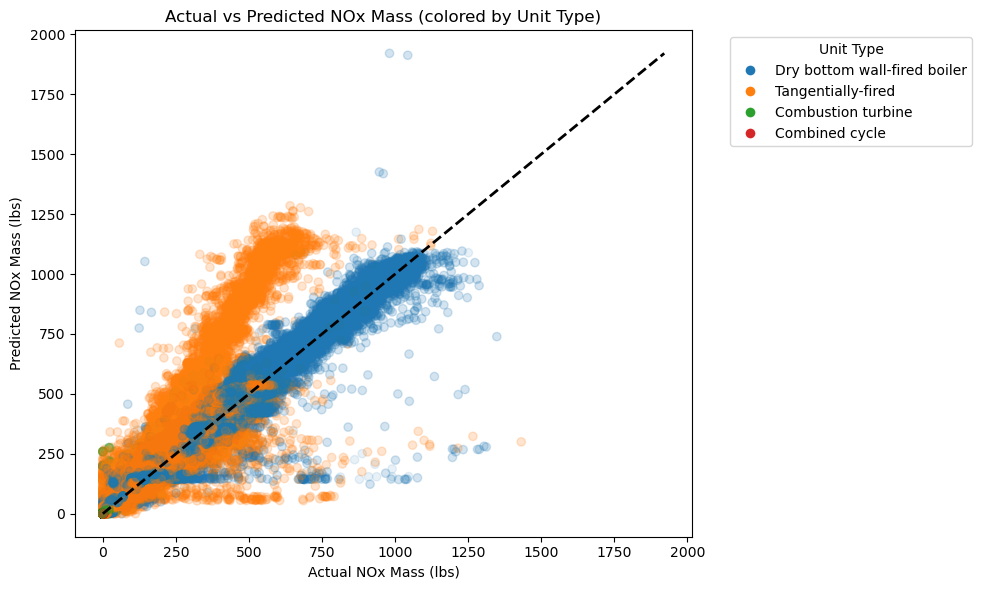

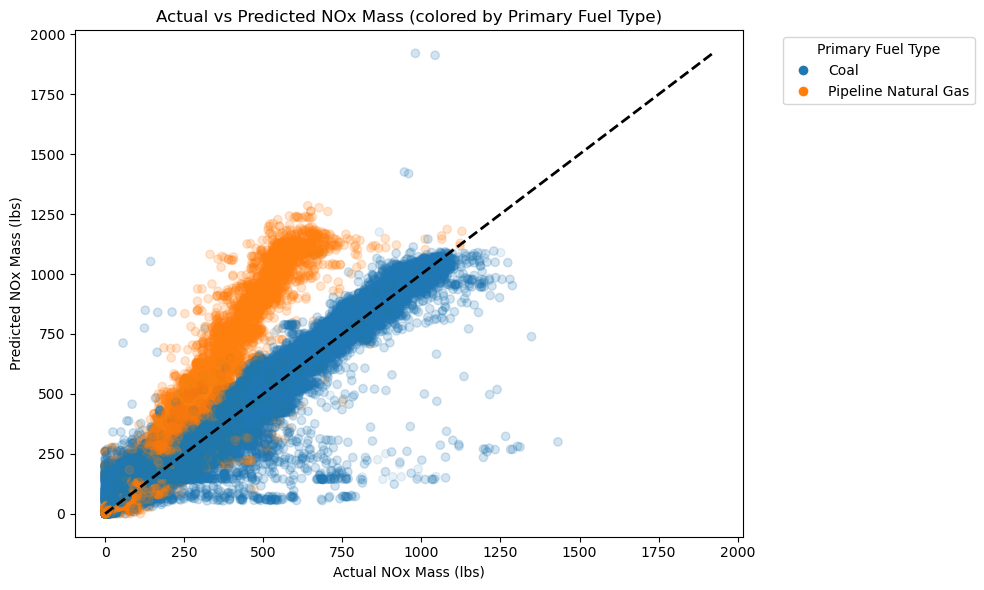

In [19]:
train_mask = (campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())
test_mask = (campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())

unit_types_test = campd_df.loc[test_mask, "Unit Type"].reset_index(drop=True)

y_test = pd.Series(y_test).reset_index(drop=True)
y_pred = pd.Series(y_pred).reset_index(drop=True)

unique_unit_types = unit_types_test.unique()
palette = sns.color_palette("tab10", len(unique_unit_types))  
color_mapping = dict(zip(unique_unit_types, palette))
colors = unit_types_test.map(color_mapping)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(y_test, y_pred, c=colors, alpha=0.1)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (colored by Unit Type)")
plt.plot(
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    'k--', lw=2
)

handles = [plt.Line2D([0], [0], marker='o', color='w', label=ut,
                      markerfacecolor=color_mapping[ut], markersize=8)
           for ut in unique_unit_types]
plt.legend(handles=handles, title="Unit Type", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

#####################################################

train_mask = (campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())
test_mask = (campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())

fuel_types_test = campd_df.loc[test_mask, "Primary Fuel Type"].reset_index(drop=True)

y_test = pd.Series(y_test).reset_index(drop=True)
y_pred = pd.Series(y_pred).reset_index(drop=True)

unique_fuel_types = fuel_types_test.unique()
palette = sns.color_palette("tab10", len(unique_fuel_types))  
color_mapping = dict(zip(unique_fuel_types, palette))
colors = fuel_types_test.map(color_mapping)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(y_test, y_pred, c=colors, alpha=0.1)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (colored by Primary Fuel Type)")
plt.plot(
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    'k--', lw=2
)

handles = [plt.Line2D([0], [0], marker='o', color='w', label=ut,
                      markerfacecolor=color_mapping[ut], markersize=8)
           for ut in unique_fuel_types]
plt.legend(handles=handles, title="Primary Fuel Type", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()




In [66]:
pd.set_option('display.float_format', '{:,.2f}'.format)
print(campd_nd.groupby(by="Unit Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))
print("")
print(campd_nd.groupby(by="Primary Fuel Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))


Unit Type
Cyclone boiler                              212,893,248.00
Tangentially-fired                          117,202,432.00
Dry bottom wall-fired boiler                 10,316,772.00
Bubbling fluidized bed boiler                 6,133,157.50
Circulating fluidized bed boiler              2,415,501.75
Combustion turbine                            1,230,774.75
Combustion turbine (Started Aug 04, 2021)         1,057.01
Name: NOx Mass (lbs), dtype: float32

Primary Fuel Type
Coal                   348,961,120.00
Pipeline Natural Gas     1,231,831.75
Name: NOx Mass (lbs), dtype: float32


In [28]:
pd.set_option('display.float_format', '{:,.2f}'.format)
print(campd_df.groupby(by="Unit Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))
print("")
print(campd_df.groupby(by="Primary Fuel Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))


Unit Type
Dry bottom wall-fired boiler   353,806,176.00
Tangentially-fired             227,806,976.00
Combustion turbine                 665,021.12
Combined cycle                     262,930.84
Name: NOx Mass (lbs), dtype: float32

Primary Fuel Type
Coal                         568,704,192.00
Pipeline Natural Gas          12,357,907.00
Coal, Pipeline Natural Gas     1,478,991.12
Name: NOx Mass (lbs), dtype: float32


R^2 Score: 0.9858
Mean Squared Error (MSE): 659.2536
Root Mean Squared Error (RMSE): 25.6759
Normalized RMSE (by std): 0.1192


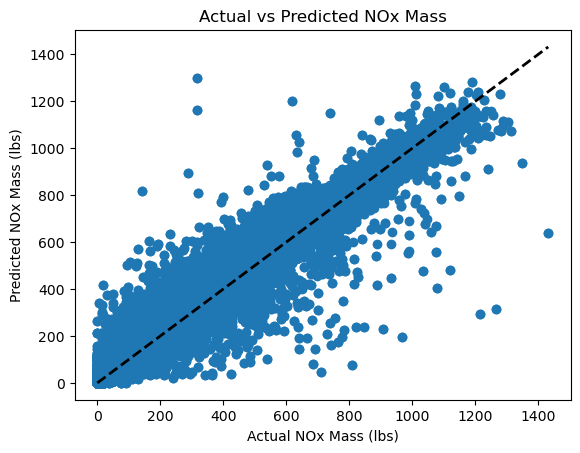

In [131]:
# model with default parameters (with lags, no unmeasured data, with temps)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
xgb_default_model.save_model("WY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_wy_with_lags_with_unmeasured_with_temps.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h5>WY + NY/TX</h5>

In [3]:
campd_wy = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/wy_2019_2024_complete_cleaned_Full_manually_encoded", dtype=campd_type_dict)
campd_wy["State"] = "WY"

In [4]:
campd_ny = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured", dtype=campd_type_dict)
campd_ny["State"] = "NY"

In [26]:
campd_tx = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/tx_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured", dtype=campd_type_dict)
campd_tx["State"] = "TX"

In [32]:
pd.set_option('display.float_format', '{:,.2f}'.format)

print("NY")
print(campd_ny[campd_ny["Unit Type"] == "Tangentially-fired"]["NOx Mass (lbs)"].describe())
print("")
print("TX")
print(campd_tx[campd_tx["Unit Type"] == "Tangentially-fired"]["NOx Mass (lbs)"].describe())
print("")
print("WY")
print(campd_wy[campd_wy["Unit Type"] == "Tangentially-fired"]["NOx Mass (lbs)"].describe())

NY
count   376,950.00
mean         76.48
std         124.22
min           0.00
25%           0.00
50%          29.10
75%         105.90
max       2,077.60
Name: NOx Mass (lbs), dtype: float64

TX
count   1,405,384.00
mean          362.67
std           333.52
min             0.00
25%            85.20
50%           283.80
75%           546.40
max         4,931.00
Name: NOx Mass (lbs), dtype: float64

WY
count   775,884.00
mean        293.61
std         260.69
min           0.00
25%         105.25
50%         244.33
75%         415.67
max       2,588.83
Name: NOx Mass (lbs), dtype: float64


In [ ]:
campd_wy_ny = pd.concat([campd_wy, campd_ny[(campd_ny["Year"] < 2024) & (campd_ny["Unit Type"] == "Tangentially-fired")]])
campd_wy_ny = campd_wy_ny.fillna(0)

In [53]:
campd_wy_tx = pd.concat([campd_wy, campd_tx[(campd_tx["Year"] < 2024) & (campd_tx["Unit Type"] == "Tangentially-fired")]])
campd_wy_tx = campd_wy_tx.fillna(0)

In [46]:
campd_wy_tx = campd_wy_tx[campd_wy_tx["Unit Type"] == "Tangentially-fired"]


In [54]:
df_control_cols = ['Dry Low NOx Burners', 'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Overfire Air',
       'Selective Catalytic Reduction',
       'Selective Catalytic Reduction (Began Jun 27, 2019)',
       'Selective Non-catalytic Reduction']
df_code_cols = ['ARP', 'MATS']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ]

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) #+ lag_cols #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_wy_tx = campd_wy_tx.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024 (only test on WY data)
X_train = campd_wy_tx[(campd_wy_tx["Year"] < 2024) & (campd_wy_tx["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_wy_tx[(campd_wy_tx["Year"] < 2024) & (campd_wy_tx["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_wy_tx[(campd_wy_tx["State"] == "WY") & (campd_wy_tx["Year"] == 2024) & (campd_wy_tx["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_wy_tx[(campd_wy_tx["State"] ==  "WY") & (campd_wy_tx["Year"] == 2024) & (campd_wy_tx["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (NOx Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan


ColumnTransformer(transformers=[('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['Month', 'Hour', 'Day', 'Source Category',
                                  'NOx Phase', 'Unit Type', 'Primary Fuel Type',
                                  'Secondary Fuel Type']),
                                ('num', 'passthrough',
                                 ['Gross Load (MW)', 'Heat Input (mmBtu)',
                                  'Latitude', 'Longitude',
                                  'Nameplate Capacity (MWe)',
                                  'hourly_capacity_factor',
                                  'hourly_ramping_facto...
                                ('encoded', 'passthrough',
                                 ['Dry Low NOx Burners',
                                  'Low NOx Burner Technology (Dry Bottom only)',
                                  'Low NOx Burner Technology w/ Closed-coupled '
                                  'OFA',
                                  'Low NOx Burner Technology w/ Overfire Air',
                                  'Low NOx Burner Technology w/ Separated OFA',
                                  'Nothing', 'Overfire Air',
                                  'Selective Catalytic Reduction',
                                  'Selective Catalytic Reduction (Began Jun '
                                  '27, 2019)',
                                  'Selective Non-catalytic Reduction', 'ARP',
                                  'MATS'])])

In [55]:
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

R^2 Score: 0.9064
Mean Squared Error (MSE): 4343.8394
Root Mean Squared Error (RMSE): 65.9078
Normalized RMSE (by std): 0.3060


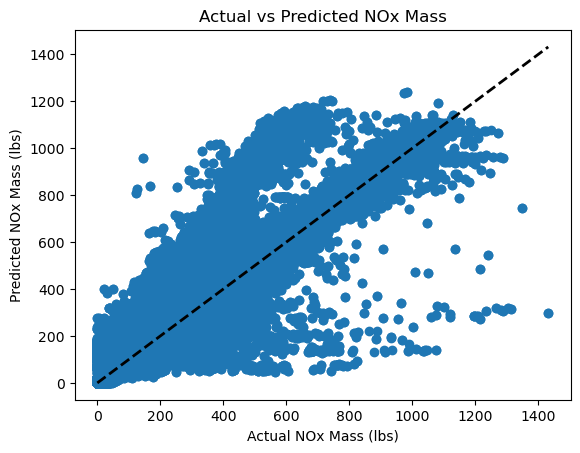

In [ ]:
# model with default parameters (no lags, no unmeasured data, with temps)

# with TX (TF) data

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
#xgb_default_model.save_model("WY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_wy_no_lags_with_unmeasured_with_temps.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

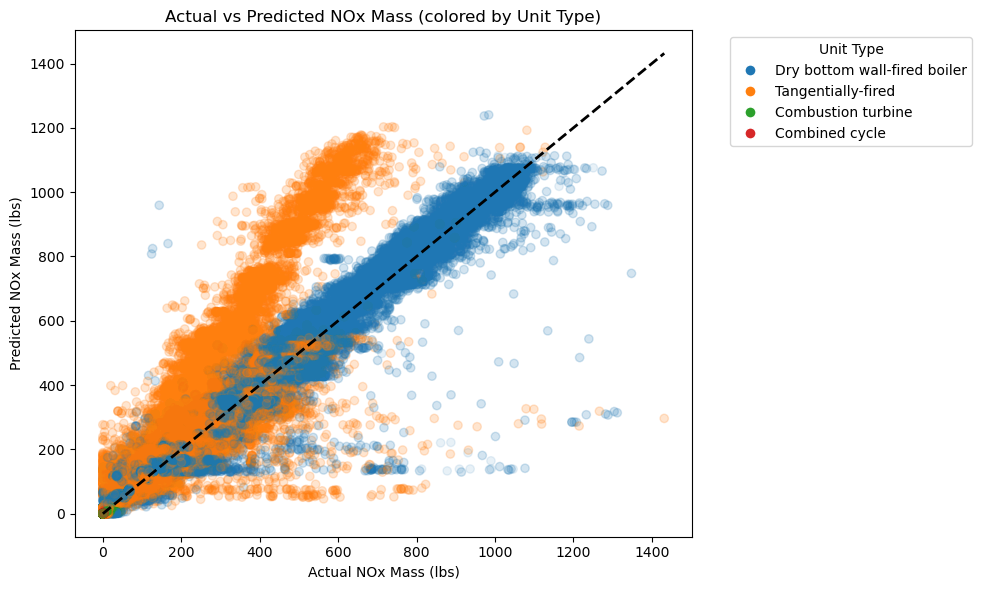

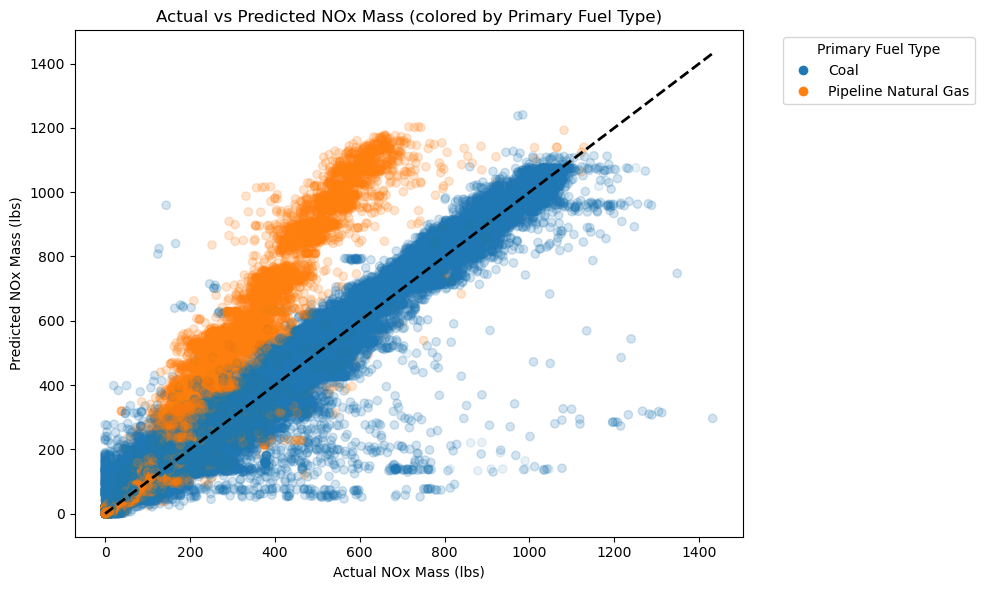

In [57]:
train_mask = (campd_wy_tx["Year"] < 2024) & (campd_wy_tx["NOx Mass (lbs)"].notna())
test_mask = (campd_wy_tx["Year"] == 2024) & (campd_wy_tx["NOx Mass (lbs)"].notna())

unit_types_test = campd_wy_tx.loc[test_mask, "Unit Type"].reset_index(drop=True)

y_test = pd.Series(y_test).reset_index(drop=True)
y_pred = pd.Series(y_pred).reset_index(drop=True)

unique_unit_types = unit_types_test.unique()
palette = sns.color_palette("tab10", len(unique_unit_types))  
color_mapping = dict(zip(unique_unit_types, palette))
colors = unit_types_test.map(color_mapping)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(y_test, y_pred, c=colors, alpha=0.1)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (colored by Unit Type)")
plt.plot(
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    'k--', lw=2
)

handles = [plt.Line2D([0], [0], marker='o', color='w', label=ut,
                      markerfacecolor=color_mapping[ut], markersize=8)
           for ut in unique_unit_types]
plt.legend(handles=handles, title="Unit Type", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

#####################################################

train_mask = (campd_wy_tx["Year"] < 2024) & (campd_wy_tx["NOx Mass (lbs)"].notna())
test_mask = (campd_wy_tx["Year"] == 2024) & (campd_wy_tx["NOx Mass (lbs)"].notna())

fuel_types_test = campd_wy_tx.loc[test_mask, "Primary Fuel Type"].reset_index(drop=True)

y_test = pd.Series(y_test).reset_index(drop=True)
y_pred = pd.Series(y_pred).reset_index(drop=True)

unique_fuel_types = fuel_types_test.unique()
palette = sns.color_palette("tab10", len(unique_fuel_types))  
color_mapping = dict(zip(unique_fuel_types, palette))
colors = fuel_types_test.map(color_mapping)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(y_test, y_pred, c=colors, alpha=0.1)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (colored by Primary Fuel Type)")
plt.plot(
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    'k--', lw=2
)

handles = [plt.Line2D([0], [0], marker='o', color='w', label=ut,
                      markerfacecolor=color_mapping[ut], markersize=8)
           for ut in unique_fuel_types]
plt.legend(handles=handles, title="Primary Fuel Type", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()




In [12]:
pd.set_option('display.float_format', '{:,.2f}'.format)
print(campd_wy.groupby(by="Unit Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))
print("\n",campd_wy_ny.groupby(by="Unit Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))

Unit Type
Dry bottom wall-fired boiler   353,806,176.00
Tangentially-fired             227,806,976.00
Combustion turbine                 665,021.12
Combined cycle                     262,930.84
Name: NOx Mass (lbs), dtype: float32

 Unit Type
Dry bottom wall-fired boiler   353,806,176.00
Tangentially-fired             251,940,160.00
Combustion turbine                 665,021.12
Combined cycle                     262,930.84
Name: NOx Mass (lbs), dtype: float32


In [19]:

df_control_cols = ['Dry Low NOx Burners', 'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Overfire Air',
       'Selective Catalytic Reduction',
       'Selective Catalytic Reduction (Began Jun 27, 2019)',
       'Selective Non-catalytic Reduction']
df_code_cols = ['ARP', 'MATS']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ]

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) #+ lag_cols #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_wy_ny = campd_wy_ny.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024 (only test on WY data)
X_train = campd_wy_ny[(campd_wy_ny["Year"] < 2024) & (campd_wy_ny["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_wy_ny[(campd_wy_ny["Year"] < 2024) & (campd_wy_ny["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_wy_ny[(campd_wy_ny["State"] == "WY") & (campd_wy_ny["Year"] == 2024) & (campd_wy_ny["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_wy_ny[(campd_wy_ny["State"] ==  "WY") & (campd_wy_ny["Year"] == 2024) & (campd_wy_ny["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (NOx Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan


ColumnTransformer(transformers=[('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['Month', 'Hour', 'Day', 'Source Category',
                                  'NOx Phase', 'Unit Type', 'Primary Fuel Type',
                                  'Secondary Fuel Type']),
                                ('num', 'passthrough',
                                 ['Gross Load (MW)', 'Heat Input (mmBtu)',
                                  'Latitude', 'Longitude',
                                  'Nameplate Capacity (MWe)',
                                  'hourly_capacity_factor',
                                  'hourly_ramping_facto...
                                ('encoded', 'passthrough',
                                 ['Dry Low NOx Burners',
                                  'Low NOx Burner Technology (Dry Bottom only)',
                                  'Low NOx Burner Technology w/ Closed-coupled '
                                  'OFA',
                                  'Low NOx Burner Technology w/ Overfire Air',
                                  'Low NOx Burner Technology w/ Separated OFA',
                                  'Nothing', 'Overfire Air',
                                  'Selective Catalytic Reduction',
                                  'Selective Catalytic Reduction (Began Jun '
                                  '27, 2019)',
                                  'Selective Non-catalytic Reduction', 'ARP',
                                  'MATS'])])

In [20]:
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

R^2 Score: 0.8808
Mean Squared Error (MSE): 5531.6401
Root Mean Squared Error (RMSE): 74.3750
Normalized RMSE (by std): 0.3453


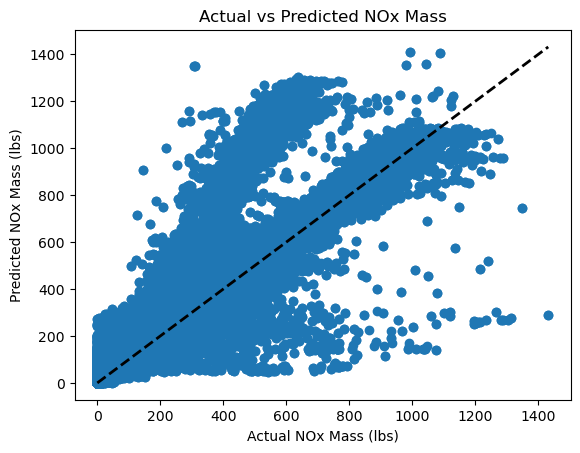

In [ ]:
# model with default parameters (no lags, no unmeasured data, with temps)

# with NY TF data

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
#xgb_default_model.save_model("WY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_wy_no_lags_with_unmeasured_with_temps.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h5>WY + ND + MT</h5>

In [ ]:
# additional datasets
campd_nd["Day"] = campd_nd["datetime"].dt.day

# read in previous year to get according lags
campd_nd_2018 = pd.read_csv("ND/Hourly/Before 2019/emissions-hourly-2018-nd.csv", dtype=campd_type_dict, date_format=["Date"])
campd_nd_2018 = campd_nd_2018[["Facility ID", "Unit ID", "Date", "Hour", "NOx Mass (lbs)"]]
campd_nd_2018["datetime"] = pd.to_datetime(campd_nd_2018["Date"].astype(str) + ' ' + campd_nd_2018["Hour"].astype(str).str.zfill(2) + ":00:00")
campd_nd_2018["NOx Mass (lbs)"] = campd_nd_2018["NOx Mass (lbs)"].fillna(0)

# compute lags
campd_nd = preprocess_lag_features(campd_nd, campd_nd_2018, "NOx Mass (lbs)")

campd_nd.to_csv("ND/Hourly/Concatted File/Modeling/XGB/NOx/nd_2019_2024_complete_cleaned_Full_with_NOx_lags.csv", index=False)

campd_nd["Date"] = pd.to_datetime(campd_nd["Date"])
campd_nd["datetime"] = pd.to_datetime(campd_nd["datetime"])

# manually one-hot encode nox controls and program codes
campd_nd, nd_control_cols = preprocess_nox_controls(campd_nd)
campd_nd, nd_code_cols = preprocess_program_codes(campd_nd)

# manually sin/cos encode cyclical features hour, day, month
def encode_cyclical(df, col, max_val):
    df[f"{col}_sin"] = np.sin(2 * np.pi * df[col] / max_val)
    df[f"{col}_cos"] = np.cos(2 * np.pi * df[col] / max_val)
    col_names = [f"{col}_sin", f"{col}_cos"]
    return df, col_names
campd_nd, hour_cols = encode_cyclical(campd_nd, "Hour", 24) # Daily seasonality
campd_nd, day_cols = encode_cyclical(campd_nd, "Day", 7)  # Weekly seasonality
campd_nd, month_cols = encode_cyclical(campd_nd, "Month", 12) # Yearly seasonality
cyclical_cols = hour_cols + day_cols + month_cols

campd_nd.to_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/nd_2019_2024_complete_cleaned_Full_manually_encoded", index=False)

In [61]:
campd_nd["NOx Mass Measure Indicator"].value_counts() 

NOx Mass Measure Indicator
Calculated    710303
Name: count, dtype: Int64

In [15]:
nd_control_cols = ['Dry Low NOx Burners',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Nothing', 'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Water Injection']
nd_code_cols = ['ARP', 'MATS', 'NSPS4T']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

In [13]:
campd_nd = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/nd_2019_2024_complete_cleaned_Full_manually_encoded", dtype=campd_type_dict)

In [18]:
# features
num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)']

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(nd_control_cols) + list(nd_code_cols) + lag_cols #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_nd = campd_nd.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train_nd = campd_nd[(campd_nd["Year"] < 2024) & (campd_nd["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train_nd = campd_nd[(campd_nd["Year"] < 2024) & (campd_nd["NOx Mass (lbs)"].notna())][target_variable]  
X_test_nd = campd_nd[(campd_nd["Year"] == 2024) & (campd_nd["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test_nd = campd_nd[(campd_nd["Year"] ==  2024) & (campd_nd["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features 
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train_nd = preprocessor.fit_transform(X_train_nd)
X_test_nd = preprocessor.transform(X_test_nd)

X_train_nd.to_csv("ND/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed_nd", index=False)
X_test_nd.to_csv("ND/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed_nd", index=False)
y_train_nd.to_csv("ND/Hourly/Concatted File/Modeling/XGB/NOx/y_train_nd", index=False)
y_test_nd.to_csv("ND/Hourly/Concatted File/Modeling/XGB/NOx/y_test_nd", index=False)

In [21]:
# concat with wyoming data

encoded_lag_cols = [
    "encoded__lag_1_hour",
    "encoded__lag_2_hours",
    "encoded__lag_1_day",
    "encoded__lag_2_days",
    "encoded__lag_1_week",
    "encoded__lag_1_month",
    "encoded__lag_1_year"
       ]

X_train_wy = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed", dtype=campd_type_dict).drop(columns=encoded_lag_cols, axis=1)
X_test_wy = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed", dtype=campd_type_dict).drop(columns=encoded_lag_cols, axis=1)
y_train_wy = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/y_train", dtype=campd_type_dict)
y_test_wy = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/y_test", dtype=campd_type_dict)
X_train = pd.concat([X_train_nd.drop(columns=encoded_lag_cols, axis=1), X_train_wy])
X_test = pd.concat([X_test_nd.drop(columns=encoded_lag_cols, axis=1), X_test_wy])
y_train = pd.concat([y_train_nd, y_train_wy])
y_test = pd.concat([y_test_nd, y_test_wy])

In [25]:
# additional datasets
campd_mt["Day"] = campd_mt["datetime"].dt.day

# read in previous year to get according lags
campd_mt_2018 = pd.read_csv("MT/Hourly/Before 2019/emissions-hourly-2018-mt.csv", dtype=campd_type_dict, date_format=["Date"])
campd_mt_2018 = campd_mt_2018[["Facility ID", "Unit ID", "Date", "Hour", "NOx Mass (lbs)"]]
campd_mt_2018["datetime"] = pd.to_datetime(campd_mt_2018["Date"].astype(str) + ' ' + campd_mt_2018["Hour"].astype(str).str.zfill(2) + ":00:00")
campd_mt_2018["NOx Mass (lbs)"] = campd_mt_2018["NOx Mass (lbs)"].fillna(0)

# compute lags
campd_mt = preprocess_lag_features(campd_mt, campd_mt_2018, "NOx Mass (lbs)")

campd_mt.to_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/mt_2019_2024_complete_cleaned_Full_with_NOx_lags.csv", index=False)

campd_mt["Date"] = pd.to_datetime(campd_mt["Date"])
campd_mt["datetime"] = pd.to_datetime(campd_mt["datetime"])

# manually one-hot encode nox controls and program codes
campd_mt, mt_control_cols = preprocess_nox_controls(campd_mt)
campd_mt, mt_code_cols = preprocess_program_codes(campd_mt)

# manually sin/cos encode cyclical features hour, day, month
def encode_cyclical(df, col, max_val):
    df[f"{col}_sin"] = np.sin(2 * np.pi * df[col] / max_val)
    df[f"{col}_cos"] = np.cos(2 * np.pi * df[col] / max_val)
    col_names = [f"{col}_sin", f"{col}_cos"]
    return df, col_names
campd_mt, hour_cols = encode_cyclical(campd_mt, "Hour", 24) # Daily seasonality
campd_mt, day_cols = encode_cyclical(campd_mt, "Day", 7)  # Weekly seasonality
campd_mt, month_cols = encode_cyclical(campd_mt, "Month", 12) # Yearly seasonality
cyclical_cols = hour_cols + day_cols + month_cols

campd_mt.to_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/mt_2019_2024_complete_cleaned_Full_manually_encoded", index=False)

In [59]:
campd_mt = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/mt_2019_2024_complete_cleaned_Full_manually_encoded")

C:\Users\marce\AppData\Local\Temp\ipykernel_42056\2375018380.py:1: DtypeWarning: Columns (4,11,15,19,23) have mixed types. Specify dtype option on import or set low_memory=False.
  campd_mt = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/mt_2019_2024_complete_cleaned_Full_manually_encoded")


In [60]:
mt_control_cols = ['Dry Low NOx Burners', 'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Selective Catalytic Reduction', 'Water Injection']
mt_code_cols = ['ARP', 'MATS']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
]

In [61]:
# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                'Temperature (F)',
                 'Year']

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(mt_control_cols) + list(mt_code_cols) + lag_cols #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_mt = campd_mt.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train_mt = campd_mt[(campd_mt["Year"] < 2024) & (campd_mt["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train_mt = campd_mt[(campd_mt["Year"] < 2024) & (campd_mt["NOx Mass (lbs)"].notna())][target_variable]  
X_test_mt = campd_mt[(campd_mt["Year"] == 2024) & (campd_mt["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test_mt = campd_mt[(campd_mt["Year"] ==  2024) & (campd_mt["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features 
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan


ColumnTransformer(transformers=[('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['Month', 'Hour', 'Day', 'Source Category',
                                  'NOx Phase', 'Unit Type', 'Primary Fuel Type',
                                  'Secondary Fuel Type']),
                                ('num', 'passthrough',
                                 ['Gross Load (MW)', 'Heat Input (mmBtu)',
                                  'Latitude', 'Longitude',
                                  'Nameplate Capacity (MWe)',
                                  'hourly_capacity_factor',
                                  'hourly_ramping_facto...
                                  'Temperature (F)', 'Year']),
                                ('encoded', 'passthrough',
                                 ['Dry Low NOx Burners',
                                  'Low NOx Burner Technology (Dry Bottom only)',
                                  'Low NOx Burner Technology w/ Closed-coupled '
                                  'OFA',
                                  'Low NOx Burner Technology w/ '
                                  'Closed-coupled/Separated OFA',
                                  'Selective Catalytic Reduction',
                                  'Water Injection', 'ARP', 'MATS',
                                  'lag_1_hour', 'lag_2_hours', 'lag_1_day',
                                  'lag_2_days', 'lag_1_week', 'lag_1_month',
                                  'lag_1_year'])])

In [62]:
X_train_mt = preprocessor.fit_transform(X_train_mt)
X_test_mt = preprocessor.transform(X_test_mt)

In [64]:
X_train_mt.to_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed_mt", index=False)
X_test_mt.to_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed_mt", index=False)
y_train_mt.to_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/y_train_mt", index=False)
y_test_mt.to_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/y_test_mt", index=False)

In [ ]:
# concat wyoming, north dakota, montana data

X_train_wy = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed", dtype=campd_type_dict).drop(columns=encoded_lag_cols, axis=1)
X_test_wy = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed", dtype=campd_type_dict).drop(columns=encoded_lag_cols, axis=1)
y_train_wy = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/y_train", dtype=campd_type_dict)
y_test_wy = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/y_test", dtype=campd_type_dict)

X_train_nd = pd.read_csv("ND/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed_nd", dtype=campd_type_dict)#.drop(columns=encoded_lag_cols, axis=1)
X_test_nd = pd.read_csv("ND/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed_nd", dtype=campd_type_dict)#.drop(columns=encoded_lag_cols, axis=1)
y_train_nd = pd.read_csv("ND/Hourly/Concatted File/Modeling/XGB/NOx/y_train_nd", dtype=campd_type_dict)
y_test_nd = pd.read_csv("ND/Hourly/Concatted File/Modeling/XGB/NOx/y_test_nd", dtype=campd_type_dict)

X_train_mt = pd.read_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed_mt", dtype=campd_type_dict)#.drop(columns=encoded_lag_cols, axis=1)
X_test_mt = pd.read_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed_mt", dtype=campd_type_dict)#.drop(columns=encoded_lag_cols, axis=1)
y_train_mt = pd.read_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/y_train_mt", dtype=campd_type_dict)
y_test_mt = pd.read_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/y_test_mt", dtype=campd_type_dict)

X_train = pd.concat([X_train_nd, X_train_wy, X_train_mt])
X_test = pd.concat([X_test_nd, X_test_wy, X_test_mt])
y_train = pd.concat([y_train_nd, y_train_wy, y_train_mt])
y_test = pd.concat([y_test_nd, y_test_wy, y_test_mt])


In [15]:
# fill categorical columns with 0 if nan
X_train.loc[:, X_train.columns.str.startswith("cat__")] = X_train.loc[:, X_train.columns.str.startswith("cat__")].fillna(0)
X_train.loc[:, X_train.columns.str.startswith("encoded__")] = X_train.loc[:, X_train.columns.str.startswith("encoded__")].fillna(0)
X_test.loc[:, X_test.columns.str.startswith("cat__")] = X_test.loc[:, X_test.columns.str.startswith("cat__")].fillna(0)
X_test.loc[:, X_test.columns.str.startswith("encoded__")] = X_test.loc[:, X_test.columns.str.startswith("encoded__")].fillna(0)


dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

In [33]:
X_train_mt.to_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed_mt", index=False)
X_test_mt.to_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed_mt", index=False)
y_train_mt.to_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/y_train_mt", index=False)
y_test_mt.to_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/y_test_mt", index=False)

In [ ]:
X_train.to_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed_all", index=False)
X_test.to_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed_all", index=False)
y_train.to_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/y_train_all", index=False)
y_test.to_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/y_test_all", index=False)

In [33]:
X_train = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed_all")
X_test = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed_all")
y_train = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/y_train_all")
y_test = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/y_test_all")

In [48]:
# Columns in train but not in test
train_not_in_test = set(X_train.columns) - set(X_test_wy.columns)

# Columns in test but not in train
test_not_in_train = set(X_test_wy.columns) - set(X_train.columns)

print("In train but not in test:", train_not_in_test)
print("In test but not in train:", test_not_in_train)

In train but not in test: {'cat__Unit Type_Cyclone boiler', 'encoded__Water Injection', 'cat__Source Category_Cogeneration', 'cat__Unit Type_Circulating fluidized bed boiler', 'encoded__Day_cos', 'cat__Secondary Fuel Type_Liquified Petroleum Gas, Pipeline Natural Gas', 'encoded__Day_sin', 'encoded__Low NOx Burner Technology w/ Closed-coupled/Separated OFA', 'encoded__Month_cos', 'encoded__Hour_cos', 'encoded__Month_sin', 'encoded__NSPS4T', 'cat__Unit Type_Combustion turbine (Started Aug 04, 2021)', 'cat__Unit Type_Bubbling fluidized bed boiler', 'cat__Secondary Fuel Type_Diesel Oil', 'encoded__Hour_sin'}
In test but not in train: set()


In [50]:
X_test_wy[list(train_not_in_test)] = 0

In [51]:
X_test_wy = X_test_wy[X_train.columns]

In [ ]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest_wy = xgb.DMatrix(X_test_wy, label=y_test_wy)

R^2 Score: 0.8773
Mean Squared Error (MSE): 5694.6909
Root Mean Squared Error (RMSE): 75.4632
Normalized RMSE (by std): 0.3503


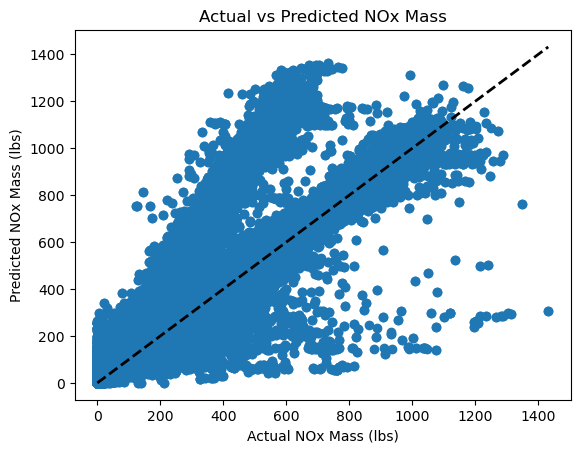

In [53]:
# model with default parameters (no lags, with unmeasured data, with temps)

# WY + ND + MT

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
#xgb_default_model.save_model("WY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_wy_no_lags_with_unmeasured_WITH_ND_MT.json")

y_pred = xgb_default_model.predict(dtest_wy)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest_wy.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.show()

<h6>Transferability Tests</h6>

In [ ]:
# Use WY model to predict ND/MT data

In [68]:
X_train_mt = pd.read_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed_mt")
X_test_mt = pd.read_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed_mt")
y_train_mt = pd.read_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/y_train_mt")
y_test_mt = pd.read_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/y_test_mt")

In [69]:
X_test_mt.shape

(150017, 105)

In [ ]:
# MT has generally higher emissions and greater std

print("WY:")
print(y_test_wy.describe())
print("\nMT:")
print(y_test_mt.describe())

WY:
       NOx Mass (lbs)
count       435797.00
mean           181.25
std            215.40
min              0.00
25%              2.28
50%            135.24
75%            255.51
max           1431.70

MT:
       NOx Mass (lbs)
count       150017.00
mean           328.05
std            510.09
min              0.00
25%              3.80
50%              7.88
75%            695.30
max           1837.89


In [164]:
campd_ny = pd.read_csv("NY/Hourly/Concatted File/ny_2019_2024_complete_cleaned_Full.csv", dtype=campd_type_dict)

In [167]:
campd_ny["Program Code"].unique()

<StringArray>
[         'ARP, CSNOX, CSOSG2, CSSO2G1, RGGI',
    'ARP, CSNOX, CSOSG2, CSSO2G1, MATS, RGGI',
                                'ARP, SIPNOX',
               'CSNOX, CSOSG2, CSSO2G1, RGGI',
                'ARP, CSNOX, CSOSG2, CSSO2G1',
  'ARP, CSNOX, CSOSG2, CSSO2G1, NSPS4T, RGGI',
          'ARP, CSNOX, CSOSG3, CSSO2G1, RGGI',
    'ARP, CSNOX, CSOSG3, CSSO2G1, MATS, RGGI',
               'CSNOX, CSOSG3, CSSO2G1, RGGI',
                'ARP, CSNOX, CSOSG3, CSSO2G1',
  'ARP, CSNOX, CSOSG3, CSSO2G1, NSPS4T, RGGI',
                        'ARP, CSOSG3, SIPNOX',
                       'CSNOX, CSSO2G1, RGGI',
         'ARP, CSNOX, CSOSG2E, CSSO2G1, RGGI',
   'ARP, CSNOX, CSOSG2E, CSSO2G1, MATS, RGGI',
              'CSNOX, CSOSG2E, CSSO2G1, RGGI',
 'ARP, CSNOX, CSOSG2E, CSSO2G1, NSPS4T, RGGI',
                                     'SIPNOX',
                               'RGGI, SIPNOX',
                                       'RGGI',
                                    'Missing']

In [178]:
campd_df["Program Code"].unique()

<StringArray>
['ARP, MATS', 'ARP']
Length: 2, dtype: string

In [177]:
campd_mt["Program Code"].unique()

array(['ARP', 'ARP, MATS'], dtype=object)

In [176]:
campd_nd["Program Code"].unique()

<StringArray>
['ARP, MATS', 'ARP', 'ARP, NSPS4T']
Length: 3, dtype: string

In [174]:
campd_tx["Program Code"].unique()

array(['ARP, CSOSG2, MATS', 'ARP, CSOSG2, MATS, TXSO2', 'ARP, CSOSG2',
       'ARP, CSOSG2, TXSO2', 'ARP'], dtype=object)

In [155]:
campd_mt["NOx Mass Measure Indicator"].value_counts()

NOx Mass Measure Indicator
Calculated    937327
Name: count, dtype: int64

In [154]:
campd_nd["NOx Mass Measure Indicator"].value_counts()

NOx Mass Measure Indicator
Calculated    710303
Name: count, dtype: Int64

In [ ]:
pd.set_option('display.float_format', '{:.2f}'.format)

# similar fuel mixes
# overlapping unit types (Combined cycle is unique to WY)

print("WY:")
display(campd_df.groupby(by="Unit Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))

display(campd_df.groupby(by="Primary Fuel Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))

print("MT:")
display(campd_mt.groupby(by="Unit Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))

display(campd_mt.groupby(by="Primary Fuel Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))


WY:


Unit Type
Dry bottom wall-fired boiler   353806176.00
Tangentially-fired             227806976.00
Combustion turbine                665021.12
Combined cycle                    262930.84
Name: NOx Mass (lbs), dtype: float32

Primary Fuel Type
Coal                         568704192.00
Pipeline Natural Gas          12357907.00
Coal, Pipeline Natural Gas     1478991.12
Name: NOx Mass (lbs), dtype: float32

MT:


Unit Type
Tangentially-fired             324778550.45
Dry bottom wall-fired boiler     7165974.64
Combustion turbine               3512727.20
Name: NOx Mass (lbs), dtype: float64

Primary Fuel Type
Coal                   331944525.09
Pipeline Natural Gas     3512727.20
Name: NOx Mass (lbs), dtype: float64

In [67]:
X_train_nd = pd.read_csv("ND/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed_nd")
X_test_nd = pd.read_csv("ND/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed_nd")
y_train_nd = pd.read_csv("ND/Hourly/Concatted File/Modeling/XGB/NOx/y_train_nd")
y_test_nd = pd.read_csv("ND/Hourly/Concatted File/Modeling/XGB/NOx/y_test_nd")

In [70]:
X_test_nd.shape

(127867, 115)

In [ ]:
# ND has generally higher emissions and greater std

print("WY:")
print(y_test_wy.describe())
print("\nND:")
print(y_test_nd.describe())

WY:
       NOx Mass (lbs)
count       435797.00
mean           181.25
std            215.40
min              0.00
25%              2.28
50%            135.24
75%            255.51
max           1431.70

ND:
       NOx Mass (lbs)
count       127867.00
mean           445.19
std            524.37
min              0.00
25%              4.07
50%            254.16
75%            776.11
max           3154.33


In [ ]:
pd.set_option('display.float_format', '{:.2f}'.format)

# both have similar fuel mixes of coal and natural gas
# but ND has a greater variety in unit types

print("WY:")
display(campd_df.groupby(by="Unit Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))

display(campd_df.groupby(by="Primary Fuel Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))

print("ND:")
display(campd_nd.groupby(by="Unit Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))

display(campd_nd.groupby(by="Primary Fuel Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))

WY:


Unit Type
Dry bottom wall-fired boiler   353806176.00
Tangentially-fired             227806976.00
Combustion turbine                665021.12
Combined cycle                    262930.84
Name: NOx Mass (lbs), dtype: float32

Primary Fuel Type
Coal                         568704192.00
Pipeline Natural Gas          12357907.00
Coal, Pipeline Natural Gas     1478991.12
Name: NOx Mass (lbs), dtype: float32

ND:


Unit Type
Cyclone boiler                              212893248.00
Tangentially-fired                          117202432.00
Dry bottom wall-fired boiler                 10316772.00
Bubbling fluidized bed boiler                 6133157.50
Circulating fluidized bed boiler              2415501.75
Combustion turbine                            1230774.75
Combustion turbine (Started Aug 04, 2021)        1057.01
Name: NOx Mass (lbs), dtype: float32

Primary Fuel Type
Coal                   348961120.00
Pipeline Natural Gas     1231831.75
Name: NOx Mass (lbs), dtype: float32

In [ ]:
xgb_default_model_no_lags = xgb.Booster()
xgb_default_model_no_lags.load_model("WY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_wy_no_lags_with_unmeasured_with_temps.json")

In [145]:
# Create renaming maps for Month, Day, and Hour
day_map   = {f"cat__Day_{i}": f"cat__Day_{i}.0" for i in range(1, 32)}       # Assuming days 1-31
hour_map  = {f"cat__Hour_{i}": f"cat__Hour_{i}.0" for i in range(0, 24)}     # Hours 0–23

# Combine all mappings
rename_map = {**day_map, **hour_map}

# Rename in the DataFrame
X_test_mt.rename(columns=rename_map, inplace=True)

In [151]:
encoded_lag_cols = [
    "encoded__lag_1_hour",
    "encoded__lag_2_hours",
    "encoded__lag_1_day",
    "encoded__lag_2_days",
    "encoded__lag_1_week",
    "encoded__lag_1_month",
    "encoded__lag_1_year"
       ]

X_test_mt = X_test_mt.drop(columns=encoded_lag_cols)
X_test_nd = X_test_nd.drop(columns=encoded_lag_cols)

In [ ]:
# mt is very similar with only one new Secondary Fuel, one new NOx Control, and one new NOx control combination compared to wy
# nd shows greater variety, particulalry due to more unit types

print("Columns only in mt, not wy")
print(set(X_test_mt.columns) - set(xgb_default_model_no_lags.feature_names))

print("Columns only in nd, not wy")
print(set(X_test_nd.columns) - set(xgb_default_model_no_lags.feature_names))

Columns only in mt, not wy
{'cat__Secondary Fuel Type_Diesel Oil', 'encoded__Water Injection', 'encoded__Low NOx Burner Technology w/ Closed-coupled/Separated OFA'}
Columns only in nd, not wy
{'cat__Secondary Fuel Type_Diesel Oil', 'encoded__Water Injection', 'cat__Unit Type_Bubbling fluidized bed boiler', 'cat__Source Category_Cogeneration', 'encoded__Low NOx Burner Technology w/ Closed-coupled/Separated OFA', 'cat__Unit Type_Cyclone boiler', 'cat__Unit Type_Combustion turbine (Started Aug 04, 2021)', 'cat__Secondary Fuel Type_Liquified Petroleum Gas, Pipeline Natural Gas', 'encoded__NSPS4T', 'cat__Unit Type_Circulating fluidized bed boiler'}


In [105]:
# adjust columns such that nd/mt has the same features as wy, if a (categorical) column exists in wy, but not nd/mt we set it 0 for all rows

wy_features = xgb_default_model_no_lags.feature_names
nd_features = X_test_nd.columns.tolist()
mt_features = X_test_mt.columns.tolist()

X_test_nd_adjusted = X_test_nd.copy()
X_test_mt_adjusted = X_test_mt.copy()

# Features to add (with 0s)
features_to_add = list(set(wy_features) - set(nd_features)) # features in wy, but not nd
for feature in features_to_add:
    X_test_nd_adjusted[feature] = 0
features_to_add = list(set(wy_features) - set(mt_features)) # features in wy, but not mt
for feature in features_to_add:
    X_test_mt_adjusted[feature] = 0

# Features to drop
features_to_drop = list(set(nd_features) - set(wy_features)) # features in nd, but not wy
X_test_nd_adjusted.drop(columns=features_to_drop, inplace=True)
features_to_drop = list(set(mt_features) - set(wy_features)) # features in mt, but not wy
X_test_mt_adjusted.drop(columns=features_to_drop, inplace=True)

# Reorder the columns to match wy_features
X_test_nd_adjusted = X_test_nd_adjusted[wy_features]
X_test_mt_adjusted = X_test_mt_adjusted[wy_features]

In [81]:
shared_unit_types_nd = list(set(campd_nd["Unit Type"]).intersection(set(campd_df["Unit Type"].unique())))
shared_unit_types_mt = list(set(campd_mt["Unit Type"]).intersection(set(campd_df["Unit Type"].unique())))
print(shared_unit_types_nd)
print(shared_unit_types_mt)

['Tangentially-fired', 'Combustion turbine', 'Dry bottom wall-fired boiler']
['Tangentially-fired', 'Combustion turbine', 'Dry bottom wall-fired boiler']


In [ ]:
# filter nd data to only include units part of wy training data
X_test_nd_adjusted_filtered = X_test_nd_adjusted[(X_test_nd_adjusted["cat__Unit Type_Tangentially-fired"] == 1) | (X_test_nd_adjusted["cat__Unit Type_Combustion turbine"] == 1) | (X_test_nd_adjusted["cat__Unit Type_Dry bottom wall-fired boiler"] == 1)]
y_test_nd_filtered = y_test_nd[X_test_nd_adjusted_filtered.index]

In [118]:
print(y_test_mt_filtered.shape)
print(y_test_nd_filtered.shape)

(150017,)
(91050,)


In [ ]:
dtest_mt_adjusted = xgb.DMatrix(X_test_mt_adjusted, label=y_test_mt)

dtest_nd_adjusted = xgb.DMatrix(X_test_nd_adjusted, label=y_test_nd)
dtest_nd_adjusted_filtered = xgb.DMatrix(X_test_nd_adjusted_filtered, label=y_test_nd_filtered)

R^2 Score: 0.9469
Mean Squared Error (MSE): 13810.8203
Root Mean Squared Error (RMSE): 117.5194
Normalized RMSE (by std): 0.2304


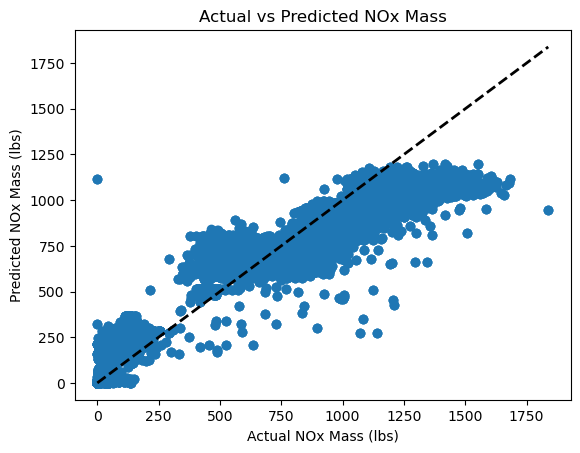

In [ ]:
# model trained on wy data (2019-2023) to predict mt data (no filtering necessary, all units in mt exist in wy)

y_pred = xgb_default_model_no_lags.predict(dtest_mt_adjusted)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest_mt_adjusted.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.show()

R^2 Score: 0.6333
Mean Squared Error (MSE): 100820.1328
Root Mean Squared Error (RMSE): 317.5219
Normalized RMSE (by std): 0.6055


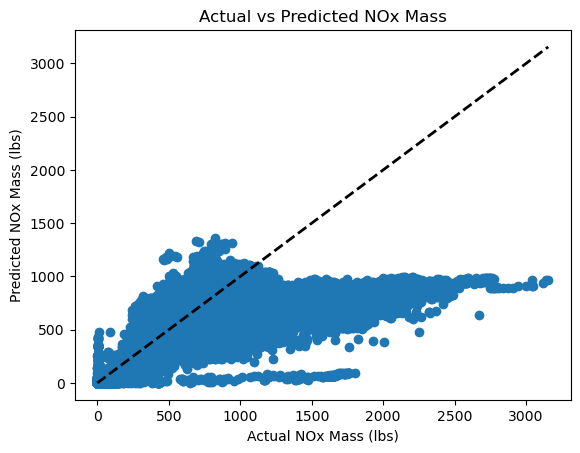

In [ ]:
# model trained on wy data (2019-2023) to predict nd data (unfiltered)

y_pred = xgb_default_model_no_lags.predict(dtest_nd_adjusted)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest_nd_adjusted.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.show()

R^2 Score: 0.8074
Mean Squared Error (MSE): 20011.9648
Root Mean Squared Error (RMSE): 141.4637
Normalized RMSE (by std): 0.4389


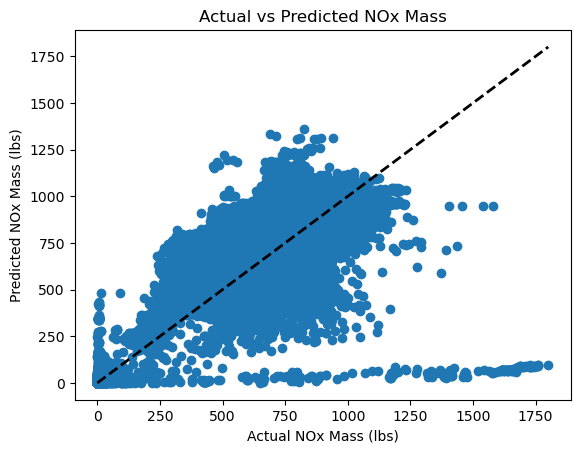

In [ ]:
# model trained on wy data (2019-2023) to predict nd data (filtered)

y_pred = xgb_default_model_no_lags.predict(dtest_nd_adjusted_filtered)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest_nd_adjusted_filtered.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.show()

<h5>Different Time Series Tests</h5>

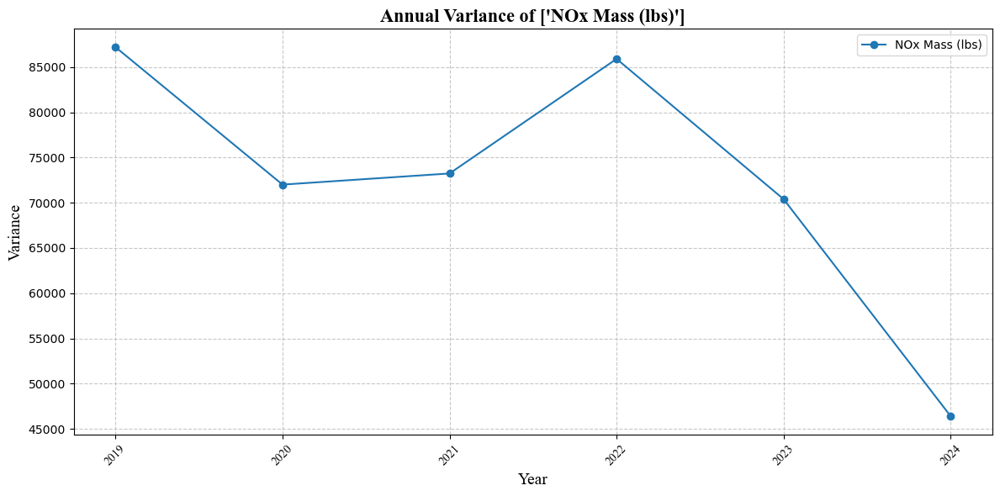

In [65]:
# Look at yearly variance 

variables = ["NOx Mass (lbs)"]

# Set 'datetime' as index for resampling
campd_df["datetime"] = pd.to_datetime(campd_df["datetime"])
campd_df.set_index('datetime', inplace=True)
annual_variance = campd_df[variables].resample('YE').var()
annual_variance.index = annual_variance.index.year

plt.figure(figsize=(12, 6))

for var in variables:
    plt.plot(annual_variance.index, annual_variance[var], marker='o', label=var)

plt.title(f'Annual Variance of {variables}', fontsize=16, fontweight='bold', fontname='Times New Roman')
plt.xlabel('Year', fontsize=14, fontname='Times New Roman')
plt.ylabel('Variance', fontsize=14, fontname='Times New Roman')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(annual_variance.index, rotation=45, fontname='Times New Roman')
plt.tight_layout()
plt.show()


In [72]:
# some preprocessing for the combined dataset

X_train["num__Year"] = X_train["num__Year"].astype(int)
X_test["num__Year"] = X_test["num__Year"].astype(int)
y_test = y_test.rename(columns={0: "NOx Mass (lbs)"})
X_complete = pd.concat([X_train, X_test])
X_complete = X_complete.reset_index(drop=True)
y_complete = pd.concat([y_train, y_test])
y_complete = y_complete.reset_index(drop=True)

In [73]:
# Year by Year

year_tuples = [(2019, 2020), (2020, 2021), (2021, 2022), (2022, 2023), (2023, 2024)] 

for years in year_tuples:

    # Filter training data for the first year
    current_X_train = X_complete[X_complete["num__Year"] == years[0]]
    current_y_train = y_complete.loc[current_X_train.index]

    # Filter test data for the second year
    current_X_test = X_complete[X_complete["num__Year"] == years[1]]
    current_y_test = y_complete.loc[current_X_test.index]

    current_dtrain = xgb.DMatrix(current_X_train, label=current_y_train)
    current_dtest = xgb.DMatrix(current_X_test, label=current_y_test)

    xgb_default_model = xgb.train(params=default_params, dtrain=current_dtrain, num_boost_round=100)

    y_pred = xgb_default_model.predict(current_dtest)

    y_pred[y_pred < 0] = 0

    print(f"Train: {years[0]}, Test: {years[1]} | R^2: {r2_score(current_y_test.to_numpy(), y_pred):.4f}, MSE: {mean_squared_error(current_y_test.to_numpy(), y_pred):.4f}, RMSE: {np.sqrt(mean_squared_error(current_y_test.to_numpy(), y_pred)):.4f}, nRMSE: {np.sqrt(mean_squared_error(current_y_test.to_numpy(), y_pred)) / np.std(current_y_test.to_numpy()):.4f}")


Train: 2019, Test: 2020 | R^2: 0.9638, MSE: 2604.4709, RMSE: 51.0340, nRMSE: 0.1902
Train: 2020, Test: 2021 | R^2: 0.9725, MSE: 2015.3801, RMSE: 44.8930, nRMSE: 0.1659
Train: 2021, Test: 2022 | R^2: 0.9537, MSE: 3976.5742, RMSE: 63.0601, nRMSE: 0.2151
Train: 2022, Test: 2023 | R^2: 0.9587, MSE: 2905.1077, RMSE: 53.8991, nRMSE: 0.2031
Train: 2023, Test: 2024 | R^2: 0.8916, MSE: 5029.3794, RMSE: 70.9181, nRMSE: 0.3292


Train: [2019], Test: 2020 | R^2: 0.9638, MSE: 2604.4709, RMSE: 51.0340, nRMSE: 0.1902


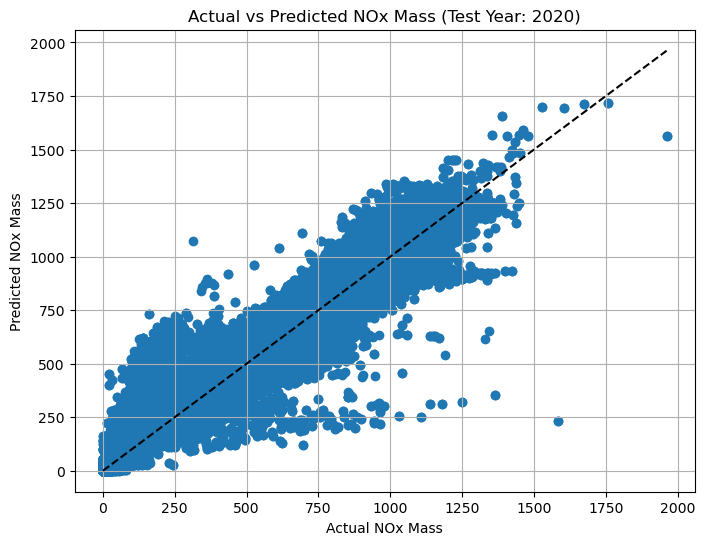

Train: [2019, 2020], Test: 2021 | R^2: 0.9715, MSE: 2085.4951, RMSE: 45.6672, nRMSE: 0.1687


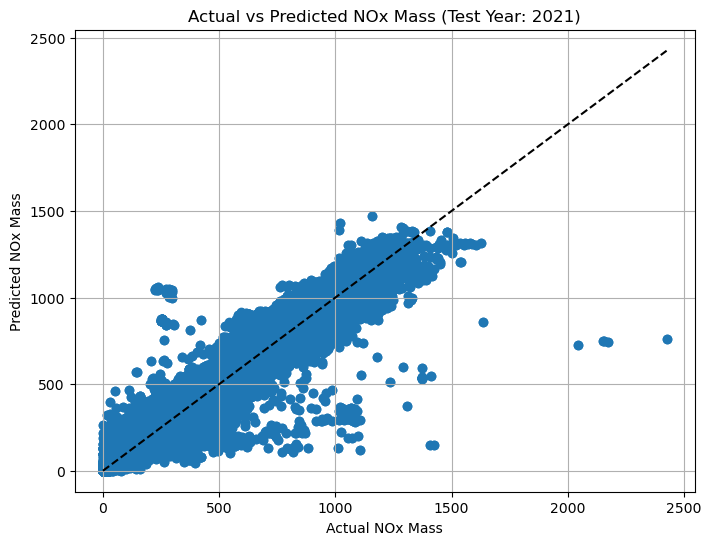

Train: [2019, 2020, 2021], Test: 2022 | R^2: 0.9585, MSE: 3564.0002, RMSE: 59.6992, nRMSE: 0.2037


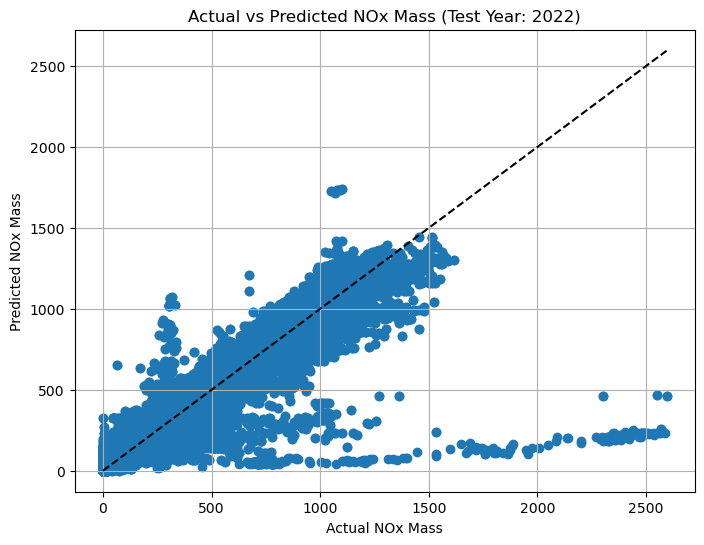

Train: [2019, 2020, 2021, 2022], Test: 2023 | R^2: 0.9474, MSE: 3702.8889, RMSE: 60.8514, nRMSE: 0.2293


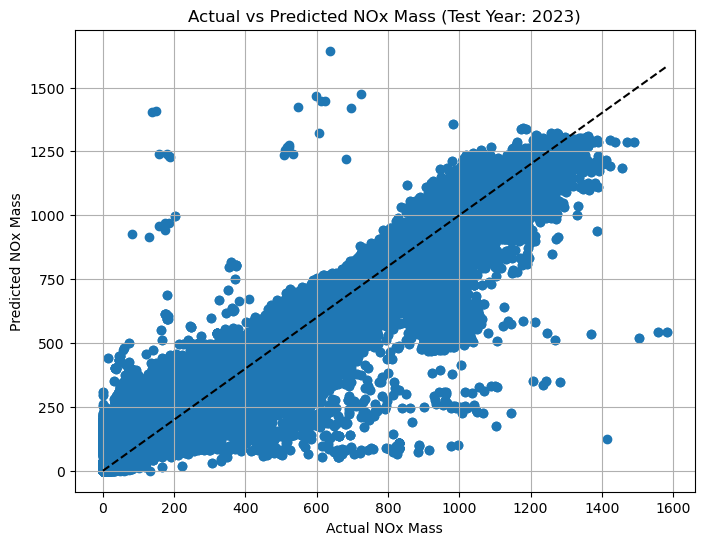

Train: [2019, 2020, 2021, 2022, 2023], Test: 2024 | R^2: 0.9043, MSE: 4439.2427, RMSE: 66.6276, nRMSE: 0.3093


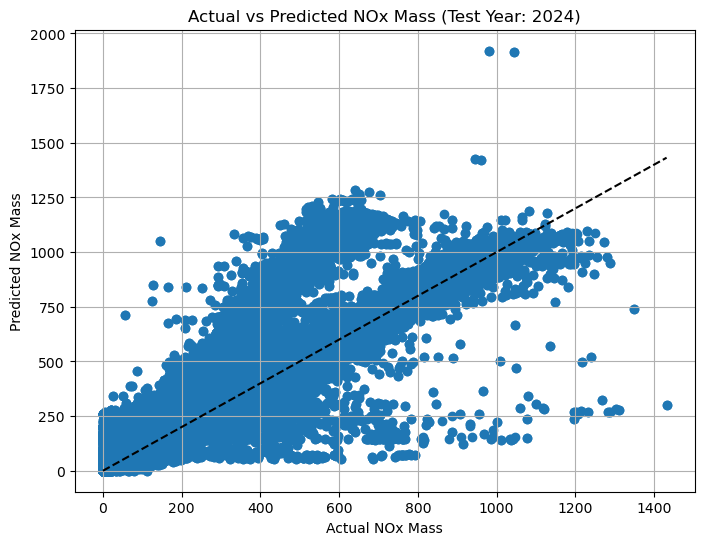

In [78]:
# Rolling Window
years = [2019, 2020, 2021, 2022, 2023, 2024]

for i in range(1, len(years)):
    train_years = years[:i]      # all years before the test year
    test_year = years[i]         # current year for testing

    # Train and test data for the current rolling window
    current_X_train = X_complete[(X_complete["num__Year"].isin(train_years))]
    current_y_train = y_complete.loc[current_X_train.index]

    current_X_test = X_complete[(X_complete["num__Year"] == test_year)]
    current_y_test = y_complete.loc[current_X_test.index]

    # Creating DMatrix for XGBoost
    current_dtrain = xgb.DMatrix(current_X_train, label=current_y_train)
    current_dtest = xgb.DMatrix(current_X_test, label=current_y_test)

    # Train the model
    xgb_default_model = xgb.train(params=default_params, dtrain=current_dtrain, num_boost_round=100)

    # Predict on the test set
    y_pred = xgb_default_model.predict(current_dtest)
    y_pred[y_pred < 0] = 0  # Ensure no negative predictions

    # Calculate performance metrics
    r2 = r2_score(current_y_test.to_numpy(), y_pred)
    mse = mean_squared_error(current_y_test.to_numpy(), y_pred)
    rmse = np.sqrt(mse)
    nrmse = rmse / np.std(current_y_test.to_numpy())

    print(f"Train: {train_years}, Test: {test_year} | R^2: {r2:.4f}, "
          f"MSE: {mse:.4f}, RMSE: {rmse:.4f}, nRMSE: {nrmse:.4f}")

    # Scatter Plot: Actual vs Predicted for the test year
    plt.figure(figsize=(8, 6))
    plt.scatter(current_y_test, y_pred, label=f"Test Year: {test_year}")
    plt.plot([min(current_y_test), max(current_y_test)], [min(current_y_test), max(current_y_test)], 
             color='black', linestyle='--')
    plt.title(f"Actual vs Predicted NOx Mass (Test Year: {test_year})")
    plt.xlabel("Actual NOx Mass")
    plt.ylabel("Predicted NOx Mass")
    plt.grid(True)
    plt.show()

In [74]:
# Rolling Window

years = [2019, 2020, 2021, 2022, 2023, 2024]

for i in range(1, len(years)):
    train_years = years[:i]      # all years before the test year
    test_year = years[i]         # current year for testing

    current_X_train = X_complete[(X_complete["num__Year"].isin(train_years))]
    current_y_train = y_complete.loc[current_X_train.index]

    current_X_test = X_complete[(X_complete["num__Year"] == test_year)]
    current_y_test = y_complete.loc[current_X_test.index]

    current_dtrain = xgb.DMatrix(current_X_train, label=current_y_train)
    current_dtest = xgb.DMatrix(current_X_test, label=current_y_test)

    xgb_default_model = xgb.train(params=default_params, dtrain=current_dtrain, num_boost_round=100)

    y_pred = xgb_default_model.predict(current_dtest)
    y_pred[y_pred < 0] = 0

    print(f"Train: {train_years}, Test: {test_year} | R^2: {r2_score(current_y_test.to_numpy(), y_pred):.4f}, "
          f"MSE: {mean_squared_error(current_y_test.to_numpy(), y_pred):.4f}, "
          f"RMSE: {np.sqrt(mean_squared_error(current_y_test.to_numpy(), y_pred)):.4f}, "
          f"nRMSE: {np.sqrt(mean_squared_error(current_y_test.to_numpy(), y_pred)) / np.std(current_y_test.to_numpy()):.4f}")

Train: [2019], Test: 2020 | R^2: 0.9638, MSE: 2604.4709, RMSE: 51.0340, nRMSE: 0.1902
Train: [2019, 2020], Test: 2021 | R^2: 0.9715, MSE: 2085.4951, RMSE: 45.6672, nRMSE: 0.1687
Train: [2019, 2020, 2021], Test: 2022 | R^2: 0.9585, MSE: 3564.0002, RMSE: 59.6992, nRMSE: 0.2037
Train: [2019, 2020, 2021, 2022], Test: 2023 | R^2: 0.9474, MSE: 3702.8889, RMSE: 60.8514, nRMSE: 0.2293
Train: [2019, 2020, 2021, 2022, 2023], Test: 2024 | R^2: 0.9043, MSE: 4439.2427, RMSE: 66.6276, nRMSE: 0.3093


In [75]:
# Static Prediction Horizon (2024)

years = [2019, 2020, 2021, 2022, 2023]
test_year = 2024

for i in range(1, len(years) + 1):
    train_years = years[:i]  # Use first i years as training set
    
    current_X_train = X_complete[(X_complete["num__Year"].isin(train_years))]
    current_y_train = y_complete.loc[current_X_train.index]

    current_X_test = X_complete[(X_complete["num__Year"] == test_year)]
    current_y_test = y_complete.loc[current_X_test.index]

    current_dtrain = xgb.DMatrix(current_X_train, label=current_y_train)
    current_dtest = xgb.DMatrix(current_X_test, label=current_y_test)

    xgb_default_model = xgb.train(params=default_params, dtrain=current_dtrain, num_boost_round=100)

    y_pred = xgb_default_model.predict(current_dtest)
    y_pred[y_pred < 0] = 0

    print(f"Train: {train_years}, Test: {test_year} | "
          f"R^2: {r2_score(current_y_test.to_numpy(), y_pred):.4f}, "
          f"MSE: {mean_squared_error(current_y_test.to_numpy(), y_pred):.4f}, "
          f"RMSE: {np.sqrt(mean_squared_error(current_y_test.to_numpy(), y_pred)):.4f}, "
          f"nRMSE: {np.sqrt(mean_squared_error(current_y_test.to_numpy(), y_pred)) / np.std(current_y_test.to_numpy()):.4f}")


Train: [2019], Test: 2024 | R^2: 0.6693, MSE: 15344.9678, RMSE: 123.8748, nRMSE: 0.5751
Train: [2019, 2020], Test: 2024 | R^2: 0.8535, MSE: 6795.9521, RMSE: 82.4376, nRMSE: 0.3827
Train: [2019, 2020, 2021], Test: 2024 | R^2: 0.8587, MSE: 6556.0293, RMSE: 80.9693, nRMSE: 0.3759
Train: [2019, 2020, 2021, 2022], Test: 2024 | R^2: 0.8515, MSE: 6888.0371, RMSE: 82.9942, nRMSE: 0.3853
Train: [2019, 2020, 2021, 2022, 2023], Test: 2024 | R^2: 0.9043, MSE: 4439.2427, RMSE: 66.6276, nRMSE: 0.3093


<h5>HPO</h5>

<h6>Optuna Trials</h6>

In [ ]:
# default parameters for comparison
# optimization has bias variance tradeoff, see documentation: https://xgboost.readthedocs.io/en/stable/tutorials/param_tuning.html

default_params = {
    # "n_estimators": 100, # number of trees (larger value, more likely to overfit)
    # "max_depth":  6, # max depth of a tree (larger value, more complex, more likely to overfit)
    # "learning_rate": 0.5, # step size shrinkage eta (lower value, more conservative)
    # "subsample": 1, # random subset size of data to use for each tree (lower value, more conservative)
    # "colsample_bytree": 1, # random subset of features to consider for each tree (lower value, more conservative)
    # "gamma": 0, # min loss reduction to make a split (larger value, more conservative)
    # "reg_alpha": 0, # L1 regularization on weights (larger value, more conservative)
    # "reg_lambda": 1, # L2 regularization on weights (larger value, more conservative)
    # "min_child_weight": 1, # min sum of instance weight (hessian) needed in a child (larger value, more conservative)
    # "tree_method": "auto" # automatically chooses exact or approximation method based on data size

    # needed params for xgb.train
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
    "tree_method": "hist", # approximation (faster, but not exact, should change on final run)
    "device": "cuda", # use gpu (if unavailable, will use cpu)
    'seed': 42 # like random_state, but for xgb.train
}

In [ ]:
# objective function for optuna
def objective(trial):
    print(f"Starting trial {trial.number}")

    params = {
        "max_depth": trial.suggest_int("max_depth", 4, 25),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.25),
        "subsample": trial.suggest_float("subsample", 0.3, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.7, 1.0),
        "gamma": trial.suggest_float("gamma", 0, 0.5),
        "reg_alpha": trial.suggest_float("reg_alpha", 0, 0.2),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 6.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 15),
        "tree_method": "hist",
        "objective": "reg:squarederror",
        "eval_metric": "rmse",
        #"device": "cuda"  # or "cpu"
    }

    tscv = TimeSeriesSplit(n_splits=5)
    rmse_folds = []
    best_iterations = []

    for fold, (train_idx, test_idx) in enumerate(tscv.split(X_train)):
        current_X_train, current_X_test = X_train.iloc[train_idx], X_train.iloc[test_idx]
        current_y_train, current_y_test = y_train.iloc[train_idx], y_train.iloc[test_idx]

        current_dtrain = xgb.DMatrix(current_X_train, label=current_y_train)
        current_dtest = xgb.DMatrix(current_X_test, label=current_y_test)

        evals_result = {}
        model = xgb.train(
            params,
            current_dtrain,
            num_boost_round=1000,
            evals=[(current_dtest, "validation")],
            early_stopping_rounds=20,
            verbose_eval=False, # prevents printing at each boosting stage
            evals_result=evals_result
        )

        best_iterations.append(model.best_iteration)
        # Get last RMSE from evals_result
        fold_rmse = evals_result["validation"]["rmse"][model.best_iteration - 1] # (0-indexed)
        rmse_folds.append(fold_rmse)

        print(f"Fold {fold+1} rmse: {fold_rmse:.4f} best_iteration: {model.best_iteration}")

    avg_rmse = np.mean(rmse_folds)
    avg_best_iter = int(np.mean(best_iterations))

    print(f"Trial {trial.number} avg RMSE: {avg_rmse:.4f}, avg best_iteration: {avg_best_iter}")

    # manually store the avg best boosting rounds and full list of rmse folds (we output the avg rmse separately)
    trial.set_user_attr("best_iteration", avg_best_iter)
    trial.set_user_attr("fold_rmses", rmse_folds)

    return avg_rmse


In [ ]:
study = optuna.create_study(study_name="HPT 22.06.25 18:04", storage="sqlite:///optuna_studies.db", direction="minimize")
study.optimize(objective, n_trials=50) 
print("Best params:", study.best_params)

In [ ]:
study = optuna.load_study(
    study_name="HPT 22.06.25 18:04", 
    storage="sqlite:///optuna_studies.db"
)

# Get the best 5 trials
sorted_trials = sorted(
    [t for t in study.trials if t.value is not None], 
    key=lambda t: t.value
)

for i, trial in enumerate(sorted_trials[:5], 1):
    print(f"\nTrial {i}:")
    print(f"  Value (Objective): {trial.value}")
    print(f"  Number: {trial.number}")
    print(f"  Params:")
    for key, val in trial.params.items():
        print(f"    {key}: {val}")
    print(f"best_iteration: {trial.user_attrs.get("best_iteration")}")

second_best_params = sorted_trials[1]


In [ ]:
study = optuna.load_study(
    study_name="HPT 22.06.25 18:04", 
    storage="sqlite:///optuna_studies.db"
)

print("Best params:", study.best_params)
print("Best value (RMSE):", study.best_value)
print(study.best_trial.user_attrs.get("best_iteration")) 

# HPO visualizations
fig1 = vis.plot_param_importances(study)
fig2 = vis.plot_optimization_history(study)
fig3 = vis.plot_slice(study)

# update font to Times New Roman
for fig in [fig1, fig2, fig3]:
    fig.update_layout(font=dict(family="Times New Roman", size=14)) 
    fig.show()

<h6>Model</h6>

In [36]:
# best params found
hpo_params = {
    **study.best_params,
    #"n_estimators": study.best_trial.user_attrs.get("best_iteration"),
    "tree_method": "hist",
    #"device": "cuda", # use gpu or cpu
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
    "seed": 42
}

In [ ]:
# second best params found
second_best_hpo_params = {
    **second_best_params.params,
    #"n_estimators": study.best_trial.user_attrs.get("best_iteration"),
    "tree_method": "hist",
    #"device": "cuda", # use gpu or cpu
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
    "seed": 42
}


In [ ]:
default_params = {
    "n_estimators": 100, # number of trees (larger value, more likely to overfit)
    "max_depth":  6, # max depth of a tree (larger value, more complex, more likely to overfit)
    "learning_rate": 0.5, # step size shrinkage eta (lower value, more conservative)
    "subsample": 1, # random subset size of data to use for each tree (lower value, more conservative)
    "colsample_bytree": 1, # random subset of features to consider for each tree (lower value, more conservative)
    "gamma": 0, # min loss reduction to make a split (larger value, more conservative)
    "reg_alpha": 0, # L1 regularization on weights (larger value, more conservative)
    "reg_lambda": 1, # L2 regularization on weights (larger value, more conservative)
    "min_child_weight": 1, # min sum of instance weight (hessian) needed in a child (larger value, more conservative)
    "tree_method": "auto" # automatically chooses exact or approximation method based on data size
}

In [ ]:
# model with second best (less boost rounds) hpo parameters (with lags, no unmeasured data)

xgb_hpo_model = xgb.train(params=second_best_hpo_params, dtrain=dtrain, num_boost_round=254)

# dump model
xgb_hpo_model.save_model("WY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_hpo_model_wy_with_lags_no_unmeasured.json")

y_pred = xgb_hpo_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

In [ ]:
# model with best hpo parameters (no unmeasured data)

xgb_hpo_model = xgb.train(params=hpo_params, dtrain=dtrain, num_boost_round=570)

# dump model
#xgb_hpo_model.save_model("WY/Hourly/Concatted File/Modeling/XGB/NOx/Trained/Models/xgb_hpo_model_wy_with_lags_no_unmeasured.json")

y_pred = xgb_hpo_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h2>Interpretability</h2>

<h5>Read-in Models</h5>

In [8]:
# load saved models

rf_default_model_no_lags = joblib.load("WY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_wy_no_lags_with_unmeasured_with_temps.json")

rf_default_model_with_lags = joblib.load("WY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_wy_with_lags_with_unmeasured_with_temps.json")

xgb_default_model_with_lags = xgb.Booster()
xgb_default_model_with_lags.load_model("WY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_wy_with_lags_with_unmeasured_with_temps.json")

xgb_default_model_no_lags = xgb.Booster()
xgb_default_model_no_lags.load_model("WY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_wy_no_lags_with_unmeasured_with_temps.json")

In [ ]:
xgb_hpo_model = xgb.Booster()
xgb_hpo_model.load_model("WY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_hpo_model_wy_with_lags_no_unmeasured.json")

<h3>RF (model-specific)</h3>

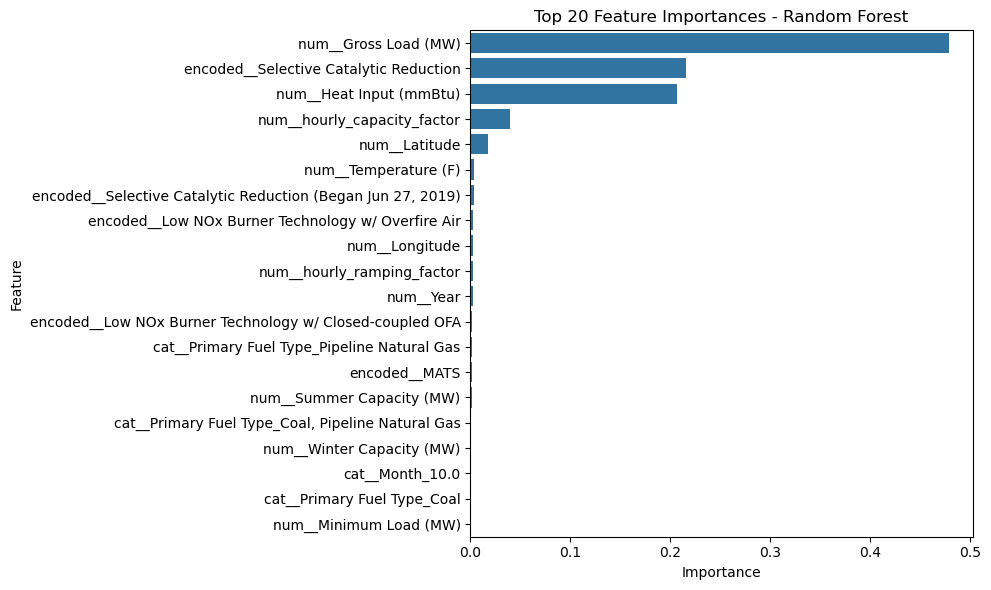

In [85]:
# for default rf model no lags, no unmeasured data, with temps

importances = rf_default_model_no_lags.feature_importances_

feat_imp_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': importances
})

feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)

# uses MDI (Mean Decrease in Impurity)
plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp_df.head(20), x='Importance', y='Feature')
plt.title('Top 20 Feature Importances - Random Forest')
plt.tight_layout()
plt.show()


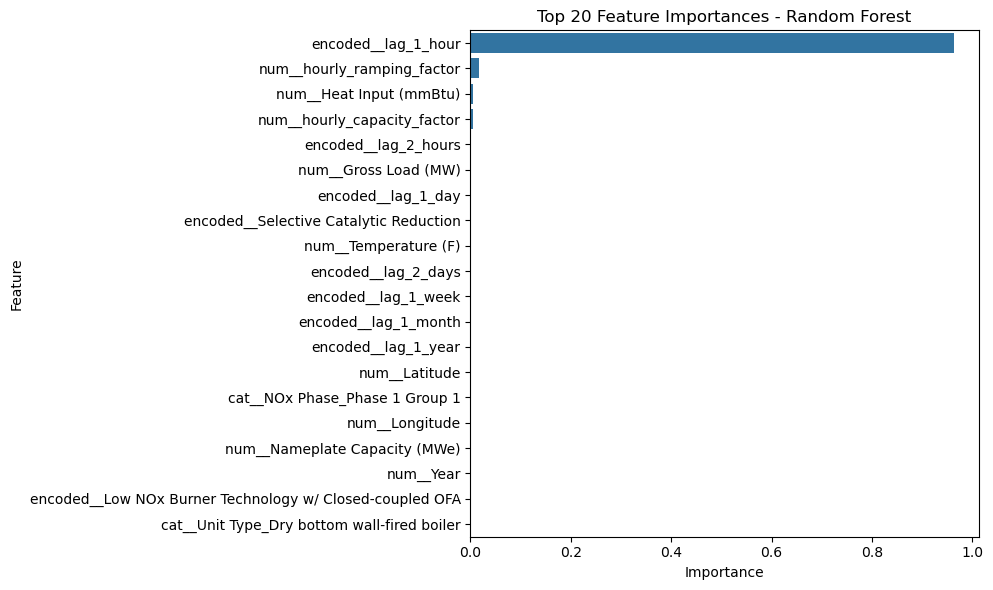

In [87]:
# for default rf model with lags, no unmeasured data, with temps

importances = rf_default_model_with_lags.feature_importances_

feat_imp_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': importances
})

feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)

# uses MDI (Mean Decrease in Impurity)
plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp_df.head(20), x='Importance', y='Feature')
plt.title('Top 20 Feature Importances - Random Forest')
plt.tight_layout()
plt.show()


<h3>XGB (model-specific)</h3>

<h5>Default Params</h5>

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

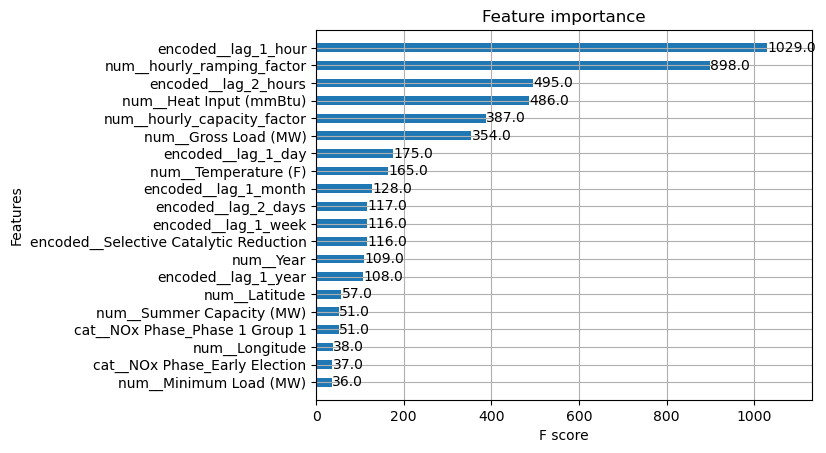

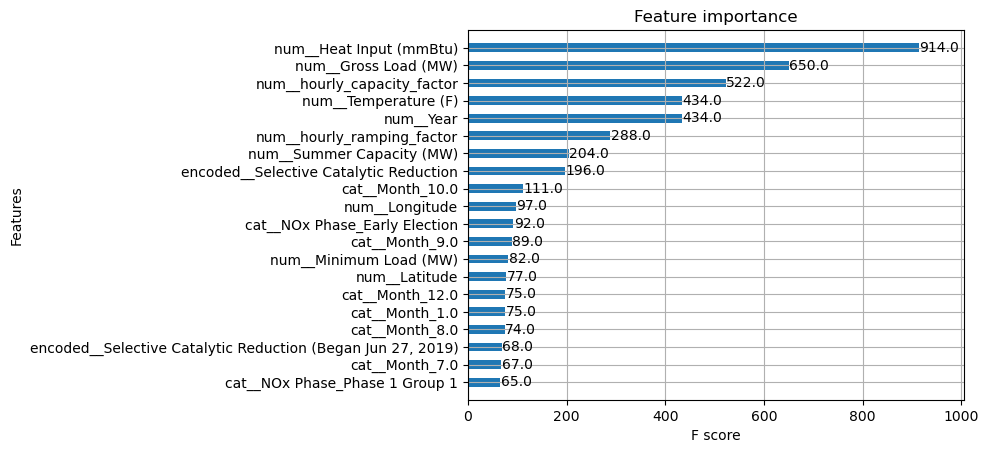

In [88]:
# use weight for feature importance (how often the feature is used in splits)
plot_importance(
    xgb_default_model_with_lags, 
    importance_type='weight',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

plot_importance(
    xgb_default_model_no_lags, 
    importance_type='weight',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

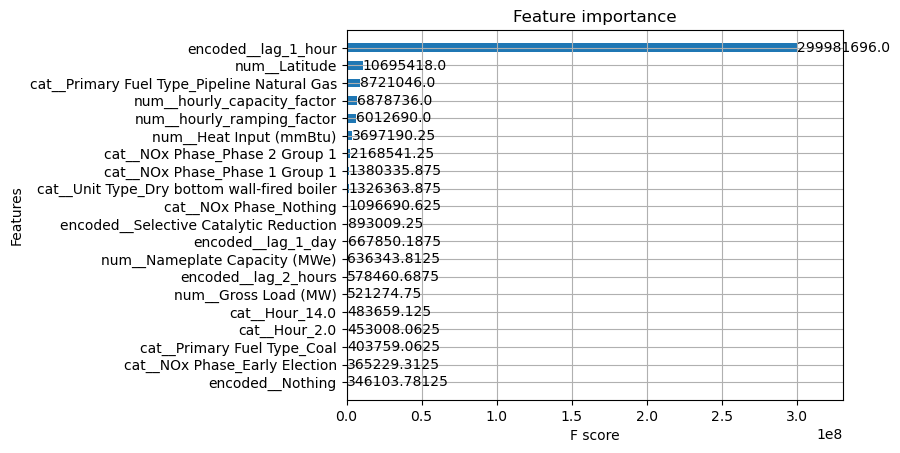

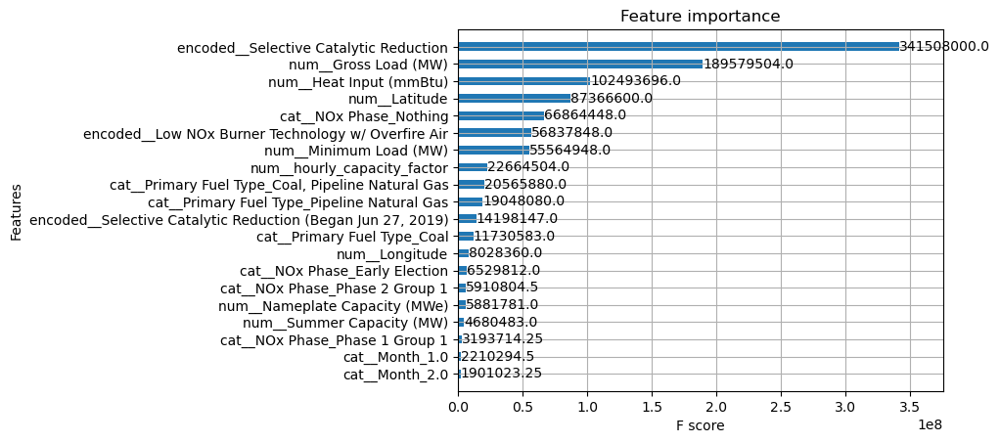

In [89]:
# use gain for feature importance (Average improvement in loss from splits involving that feature)
plot_importance(
    xgb_default_model_with_lags, 
    importance_type='gain',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

plot_importance(
    xgb_default_model_no_lags, 
    importance_type='gain',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

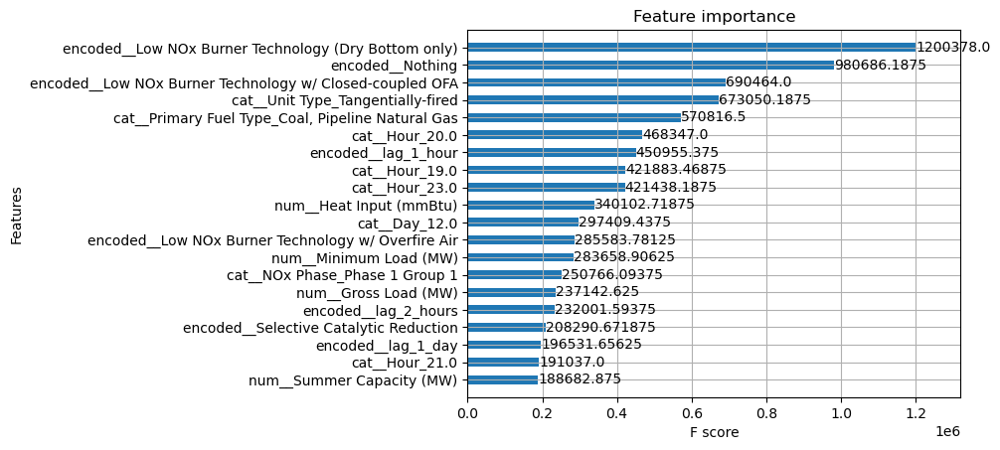

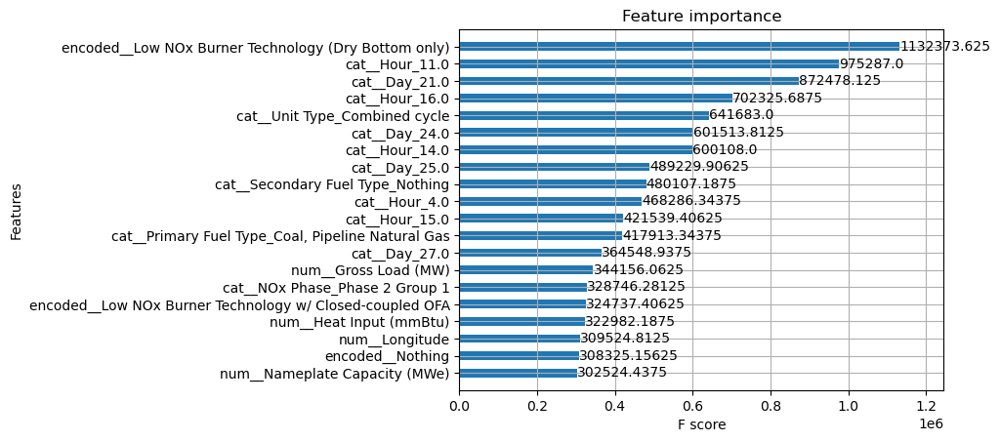

In [90]:
# use cover for feature importance (how many observations are affected by the feature)
plot_importance(
    xgb_default_model_with_lags, 
    importance_type='cover',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

plot_importance(
    xgb_default_model_no_lags, 
    importance_type='cover',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<h5>HPO Params</h5>

In [ ]:
# use weight for feature importance (how often the feature is used in splits)
plot_importance(
    xgb_hpo_model, 
    importance_type='weight',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

In [ ]:
# use gain for feature importance (Average improvement in loss from splits involving that feature)
plot_importance(
    xgb_hpo_model, 
    importance_type='gain',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

In [ ]:
# use cover for feature importance (how many observations are affected by the feature)
plot_importance(
    xgb_hpo_model, 
    importance_type='cover', 
    max_num_features=20,      
    height=0.5,
    show_values=True,
    grid=True
)

<h3>Partial Dependence Plots</h3>

In [ ]:
xgb_default_model_no_lags_regressor = XGBRegressor()
xgb_default_model_no_lags_regressor._Booster = xgb_default_model_no_lags

<h3>Permutation Importance</h3>

<h4>Default Params</h4>

In [91]:
regressor = XGBRegressor()
regressor._Booster = xgb_default_model_no_lags

In [96]:
result = permutation_importance(regressor, X_test, y_test, n_repeats=3, random_state=42, scoring='neg_mean_squared_error', n_jobs=-1)

importance_df = pd.DataFrame({
    'feature': X_test.columns,
    'importance_mean': result.importances_mean,
    'importance_std': result.importances_std
}).sort_values(by='importance_mean', ascending=False)

display(importance_df)


,feature,importance_mean,importance_std
83,num__Heat Input (mmBtu),"88,480.15",55.27
101,encoded__Selective Catalytic Reduction,"29,652.04",157.12
82,num__Gross Load (MW),"6,717.97",32.34
87,num__hourly_capacity_factor,"5,141.46",44.49
84,num__Latitude,"2,228.13",18.53
...,...,...,...
71,cat__NOx Phase_Phase 2 Group 1,-20.52,3.61
11,cat__Month_12.0,-58.41,0.98
89,num__Summer Capacity (MW),-93.12,5.47
7,cat__Month_8.0,-97.30,0.10


<h4>Ungrouped</h4>

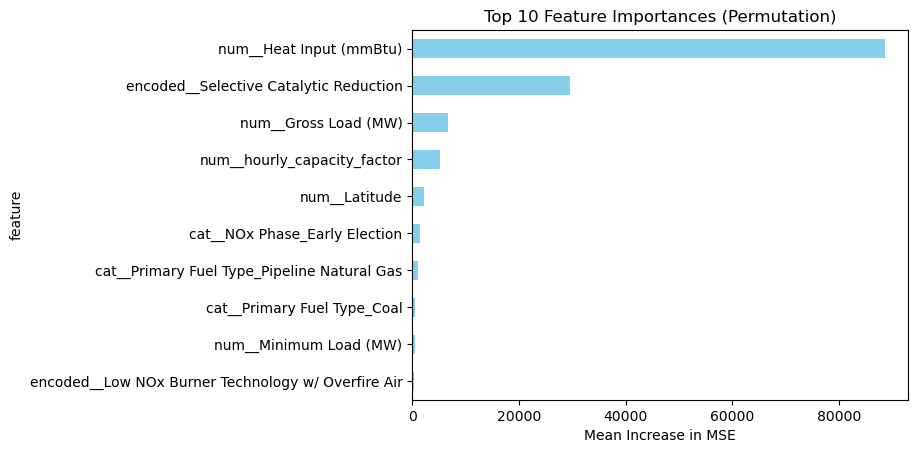

In [97]:
importance_df.head(10).plot.barh(
    x='feature', 
    y='importance_mean', 
    legend=False,
    color='skyblue'
)

plt.xlabel('Mean Increase in MSE')
plt.title('Top 10 Feature Importances (Permutation)')
plt.gca().invert_yaxis()  # get the most important on top
plt.show()


In [99]:
# num features
num_features = ['num__Gross Load (MW)',
                 'num__Heat Input (mmBtu)', 
                 'num__Latitude', 
                 'num__Longitude', 
                 'num__Nameplate Capacity (MWe)',
                   'num__hourly_capacity_factor', 
                   'num__hourly_ramping_factor', 
                   'num__Summer Capacity (MW)', 
                   'num__Winter Capacity (MW)', 
                   'num__Minimum Load (MW)'] # we ignore day, hour, month, year

In [ ]:
# group features systematically (cluster on correlation)

X_subset = X_test[num_features]
X_subset = X_subset.dropna()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 8))

# Compute Spearman correlation matrix on selected features
corr = spearmanr(X_subset).correlation

# Make symmetric and fill diagonal with 1s
corr = (corr + corr.T) / 2
np.fill_diagonal(corr, 1)

# Convert correlation to distance matrix for clustering
distance_matrix = 1 - np.abs(corr)
dist_linkage = hierarchy.ward(squareform(distance_matrix))

# Plot dendrogram
dendro = hierarchy.dendrogram(
    dist_linkage, labels=X_subset.columns.to_list(), ax=ax1, leaf_rotation=90
)
dendro_idx = np.arange(len(dendro["ivl"]))

# Plot reordered heatmap of correlations
im = ax2.imshow(corr[dendro["leaves"], :][:, dendro["leaves"]],
                cmap='RdBu_r', vmin=-1, vmax=1)
ax2.set_xticks(dendro_idx)
ax2.set_yticks(dendro_idx)
ax2.set_xticklabels(dendro["ivl"], rotation=90)
ax2.set_yticklabels(dendro["ivl"])

# Add colorbar
fig.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)

ax1.set_title("Feature Clustering Dendrogram")
ax2.set_title("Spearman Correlation Heatmap")

plt.tight_layout()
plt.show()

# distance here is calculated as 1 - Spearman correlation coefficient


In [ ]:
# select only one feature per group of features with distance <0.2 -> Heat Input, Nameplate Capacity (MWe)

In [ ]:
X_train = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/X_train_processed", dtype=campd_type_dict)
X_test = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/X_test_processed", dtype=campd_type_dict)
y_train = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/y_train")
y_test = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/y_test")

In [21]:
# group features below threshold of 0.2 (over 80% correlation) and retrain

X_train = X_train.drop(columns=["num__hourly_capacity_factor", "num__Gross Load (MW)", "num__Summer Capacity (MW)",
                "num__Winter Capacity (MW)"])
X_test = X_test.drop(columns=["num__hourly_capacity_factor", "num__Gross Load (MW)", "num__Summer Capacity (MW)",
                "num__Winter Capacity (MW)"])

# Convert to DMatrix for XGBoost
dtrain = xgb.DMatrix(X_train, label=y_train) 
dtest = xgb.DMatrix(X_test, label=y_test)

In [ ]:
xgb_default_model_no_corr = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

y_pred = xgb_default_model_no_corr.predict(dtest)
y_test = dtest.get_label()
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

In [25]:
regressor = XGBRegressor()
regressor._Booster = xgb_default_model_no_corr

In [26]:
result = permutation_importance(regressor, X_test, y_test, n_repeats=3, random_state=42, scoring='neg_mean_squared_error')

In [ ]:
importance_df = pd.DataFrame({
    'feature': X_test.columns,
    'importance_mean': result.importances_mean,
    'importance_std': result.importances_std
}).sort_values(by='importance_mean', ascending=False)

print(importance_df)


<h4>Grouped</h4>

In [ ]:
importance_df.head(20).plot.barh(
    x='feature', 
    y='importance_mean', 
    legend=False,
    color='skyblue'
)

plt.xlabel('Mean Increase in MSE (neg_mean_squared_error)')
plt.title('Top 10 Feature Importances (Permutation)')
plt.gca().invert_yaxis()  # get the most important on top
plt.show()


<h3>SHAP</h3>

<h4>RF</h4>

In [6]:
explainer = shap.TreeExplainer(rf_default_model_no_lags)

In [7]:
# takes over 15 mins without approximation
shap_values = explainer(X_test, approximate=True)

In [ ]:
joblib.dump(shap_values, "WY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/shap_values_rf_default_model_wy_no_lags_no_unmeasured_with_temps.pkl", compress=True)

['NY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/shap_values_rf_default_model_ny_no_lags_no_unmeasured_with_temps.pkl']

In [ ]:
shap.plots.bar(shap_values, max_display=20)

In [ ]:
shap.plots.beeswarm(shap_values, max_display=20)

In [ ]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"num__Nameplate Capacity (MWe)"])

In [ ]:

# Fit model and select a single sample
# Show force plot
shap.plots.force(explainer(X_test.iloc[[482884]]), matplotlib=True, contribution_threshold=0.1, figsize=(30,4))

In [ ]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"num__Heat Input (mmBtu)"])


In [ ]:
shap.plots.scatter(shap_values[:,"num__Temperature (F)"], color=shap_values[:,"cat__Secondary Fuel Type_Residual Oil"])

# hypothesis: shap values of temp are largely driven by interactions with 
# secondary fuel type residual oil.

In [ ]:
shap.plots.scatter(shap_values[:,"cat__Secondary Fuel Type_Residual Oil"], color=shap_values[:,"num__Temperature (F)"])


In [ ]:
shap.plots.scatter(shap_values[:,"num__Temperature (F)"], color=shap_values[:,"num__Heat Input (mmBtu)"])


In [ ]:
shap.plots.scatter(shap_values[:,"encoded__Selective Catalytic Reduction"], color=shap_values[:,"num__Heat Input (mmBtu)"])


<h4>XGB</h4>

<h5>SHAP Values</h5>

In [100]:
explainer = shap.TreeExplainer(xgb_default_model_no_lags)

In [101]:
shap_values = explainer(X_test, approximate=False)

# this took just 1 min

In [ ]:
joblib.dump(shap_values, "WY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/shap_values_xgb_default_model_wy_no_lags_with_unmeasured_with_temps.pkl", compress=True)

['WY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/shap_values_xgb_default_model_wy_no_lags_no_unmeasured_with_temps.pkl']

In [10]:
shap_values = joblib.load("WY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/shap_values_xgb_default_model_wy_no_lags_with_unmeasured_with_temps.pkl")

In [120]:
indices = np.where(X_test["cat__Primary Fuel Type_Coal"] == 1)[0]

In [121]:
indices_png = np.where(X_test["cat__Primary Fuel Type_Pipeline Natural Gas"] == 1)[0]

In [114]:
shap_values

.values =
array([[ 2.531042  ,  0.11207645, -3.2787807 , ..., -0.33873284,
         0.        ,  0.        ],
       [ 2.531042  ,  0.11207645, -3.2787807 , ..., -0.33873284,
         0.        ,  0.        ],
       [ 1.3667774 , -0.0137552 , -3.1106    , ..., -0.31880146,
         0.        ,  0.        ],
       ...,
       [-0.0926597 ,  0.00804357, -2.9444964 , ..., -0.17527725,
         0.        ,  0.        ],
       [-0.30163246,  0.04763216, -2.1848042 , ..., -0.18155362,
         0.        ,  0.        ],
       [-0.30163246,  0.04763216, -2.1848042 , ..., -0.18155362,
         0.        ,  0.        ]], dtype=float32)

.base_values =
array([239.00099, 239.00099, 239.00099, ..., 239.00099, 239.00099,
       239.00099], dtype=float32)

.data =
array([[1., 0., 0., ..., 0., 1., 1.],
       [1., 0., 0., ..., 0., 1., 1.],
       [1., 0., 0., ..., 0., 1., 1.],
       ...,
       [0., 0., 0., ..., 0., 1., 0.],
       [0., 0., 0., ..., 0., 1., 0.],
       [0., 0., 0., ..., 0., 1., 0

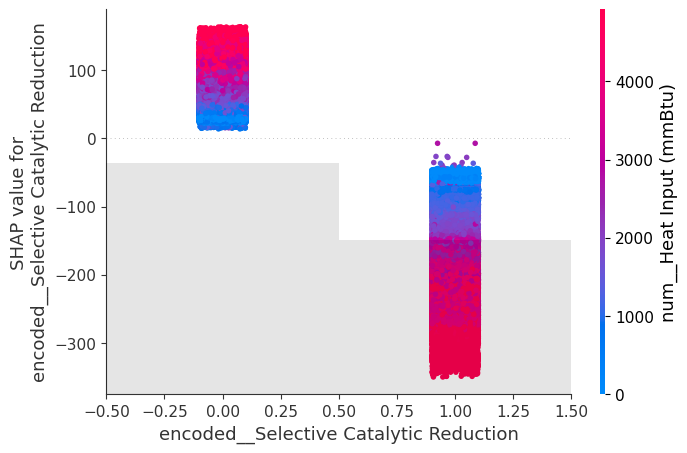

In [117]:
shap.plots.scatter(shap_values[:,"encoded__Selective Catalytic Reduction"], color=shap_values[:,"num__Heat Input (mmBtu)"])

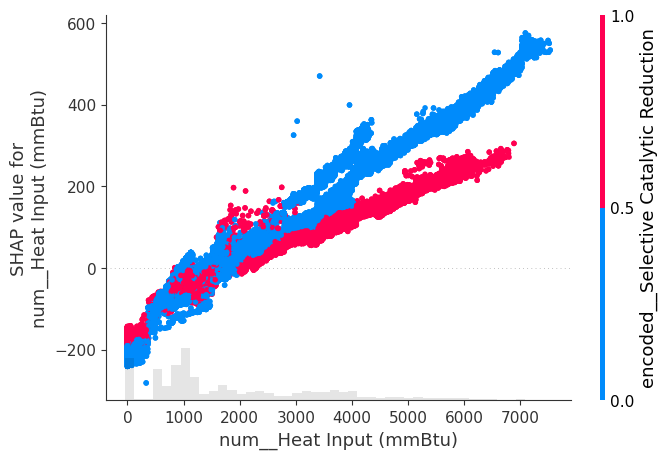

In [125]:
shap.plots.scatter(shap_values[indices,"num__Heat Input (mmBtu)"], color=shap_values[indices,"encoded__Selective Catalytic Reduction"])

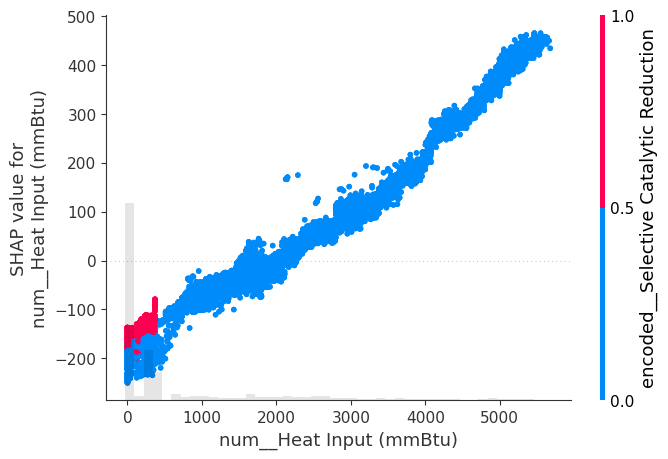

In [124]:
shap.plots.scatter(shap_values[indices_png,"num__Heat Input (mmBtu)"], color=shap_values[indices_png,"encoded__Selective Catalytic Reduction"])

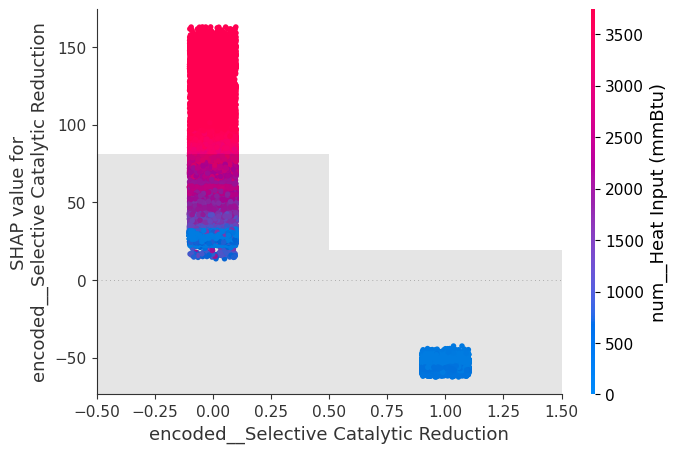

In [123]:
shap.plots.scatter(shap_values[indices_png,"encoded__Selective Catalytic Reduction"], color=shap_values[indices_png,"num__Heat Input (mmBtu)"])

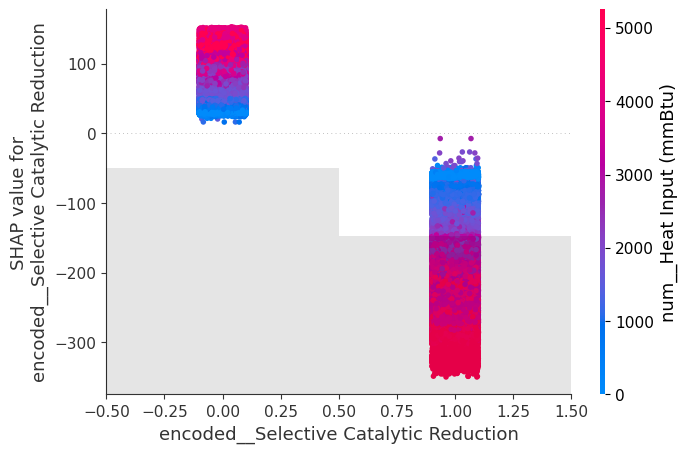

In [ ]:
shap.plots.scatter(shap_values[indices,"encoded__Selective Catalytic Reduction"], color=shap_values[indices,"num__Heat Input (mmBtu)"])

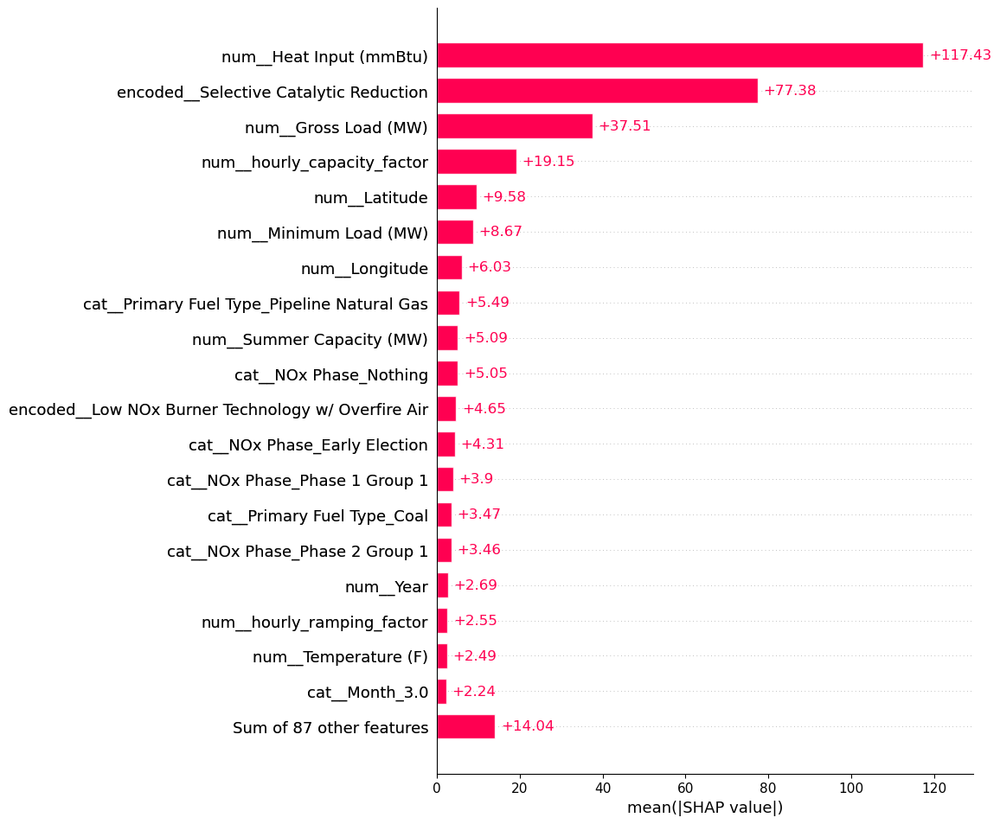

In [103]:
shap.plots.bar(shap_values, max_display=20) # global mean absolute shap values for comparison

In [ ]:
# define feature groups (important for aggregation of encoded cols)
feature_groups = {
    "Source Category": [
        'cat__Source Category_Cogeneration',
        'cat__Source Category_Electric Utility',
        'cat__Source Category_Missing'
    ],
    
    "NOx Phase": [
        'cat__NOx Phase_Early Election',
        'cat__NOx Phase_Nothing',
        'cat__NOx Phase_Phase 1 Group 1',
        'cat__NOx Phase_Phase 2 Group 1'
    ],
    
    "Unit Type": [
        'cat__Unit Type_Circulating fluidized bed boiler',
        'cat__Unit Type_Combined cycle',
        'cat__Unit Type_Combined cycle (Started Feb 23, 2020)',
        'cat__Unit Type_Combustion turbine',
        'cat__Unit Type_Dry bottom wall-fired boiler',
        'cat__Unit Type_Other boiler',
        'cat__Unit Type_Tangentially-fired'
    ],
    
    "Primary Fuel Type": [
        'cat__Primary Fuel Type_Coal',
        'cat__Primary Fuel Type_Diesel Oil',
        'cat__Primary Fuel Type_Natural Gas',
        'cat__Primary Fuel Type_Other Oil',
        'cat__Primary Fuel Type_Pipeline Natural Gas',
        'cat__Primary Fuel Type_Residual Oil',
        'cat__Primary Fuel Type_Wood'
    ],
    
    "Secondary Fuel Type": [
        'cat__Secondary Fuel Type_Diesel Oil',
        'cat__Secondary Fuel Type_Natural Gas, Wood',
        'cat__Secondary Fuel Type_Nothing',
        'cat__Secondary Fuel Type_Other Oil',
        'cat__Secondary Fuel Type_Other Solid Fuel, Petroleum Coke, Tire Derived Fuel',
        'cat__Secondary Fuel Type_Pipeline Natural Gas',
        'cat__Secondary Fuel Type_Residual Oil',
        'cat__Secondary Fuel Type_Wood'
    ],

    "Gross Load (MW)": ['num__Gross Load (MW)'],
    "Heat Input (mmBtu)": ['num__Heat Input (mmBtu)'],
    "Latitude": ['num__Latitude'],
    "Longitude": ['num__Longitude'],
    "Nameplate Capacity (MWe)": ['num__Nameplate Capacity (MWe)'],
    "hourly_capacity_factor": ['num__hourly_capacity_factor'],
    "hourly_ramping_factor": ['num__hourly_ramping_factor'],
    "Summer Capacity (MW)": ['num__Summer Capacity (MW)'],
    "Winter Capacity (MW)": ['num__Winter Capacity (MW)'],
    "Minimum Load (MW)": ['num__Minimum Load (MW)'],
    "Year": ['num__Year'],

    "Control Technologies": [
        'encoded__Ammonia Injection',
        'encoded__Combustion Modification/Fuel Reburning',
        'encoded__Dry Low NOx Burners',
        'encoded__Low NOx Burner Technology (Dry Bottom only)',
        'encoded__Low NOx Burner Technology w/ Closed-coupled OFA',
        'encoded__Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
        'encoded__Low NOx Burner Technology w/ Overfire Air',
        'encoded__Low NOx Burner Technology w/ Separated OFA',
        'encoded__Nothing',
        'encoded__Other',
        'encoded__Overfire Air',
        'encoded__Selective Catalytic Reduction',
        'encoded__Selective Non-catalytic Reduction',
        'encoded__Steam Injection',
        'encoded__Water Injection',
        'encoded__Water Injection (Began Jul 01, 2022)'
    ],

    "Programs / Regulations": [
        'encoded__ARP',
        'encoded__CSNOX',
        'encoded__CSOSG2',
        'encoded__CSOSG2E',
        'encoded__CSOSG3',
        'encoded__CSSO2G1',
        'encoded__MATS',
        'encoded__Missing',
        'encoded__NSPS4T',
        'encoded__RGGI',
        'encoded__SIPNOX'
    ],

    "Hour": [
        'encoded__Hour_sin',
        'encoded__Hour_cos'
    ],
    "Day": [
        'encoded__Day_sin',
        'encoded__Day_cos'
    ],
    "Month": [
        'encoded__Month_sin',
        'encoded__Month_cos'
    ],

    "Lag Features": [
        'encoded__lag_1_hour',
        'encoded__lag_2_hours',
        'encoded__lag_1_day',
        'encoded__lag_2_days',
        'encoded__lag_1_week',
        'encoded__lag_1_month',
        'encoded__lag_1_year'
    ]
}

In [ ]:
# Aggregate (sum) the shap values of encoded columns

# create series of mean absolute SHAP values per feature (using feature name as index)
mean_abs_shap = np.abs(shap_values.values).mean(axis=0) 
shap_importance = pd.Series(mean_abs_shap, index=shap_values.feature_names)

# aggregate by feature groups (sum the mean absolute values within pre-defined groups)
group_importance = {}
for group, features in feature_groups.items():
    group_importance[group] = shap_importance[features].sum() 

group_importance = pd.Series(group_importance).sort_values(ascending=False)

# plot
fig, ax = plt.subplots(figsize=(14, 8))
bars = ax.barh(group_importance.index, group_importance.values)
group_importance.plot(kind='barh')
ax.bar_label(bars, fmt='%.2f', label_type='edge', padding=3, fontsize=9) # add bar labels
plt.gca().invert_yaxis()  # invert to get largest at top
plt.title('Grouped Feature Importance')
plt.xlabel('Mean Absolute SHAP Value')
plt.tight_layout()
plt.show()


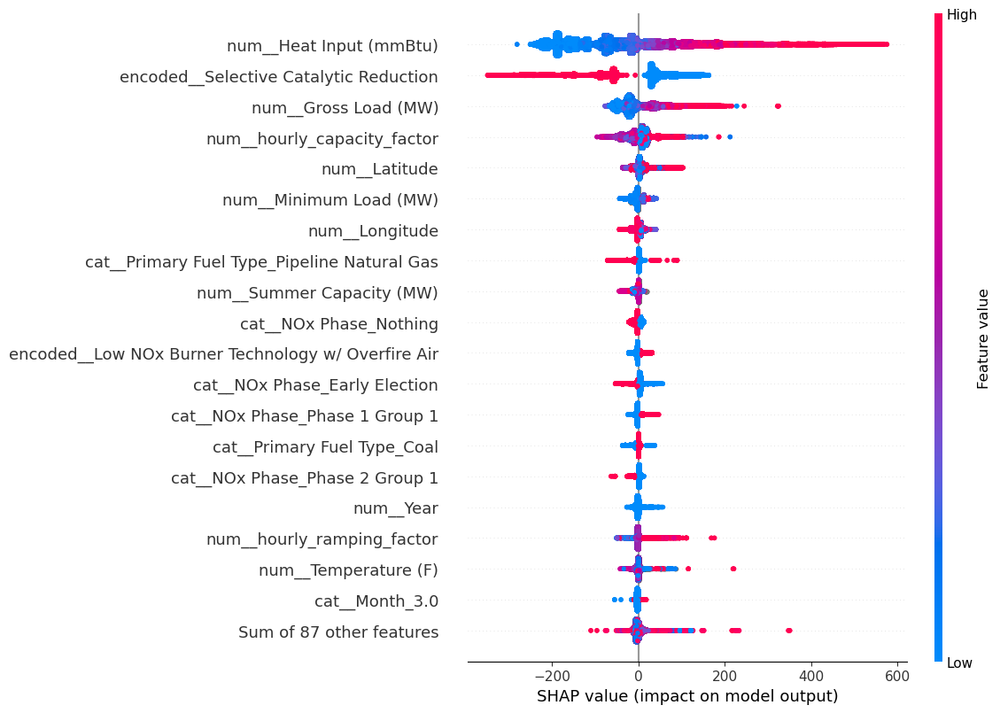

In [110]:
shap.plots.beeswarm(shap_values, max_display=20)

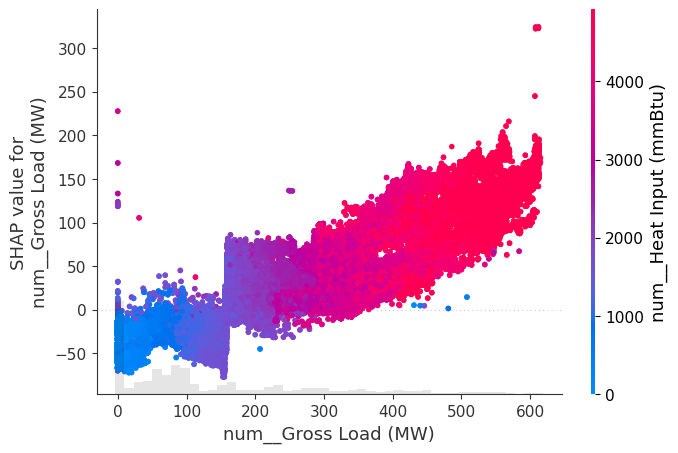

In [127]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"num__Heat Input (mmBtu)"])

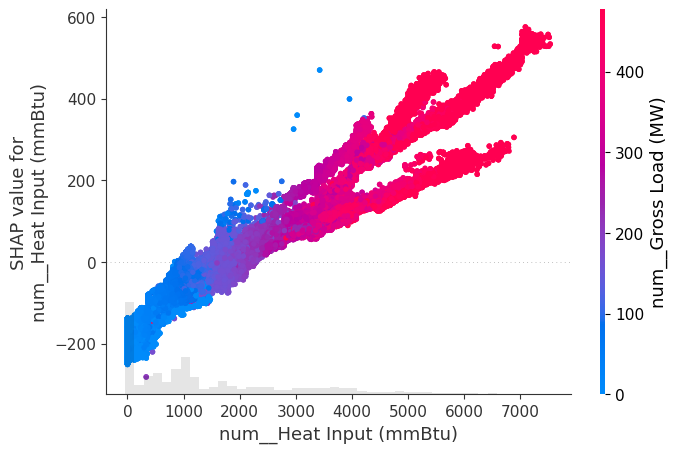

In [128]:
shap.plots.scatter(shap_values[:,"num__Heat Input (mmBtu)"], color=shap_values[:,"num__Gross Load (MW)"])

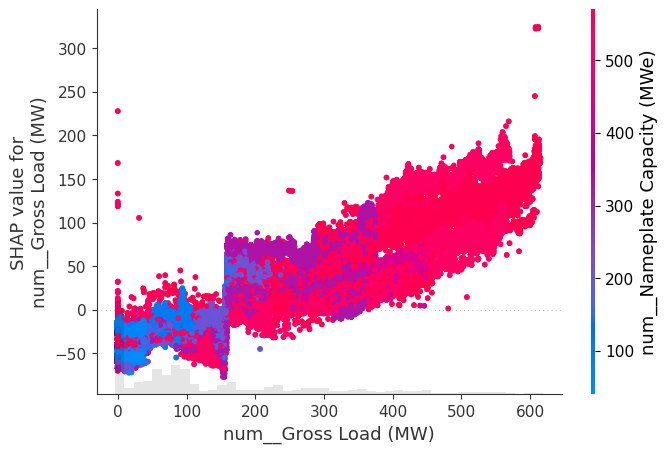

In [129]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"num__Nameplate Capacity (MWe)"])

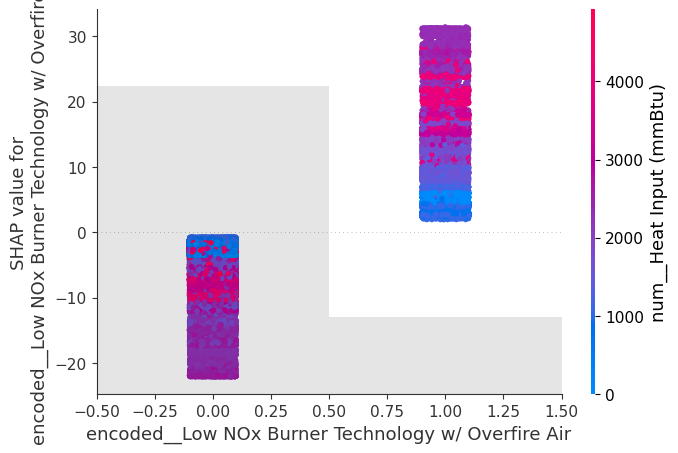

In [ ]:
shap.plots.scatter(shap_values[:,"encoded__Low NOx Burner Technology w/ Overfire Air"], color=shap_values[:,"num__Heat Input (mmBtu)"])

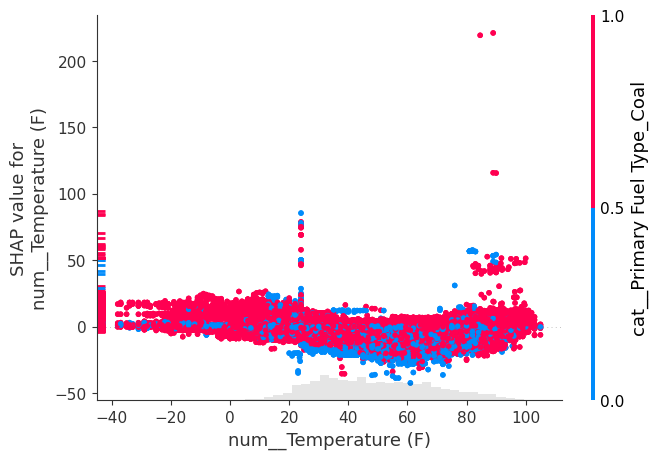

In [ ]:
shap.plots.scatter(shap_values[:,"num__Temperature (F)"], color=shap_values[:,"cat__Primary Fuel Type_"])



In [150]:
campd_df.groupby(by="Unit Type")["NOx Mass (lbs)"].sum()

Unit Type
Combined cycle                     262,930.84
Combustion turbine                 665,021.12
Dry bottom wall-fired boiler   353,806,176.00
Tangentially-fired             227,806,976.00
Name: NOx Mass (lbs), dtype: float32

In [ ]:
indices_tf = np.where(X_test["cat__Unit Type_Tangentially-fired"] == 1)[0]
indices_dbwfb = np.where(X_test["cat__Unit Type_Dry bottom wall-fired boiler"] == 1)[0]

In [ ]:
shap_values_dbwfb = shap_values[indices_dbwfb, "num__Heat Input (mmBtu)"]
shap_values_tf = shap_values[indices_tf, "num__Heat Input (mmBtu)"]

heat_input_dbwfb = X_test.iloc[indices_dbwfb]["num__Heat Input (mmBtu)"]  
heat_input_tf = X_test.iloc[indices_tf]["num__Heat Input (mmBtu)"]        

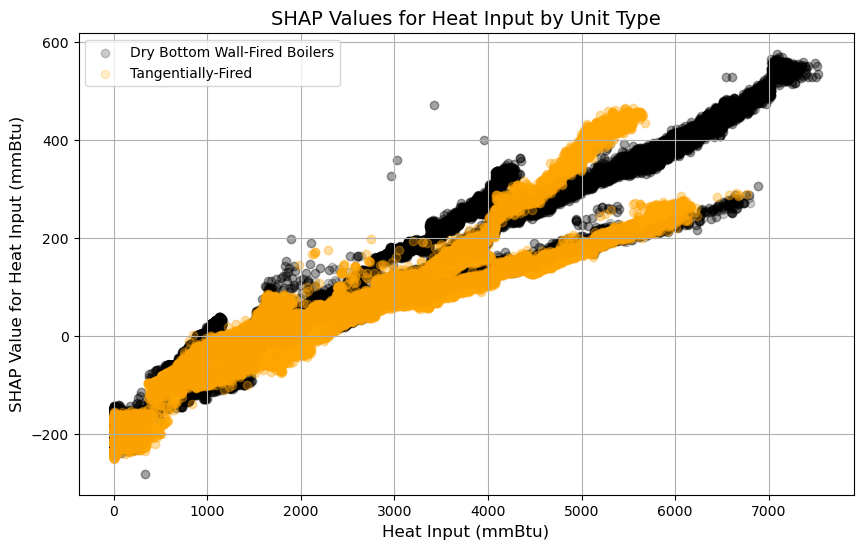

In [ ]:
# Compare Heat Input Behavior across two unit types

plt.figure(figsize=(10, 6))

plt.scatter(
    heat_input_dbwfb,
    shap_values_dbwfb.values,
    alpha=0.2,
    color="black",
    label="Dry Bottom Wall-Fired Boilers"
)

plt.scatter(
    heat_input_tf,
    shap_values_tf.values,
    alpha=0.2,
    color="orange",
    label="Tangentially-Fired"
)

plt.xlabel("Heat Input (mmBtu)", fontsize=12)
plt.ylabel("SHAP Value for Heat Input (mmBtu)", fontsize=12)
plt.title("SHAP Values for Heat Input by Unit Type", fontsize=14)
plt.legend(fontsize=10)
plt.grid(True)

plt.show()

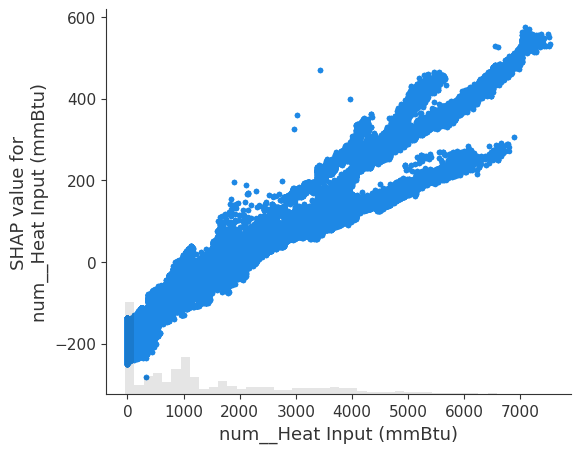

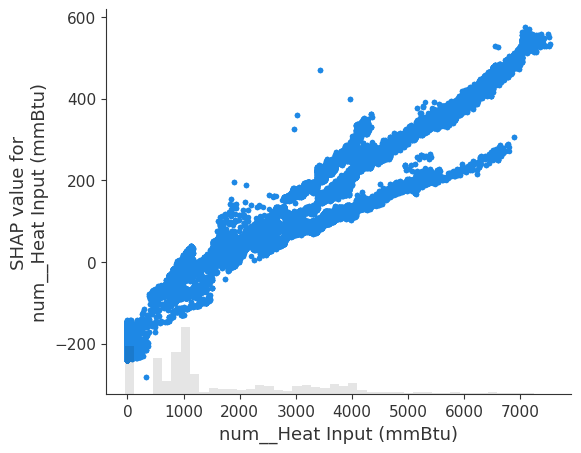

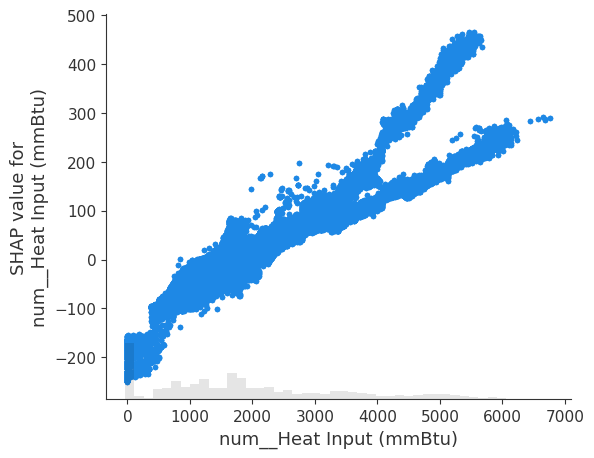

In [ ]:
shap.plots.scatter(shap_values[:,"num__Heat Input (mmBtu)"]) #, color=shap_values[:,"num__Heat Input (mmBtu)"])
shap.plots.scatter(shap_values[indices_dbwfb,"num__Heat Input (mmBtu)"]) #, color=shap_values[:,"num__Heat Input (mmBtu)"])
shap.plots.scatter(shap_values[indices_tf,"num__Heat Input (mmBtu)"]) #, color=shap_values[:,"num__Heat Input (mmBtu)"])

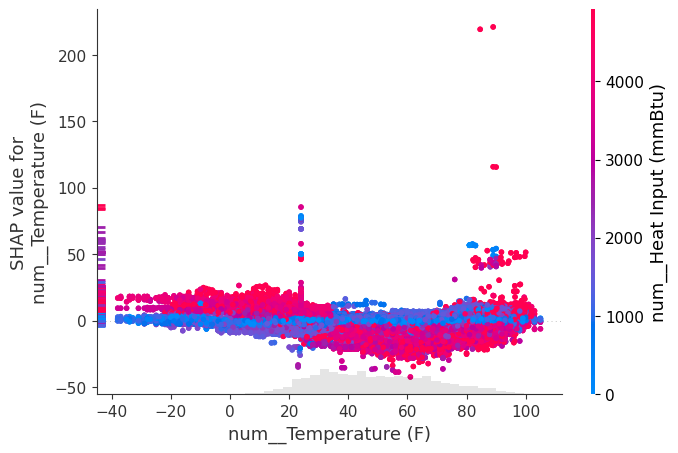

In [133]:
shap.plots.scatter(shap_values[:,"num__Temperature (F)"], color=shap_values[:,"num__Heat Input (mmBtu)"])

<h5>SHAP Interaction Values</h5>

In [45]:
X_test_sample = X_test.sample(n=100000, random_state=42)

In [ ]:
interaction_values_shap = explainer.shap_interaction_values(X_test_sample)

# took 45 mins

In [165]:
joblib.dump(interaction_values_shap, "WY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/interaction_values_shap_xgb_default_model_wy_no_lags_with_unmeasured_with_temps.pkl", compress=True)

['WY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/interaction_values_shap_xgb_default_model_wy_no_lags_with_unmeasured_with_temps.pkl']

In [11]:
interaction_values_shap = joblib.load("WY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/interaction_values_shap_xgb_default_model_wy_no_lags_with_unmeasured_with_temps.pkl")

In [24]:
shap_values.feature_names[83]

'num__Heat Input (mmBtu)'

In [29]:
f = 83 # Heat Input index
main_effects = interaction_values_shap[:, f, f]
interactions = interaction_values_shap[:, f, :].sum(axis=1) - main_effects

In [ ]:
# compute total difference in global shap values between the two calculations

global_shap_vals_interact = np.zeros(interaction_values_shap.shape[1])
global_shap_vals_original = np.zeros(interaction_values_shap.shape[1])

# 
for f in range(interaction_values_shap.shape[1]):
    # Sum interaction values for feature f across all interactions 
    # then take absolute value and average over samples 
    
    global_shap_vals_interact[f] = np.abs(interaction_values_shap[:, f, :].sum(axis=1)).mean()


    # Mean absolute shap value for feature f from original shap values
    global_shap_vals_original[f] = np.abs(shap_values.values[:, f]).mean()

In [32]:
print(np.abs(main_effects + interactions).mean()) # should be equal to the mean absolute shap value for feature f

117.58485


In [36]:
global_shap_vals_interact[2]


2.230940103530884

In [37]:
global_shap_vals_original[2]

2.2407960891723633

Mean absolute difference: 0.007782
Max absolute difference: 0.206810
Min absolute difference: 0.000000


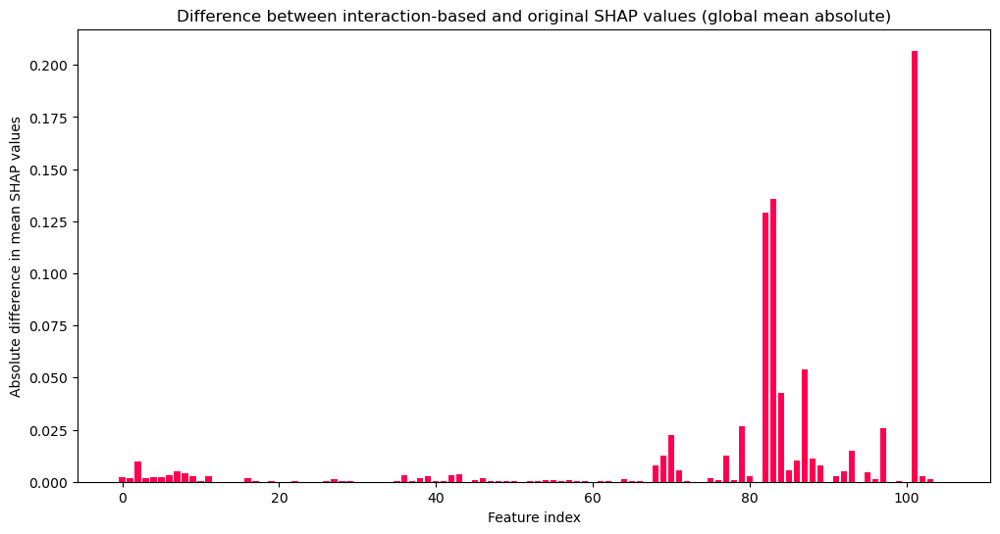

In [38]:
# Compute the absolute differences between the two sets
differences = np.abs(global_shap_vals_interact - global_shap_vals_original)

# Summary stats
print(f"Mean absolute difference: {differences.mean():.6f}")
print(f"Max absolute difference: {differences.max():.6f}")
print(f"Min absolute difference: {differences.min():.6f}")

plt.figure(figsize=(12, 6))
plt.bar(range(len(differences)), differences, color='#FF0051')
plt.xlabel('Feature index')
plt.ylabel('Absolute difference in mean SHAP values')
plt.title('Difference between interaction-based and original SHAP values (global mean absolute)')
plt.show()

# very small differences, maximum is 0.05

In [39]:
feature_names = shap_values.feature_names

n_samples, n_features, _ = interaction_values_shap.shape

# Mean interaction values for each feature pair (averaged over samples)
signed_mean_interactions = interaction_values_shap.mean(axis=0)  # shape (n_features, n_features)
abs_mean_interactions = np.abs(interaction_values_shap).mean(axis=0)

# Flatten to 1D arrays for sorting (before it was shape (n_features, n_features))
flat_mean_abs = abs_mean_interactions.flatten()
flat_mean_signed = signed_mean_interactions.flatten()
# it becomes a 1D array of shape (n_features^2)

# Indices to map back to (feature1, feature2)
idxs = np.array([(i, j) for i in range(n_features) for j in range(n_features)])
# creates an array of tuples (i, j) for each feature pair (each index) with length n_features^2
# we use it to map feature names back later

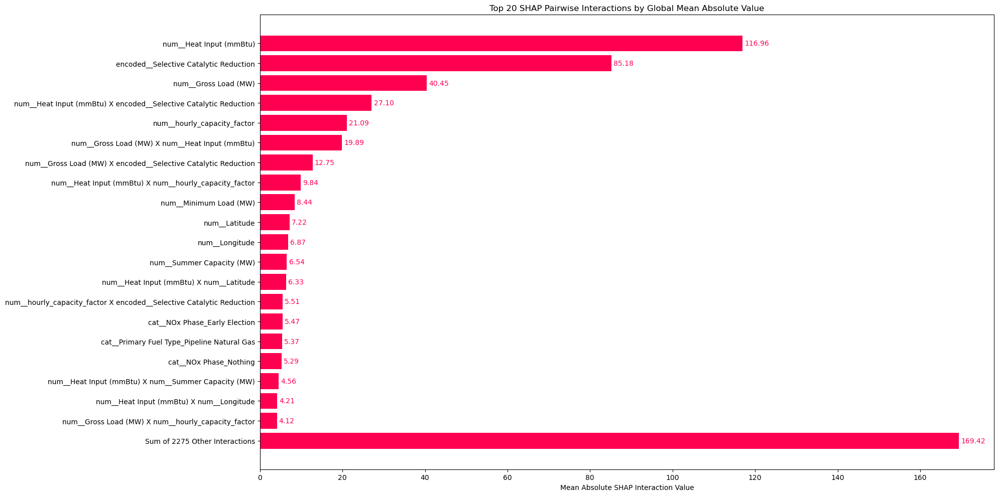

In [ ]:
# Top 20 Mean Absolute SHAP Interactions

# Indices to map back to (feature1, feature2), filtering symmetric duplicates
idxs = np.array([(i, j) for i in range(n_features) for j in range(i, n_features)])
# Now idxs only contains pairs where i <= j to avoid duplicates

# Updated flat_mean_abs and flat_mean_signed to account for symmetry reduction
flat_mean_abs = abs_mean_interactions[np.triu_indices(n_features)].flatten()
flat_mean_signed = signed_mean_interactions[np.triu_indices(n_features)].flatten()
# Using np.triu_indices ensures only upper-triangular values are considered (i <= j)

# Filter out zero values by masking them before sorting
nonzero_mask = flat_mean_abs > 0
nonzero_indices = np.where(nonzero_mask)[0]
nonzero_values = flat_mean_abs[nonzero_mask]

# Get top 20 indices (in descending order) from non-zero interactions only
top20_abs_idx_nonzero = nonzero_indices[np.argsort(nonzero_values)[-20:][::-1]]
top20_abs_set = set(top20_abs_idx_nonzero)

# Values and labels for top 20 non-zero interactions
top20_abs = [((feature_names[i], feature_names[j]), flat_mean_abs[idx]) 
             for idx, (i, j) in zip(top20_abs_idx_nonzero, idxs[top20_abs_idx_nonzero])]
labels_abs = [f"{f1}" if f1 == f2 else f"{f1} X {f2}" for (f1, f2), _ in top20_abs]
raw_values_abs = [v for _, v in top20_abs]

# Sum of others excluding top 20 and zero interactions
all_nonzero_indices = set(nonzero_indices)
other_abs_idx = list(all_nonzero_indices - top20_abs_set)
sum_other_abs = flat_mean_abs[other_abs_idx].sum()

# Append summary
labels_abs.append(f"Sum of {len(other_abs_idx)} Other Interactions")
raw_values_abs.append(sum_other_abs)

# All absolute values, one color
bar_colors_abs = ['#FF0051'] * len(labels_abs)

# Plot Absolute Interactions
plt.figure(figsize=(20, 10))
bars_abs = plt.barh(range(len(labels_abs)), raw_values_abs, color=bar_colors_abs)
plt.yticks(range(len(labels_abs)), labels_abs)
plt.xlabel("Mean Absolute SHAP Interaction Value")
plt.title("Top 20 SHAP Pairwise Interactions by Global Mean Absolute Value")
plt.gca().invert_yaxis()

# Annotate bars
for bar, val in zip(bars_abs, raw_values_abs):
    plt.text(bar.get_width() + 0.5,
             bar.get_y() + bar.get_height() / 2,
             f"{val:.2f}", va='center', ha='left', color=bar.get_facecolor())

plt.tight_layout()
plt.show()

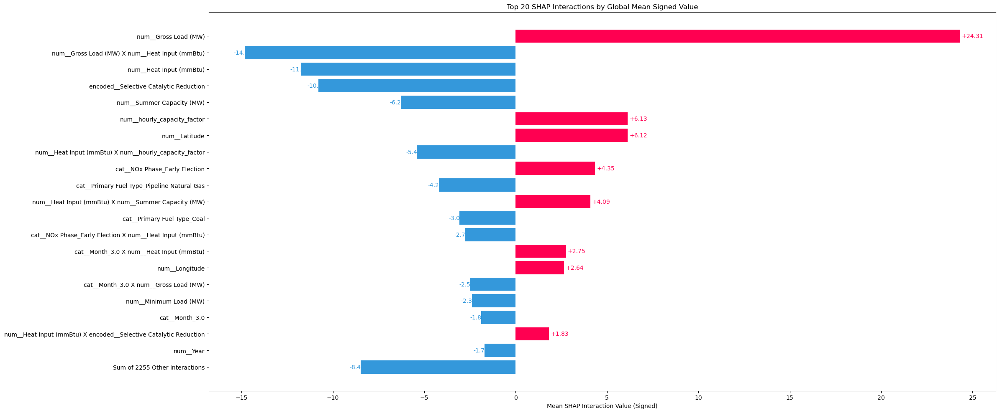

In [43]:
# Mask to exclude zero interactions
nonzero_mask_signed = flat_mean_signed != 0
nonzero_indices_signed = np.where(nonzero_mask_signed)[0]
nonzero_values_signed = flat_mean_signed[nonzero_mask_signed]

# Top 20 positive interactions (non-zero)
pos_mask = nonzero_values_signed > 0
pos_indices = nonzero_indices_signed[pos_mask]
pos_values = nonzero_values_signed[pos_mask]
top20_signed_idx = pos_indices[np.argsort(pos_values)[-20:]]

# Top 20 negative interactions (non-zero)
neg_mask = nonzero_values_signed < 0
neg_indices = nonzero_indices_signed[neg_mask]
neg_values = nonzero_values_signed[neg_mask]
top20_neg_idx = neg_indices[np.argsort(neg_values)[:20]]

# Combine and deduplicate
top20_signed_combined_idx = np.unique(np.concatenate((top20_signed_idx, top20_neg_idx)))

# Create list of (features, value)
top20_signed_combined = [((feature_names[i], feature_names[j]), flat_mean_signed[idx])
                         for idx, (i, j) in zip(top20_signed_combined_idx, idxs[top20_signed_combined_idx])]

# Sort by absolute value descending and keep top 20
top20_signed_combined = sorted(top20_signed_combined, key=lambda x: abs(x[1]), reverse=True)[:20]

# Extract labels and values for plotting
labels_signed = [f"{f1}" if f1 == f2 else f"{f1} X {f2}" for (f1, f2), _ in top20_signed_combined]
raw_values_signed = [v for _, v in top20_signed_combined]
bar_colors_signed = ['#FF0051' if v >= 0 else '#3498DB' for v in raw_values_signed]

# Sum of all other non-zero signed interactions (excluding the top 20 combined)
top_combined_idx_set = set(top20_signed_combined_idx)
all_nonzero_indices_set = set(nonzero_indices_signed)
other_signed_idx = list(all_nonzero_indices_set - top_combined_idx_set)
sum_other_signed = flat_mean_signed[other_signed_idx].sum()

# Append summary bar
labels_signed.append(f"Sum of {len(other_signed_idx)} Other Interactions")
raw_values_signed.append(sum_other_signed)
bar_colors_signed.append('#FF0051' if sum_other_signed >= 0 else '#3498DB')

# Plot Signed Interactions
plt.figure(figsize=(24, 10))
bars_signed = plt.barh(range(len(labels_signed)), raw_values_signed, color=bar_colors_signed)
plt.yticks(range(len(labels_signed)), labels_signed)
plt.xlabel("Mean SHAP Interaction Value (Signed)")
plt.title("Top 20 SHAP Interactions by Global Mean Signed Value")
plt.gca().invert_yaxis()

# Annotate bars
for bar, val in zip(bars_signed, raw_values_signed):
    offset = 0.1 * np.sign(val) - (0.5 if val < 0 else 0)
    plt.text(bar.get_width() + offset,
             bar.get_y() + bar.get_height() / 2,
             f"{val:+.2f}", va='center', ha='left', color=bar.get_facecolor())

plt.tight_layout()
plt.show()

# would be better for individual predictions, interactions cancel each other out here so not very meaningful overall


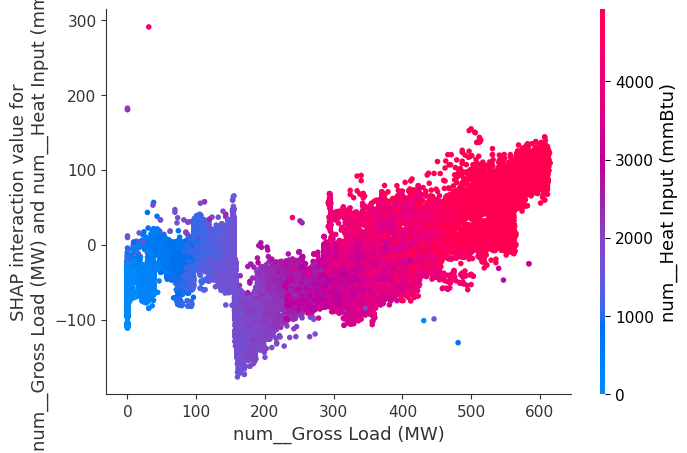

In [46]:
shap.dependence_plot(("num__Gross Load (MW)", "num__Heat Input (mmBtu)"), interaction_values_shap, X_test_sample, show=True)

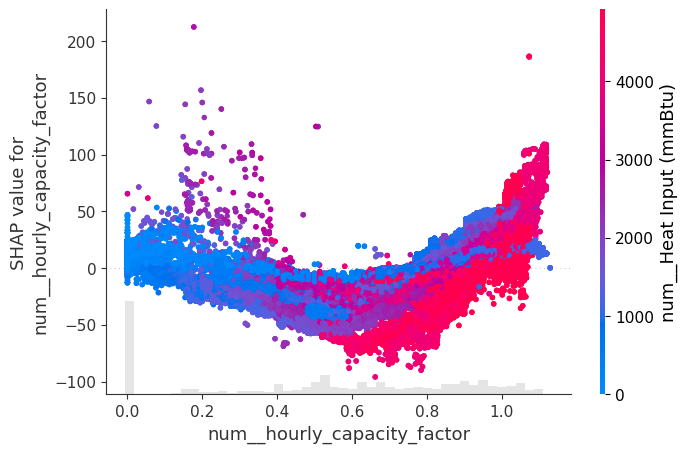

In [ ]:
shap.plots.scatter(shap_values[:, "num__hourly_capacity_factor"], color=shap_values[:, "num__Heat Input (mmBtu)"])

# (remember that the model is predicting total mass, not relative to heat input)
# the model appears to learn that low capacities are associated with inefficiencies and thus relatively higher emissions
# medium range capacities are associated with relatively low emissions
# but running units with very high heat input creates high emissions and is correlated with high capacity -> rise again towards 1.0 and beyond

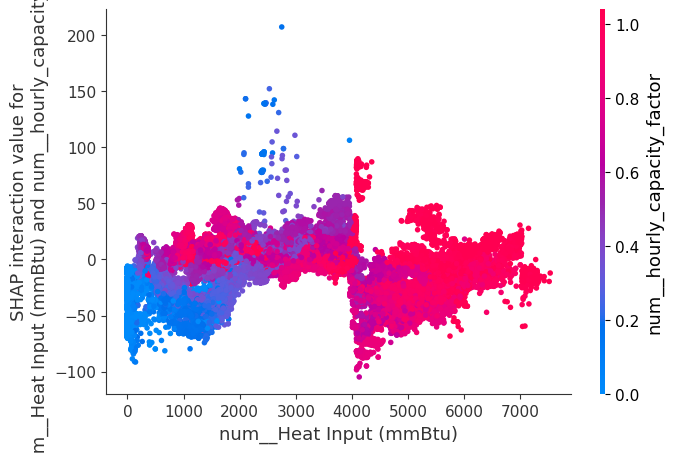

In [55]:
shap.dependence_plot(("num__Heat Input (mmBtu)", "num__hourly_capacity_factor"), interaction_values_shap, X_test_sample, show=True)


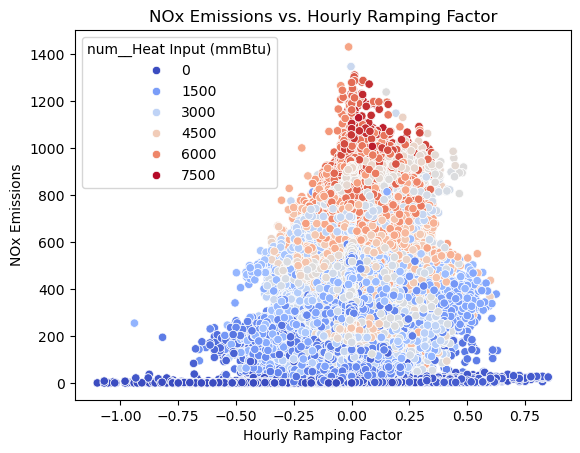

In [72]:
sns.scatterplot(x=X_test["num__hourly_ramping_factor"], y=y_test, hue=X_test["num__Heat Input (mmBtu)"], palette="coolwarm")
plt.xlabel("Hourly Ramping Factor")
plt.ylabel("NOx Emissions")
plt.title("NOx Emissions vs. Hourly Ramping Factor")
plt.show()

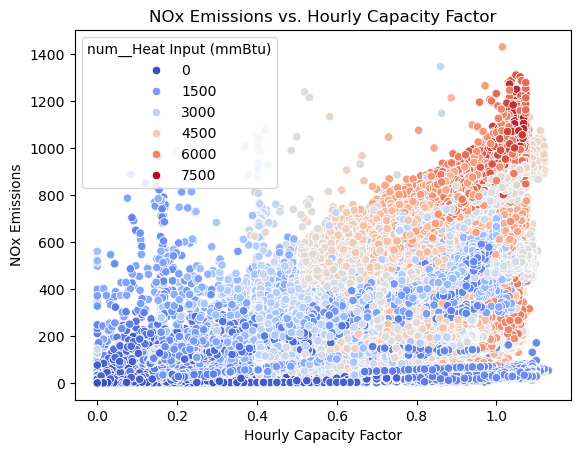

In [ ]:
sns.scatterplot(x=X_test["num__hourly_capacity_factor"], y=y_test, hue=X_test["num__Heat Input (mmBtu)"], palette="coolwarm")
plt.xlabel("Hourly Capacity Factor")
plt.ylabel("NOx Emissions")
plt.title("NOx Emissions vs. Hourly Capacity Factor")
plt.show()

# the increase in NOx mass at higher capacities is driven by the increase in heat input
# -> the model learns this correlation

In [ ]:
nox_per_energy = y_test / X_test["num__Heat Input (mmBtu)"]
sns.scatterplot(x=X_test["num__hourly_capacity_factor"], y=nox_per_energy, hue=X_test["num__Heat Input (mmBtu)"], palette="coolwarm")
plt.xlabel("Hourly Capacity Factor")
plt.ylabel("NOx Emissions per mmBtu")
plt.title("NOx Emissions per Heat Input (mmBtu) vs. Hourly Capacity Factor")
plt.show()

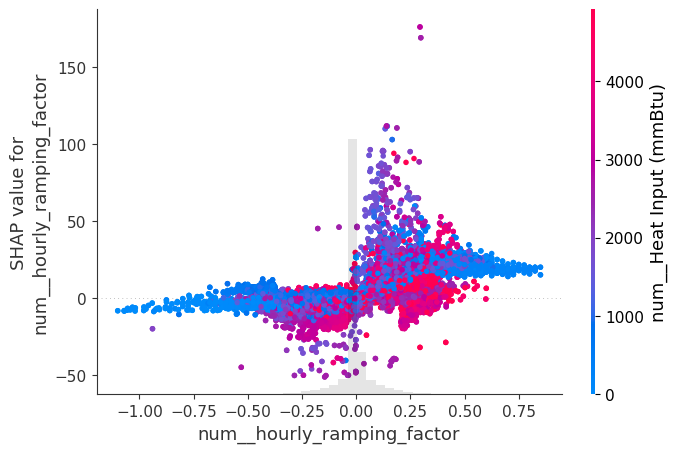

In [ ]:
shap.plots.scatter(shap_values[:, "num__hourly_ramping_factor"], color=shap_values[:, "num__Heat Input (mmBtu)"])

# especially slightly higher ramping factors are associated with greater emissions

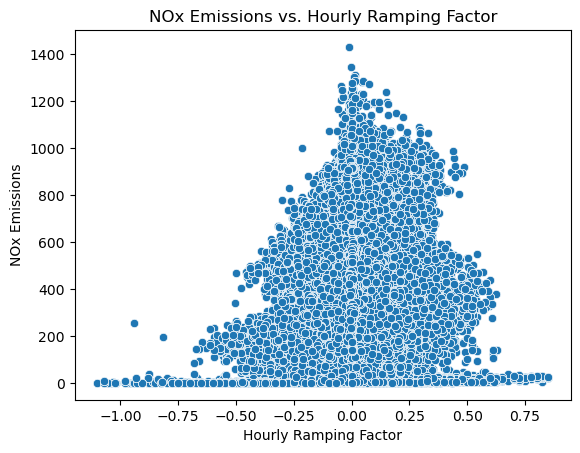

In [75]:
sns.scatterplot(x=X_test["num__hourly_ramping_factor"], y=y_test) #, hue=X_test["num__Heat Input (mmBtu)"], palette="coolwarm")
plt.xlabel("Hourly Ramping Factor")
plt.ylabel("NOx Emissions")
plt.title("NOx Emissions vs. Hourly Ramping Factor")
plt.show()


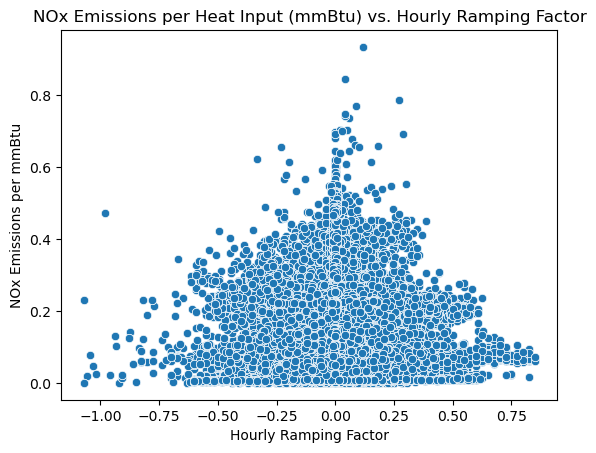

In [ ]:
nox_per_energy = y_test / X_test["num__Heat Input (mmBtu)"]
sns.scatterplot(x=X_test["num__hourly_ramping_factor"], y=nox_per_energy) #, hue=X_test["num__Heat Input (mmBtu)"], palette="coolwarm")
plt.xlabel("Hourly Ramping Factor")
plt.ylabel("NOx Emissions per mmBtu")
plt.title("NOx Emissions per Heat Input (mmBtu) vs. Hourly Ramping Factor")
plt.show()

# counter-intuitively, relative NOx  are highest around ramping factor 0 and decrease symmetrically
# though the shap values show that positive values especially are associated with higher emissions

c:\Users\marce\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


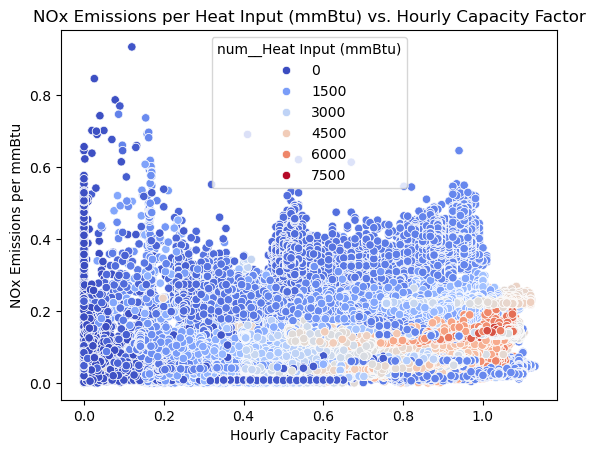

In [ ]:
nox_per_energy = y_test / X_test["num__Heat Input (mmBtu)"]
sns.scatterplot(x=X_test["num__hourly_capacity_factor"], y=nox_per_energy, hue=X_test["num__Heat Input (mmBtu)"], palette="coolwarm")
plt.xlabel("Hourly Capacity Factor")
plt.ylabel("NOx Emissions per mmBtu")
plt.title("NOx Emissions per Heat Input (mmBtu) vs. Hourly Capacity Factor")
plt.show()

# plotting relative emissions shows little relationship with capacity

In [56]:
X_test["num__hourly_capacity_factor"].describe()

count    435797.000000
mean          0.517927
std           0.368357
min           0.000000
25%           0.139623
50%           0.549057
75%           0.856716
max           1.130000
Name: num__hourly_capacity_factor, dtype: float64

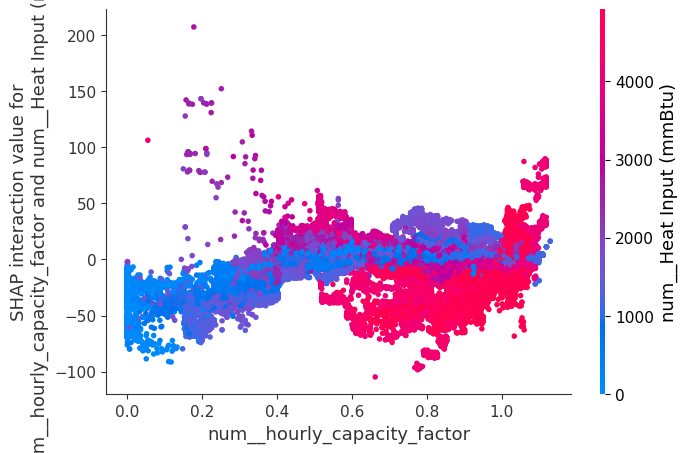

In [ ]:
shap.dependence_plot(("num__hourly_capacity_factor","num__Heat Input (mmBtu)"), interaction_values_shap, X_test_sample, show=True)

# 

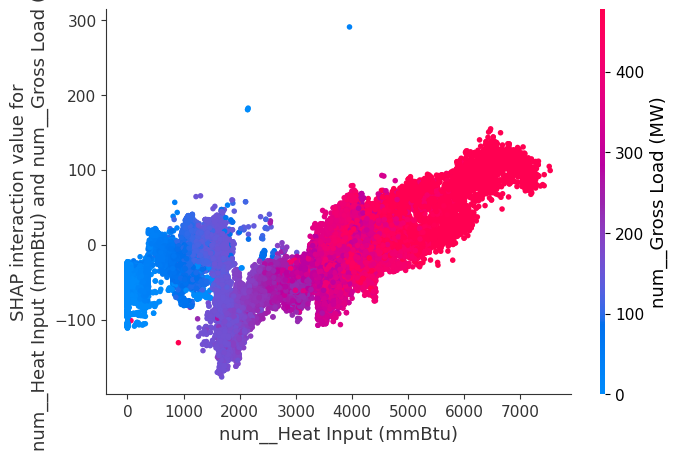

In [47]:
shap.dependence_plot(("num__Heat Input (mmBtu)", "num__Gross Load (MW)"), interaction_values_shap, X_test_sample, show=True)

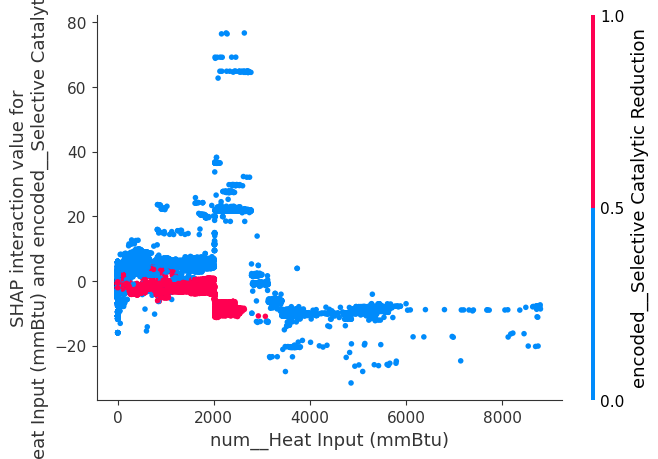

In [ ]:
shap.dependence_plot(("num__Heat Input (mmBtu)", "encoded__Selective Catalytic Reduction"), interaction_values_shap, X_test_sample, show=True)

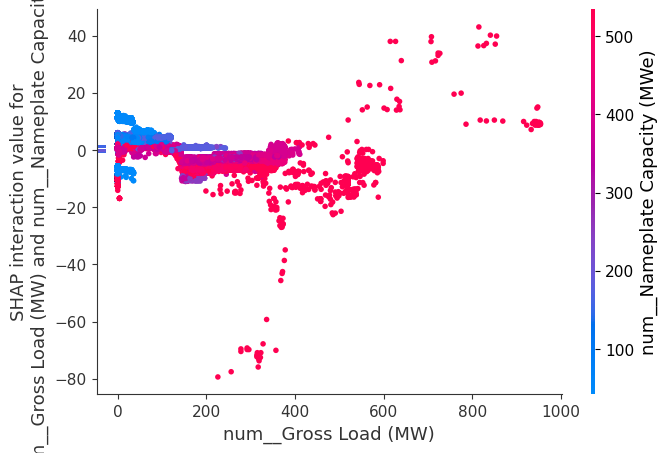

In [ ]:
shap.dependence_plot(("num__Gross Load (MW)", "num__Nameplate Capacity (MWe)"), interaction_values_shap, X_test_sample, show=True)

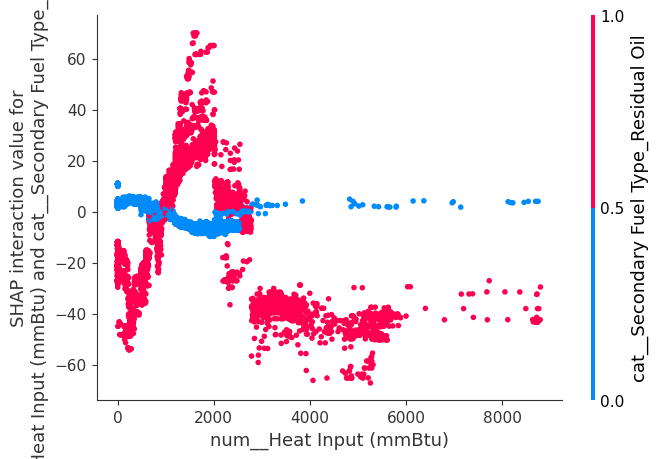

In [ ]:
shap.dependence_plot(("num__Heat Input (mmBtu)", "cat__Secondary Fuel Type_Residual Oil"), interaction_values_shap, X_test_sample, show=True)

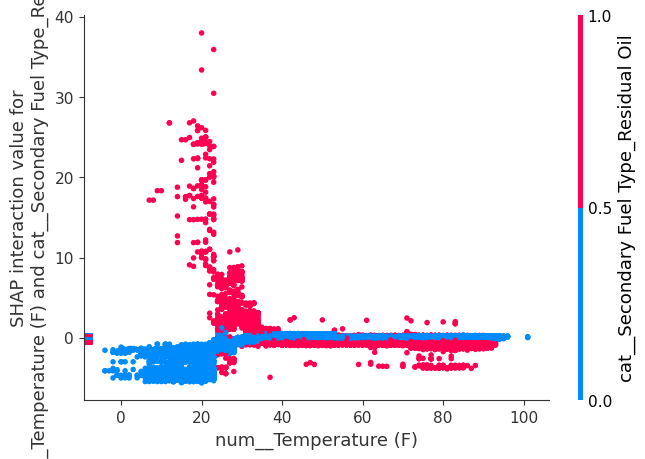

In [ ]:
shap.dependence_plot(("num__Temperature (F)", "cat__Secondary Fuel Type_Residual Oil"), interaction_values_shap, X_test_sample, show=True)

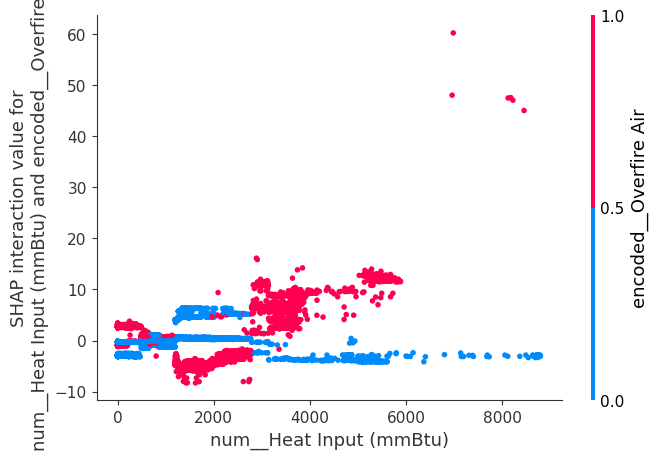

In [ ]:
shap.dependence_plot(("num__Heat Input (mmBtu)", "encoded__Overfire Air"), interaction_values_shap, X_test_sample)
# interaction values prove this

<h4>shapiq</h4>

In [10]:
import shapiq

In [11]:
default_params

{'objective': 'reg:squarederror', 'eval_metric': 'rmse', 'seed': 42}

In [12]:
from xgboost import XGBRegressor

# create an XGBRegressor because shapiq doesn't work with booster objects
model = XGBRegressor(**default_params)
model.fit(X_train, y_train)


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric='rmse', feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=None, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=None, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=None, n_jobs=None,
             num_parallel_tree=None, random_state=None, ...)

In [ ]:
explainer_shapiq = shapiq.TreeExplainer(model=model, max_order=2)

In [ ]:
X_test_sample_array = X_test.sample(n=100000, random_state=42).to_numpy()
interaction_values_shapiq = explainer_shapiq.explain_X(X_test_sample_array, index="SII", n_jobs=-1)
# specify to use "SII" instead "k-SII" -> we only want pairwise interactions like in normal SHAP package
# this ran for 2 hours without finishing


In [16]:
X_test_sample_array = X_test.sample(n=100, random_state=42).to_numpy()

interaction_values_shapiq = explainer_shapiq.explain_X(X_test_sample_array, n_jobs=-1)

# this took XY mins
# WRITE DOWN HOW LONG IT TOOK
# LOOK AT DEPENDENCE PLOT AT THE TOP FOR TOP INTERACTIONS AND DIRECTIONALITY
# HOW DO SHAPIQ INTERACTIONS COMPARE TO SHAP INTERACTIONS? DIFFERENT ALGORITHMS?
# E. G. INTERACTION HEAT INPUT AND GROSS LOAD

In [14]:
X_test_sample_array = X_test.sample(n=100, random_state=42).to_numpy()

interaction_values_shapiq = explainer_shapiq.explain_X(X_test_sample_array, index="SII", n_jobs=-1)

# this took XY mins
# WRITE DOWN HOW LONG IT TOOK
# LOOK AT DEPENDENCE PLOT AT THE TOP FOR TOP INTERACTIONS AND DIRECTIONALITY
# HOW DO SHAPIQ INTERACTIONS COMPARE TO SHAP INTERACTIONS? DIFFERENT ALGORITHMS?
# E. G. INTERACTION HEAT INPUT AND GROSS LOAD

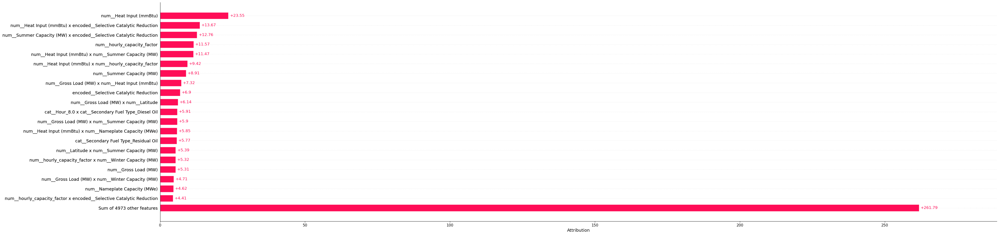

In [15]:
shapiq.plot.bar_plot(interaction_values_shapiq, feature_names=X_test.columns.tolist(), max_display=20, show=True, abbreviate=False)

In [19]:
shapiq.plot.waterfall_plot(interaction_values_shapiq, feature_names=X_test.columns, show=True, abbreviate=False)

AttributeError: 'list' object has no attribute 'n_players'

In [ ]:
# ALSO MAYBE TRY PREDICTING NOx FROM ANOTHER RGGI STATE USING THE WY MODEL TO SHOW LIMITED TRANSFERABILITY

In [ ]:
joblib.dump(interaction_values_shapiq, "WY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/interaction_values_shapiq_xgb_default_model_wy_no_lags_no_unmeasured_with_temps.pkl", compress=True)

['NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/interaction_values_xgb_default_model_ny_no_lags_no_unmeasured_with_temps.pkl']

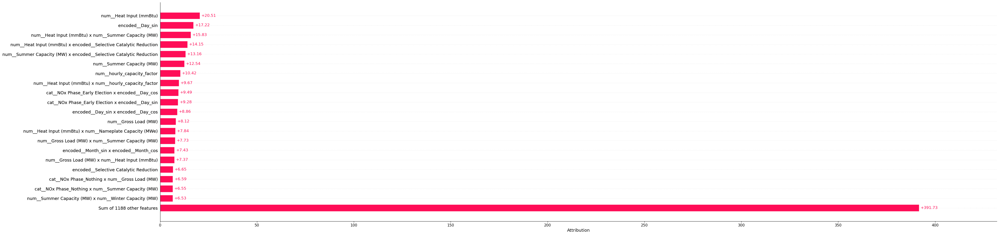

In [ ]:
shapiq.plot.bar_plot(list_of_interaction_values, feature_names=X_test.columns.tolist(), max_display=20, show=True, abbreviate=False)

In [304]:
interaction_values = explainer_shapiq.explain(X_test.iloc[2000])
print(interaction_values)

c:\Users\marce\anaconda3\Lib\site-packages\shapiq\explainer\tree\treeshapiq.py:180: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  x_relevant = x[self._relevant_features]
c:\Users\marce\anaconda3\Lib\site-packages\shapiq\explainer\tree\treeshapiq.py:320: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if x[child_edge_feature] <= feature_threshold:


InteractionValues(
    index=k-SII, max_order=2, min_order=0, estimated=False, estimation_budget=None,
    n_players=73, baseline_value=21.24664253362357,
    Top 10 interactions:
        (30, 51): 61.865503774544855
        (30, 36): 41.76005722528839
        (69,): 36.610711633194704
        (36, 51): 31.057869709942327
        (3, 70): 22.735285441776984
        (29,): 21.406142721995078
        (): 21.24664253362357
        (34, 36): 20.917203006279173
        (3, 69): -20.838209959600213
        (30, 31): -26.451239804108916
)


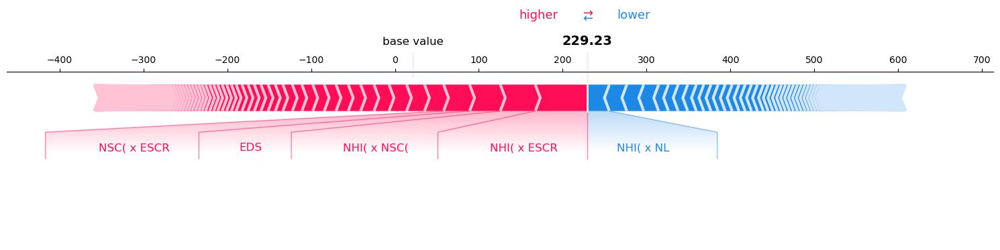

In [253]:
interaction_values.plot_force(feature_names=X_test.columns, abbreviate=True, contribution_threshold=0.03)

In [ ]:
X_test_sample = X_test.sample(n=2000, random_state=42)
X_test_array = X_test_sample.to_numpy()

In [ ]:
X_test_small = X_test_array[:1000]
interaction_values = explainer_shapiq.explain_X(X_test_small, budget=256, n_jobs=-1)


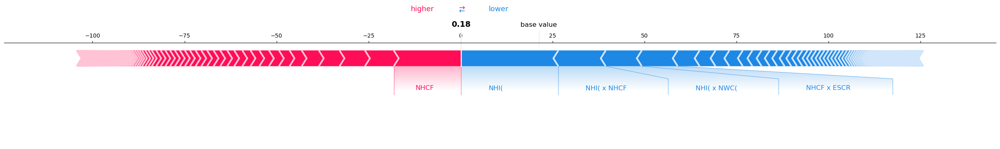

In [286]:
shapiq.plot.force_plot(explanation, feature_names=X_test.columns, show=True, abbreviate=True, figsize=(25,4))

In [289]:
y_pred[0]

0.049161565

In [273]:
explanation.dict_values

{(): 21.24664253362357,
 (3,): 0.010116192353452177,
 (4,): 2.8852820410238187,
 (5,): -0.0018342788388277626,
 (8,): -0.050556700028876696,
 (18,): 2.232573874403288,
 (27,): -5.949784035694675,
 (29,): 6.912368211716091,
 (30,): -26.385748366828764,
 (31,): 0.20066403911291167,
 (33,): -1.0558655633671323,
 (34,): 18.32777062274561,
 (35,): -0.4164808687782936,
 (36,): 2.3963361683612083,
 (37,): 7.833275079031403,
 (48,): -0.03287189180138845,
 (50,): 0.6220878739498158,
 (51,): 5.623920674455167,
 (71,): 1.5570077274585223,
 (72,): 1.385087303814235,
 (3, 4): -0.002900521410567616,
 (3, 5): 0.0,
 (3, 8): 0.0,
 (3, 18): -0.20046050347618039,
 (3, 27): 0.05851231018565594,
 (3, 29): 0.17748192854782077,
 (3, 30): 0.10192031961110799,
 (3, 31): -0.007066022481051599,
 (3, 33): 0.03323761386403886,
 (3, 34): 0.005024052470390323,
 (3, 35): -0.053982396776276725,
 (3, 36): 0.014134244889001009,
 (3, 37): -0.020213351888961745,
 (3, 48): 0.0,
 (3, 50): 0.003043905812738481,
 (3, 51): 0.0

In [ ]:
# Get the feature names and values for the data point
feature_names = list(X_test.columns)
x0 = X_test.iloc[0]

# Replace tuple indices with actual names + values and sort by abs value
sorted_named_values = sorted(
    {
        tuple(f"{feature_names[i]} ({x0[i]})" for i in k): v
        for k, v in interaction_values.dict_values.items()
    }.items(),
    key=lambda x: abs(x[1]),
    reverse=True
)

# Display top 10 interactions
top_10 = sorted_named_values[:10]
for features, value in top_10:
    name = " & ".join(features)
    print(f"{name}: {value:.4f}")


In [52]:

X_test_sample = X_test.sample(n=360)
X_test_array = X_test_sample.to_numpy()
list_of_interaction_values = explainer_shapiq.explain_X(X_test_array, budget=256, n_jobs=-1)
len(list_of_interaction_values)

360

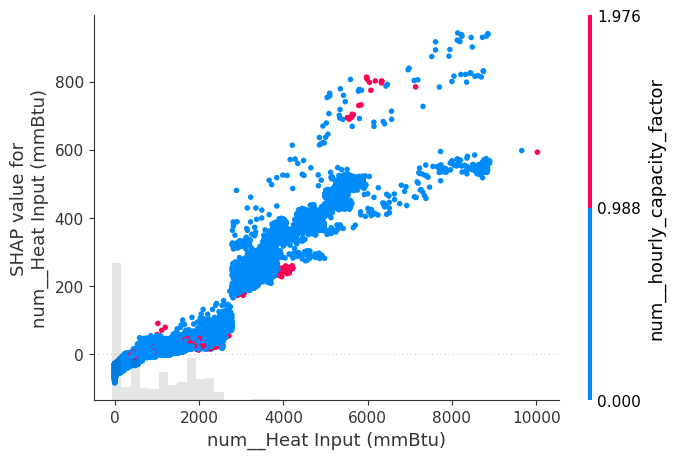

In [241]:
shap.plots.scatter(shap_values[:,"num__Heat Input (mmBtu)"], color=shap_values[:,"num__hourly_capacity_factor"])

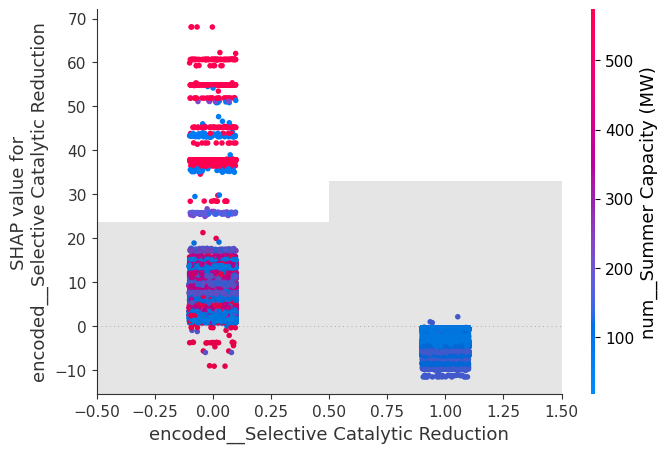

In [237]:
shap.plots.scatter(shap_values[:,"encoded__Selective Catalytic Reduction"], color=shap_values[:,"num__Summer Capacity (MW)"])

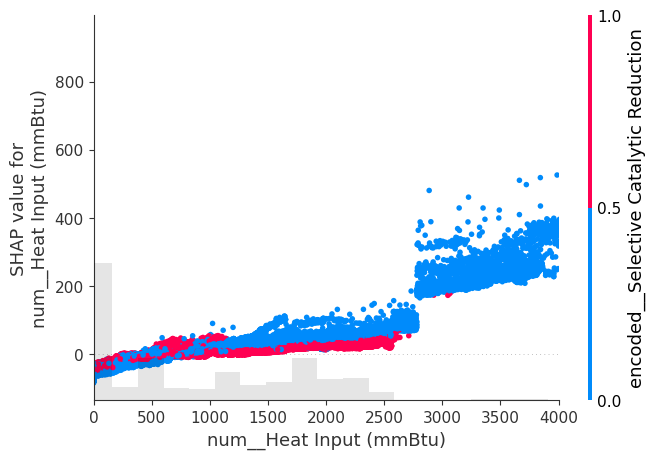

In [235]:
# Create the scatter plot
shap.plots.scatter(shap_values[:, "num__Heat Input (mmBtu)"], 
                   color=shap_values[:, "encoded__Selective Catalytic Reduction"],show=False)

# Adjust the x-axis limits
plt.xlim(0, 4000)  # Replace 'lower_limit' and 'upper_limit' with your desired range

# Show the updated plot
plt.show()

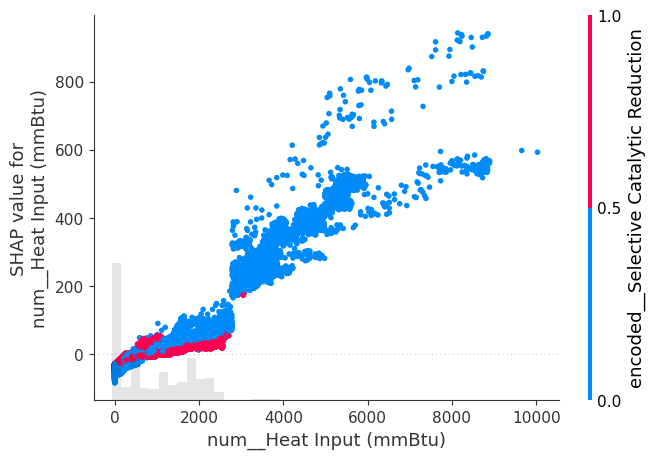

In [232]:
shap.plots.scatter(shap_values[:,"num__Heat Input (mmBtu)"], color=shap_values[:,"encoded__Selective Catalytic Reduction"])

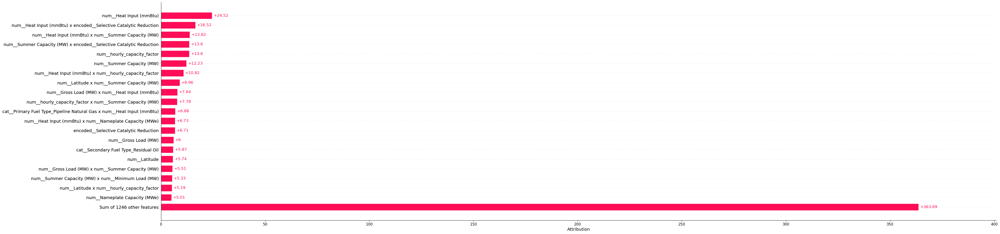

In [53]:
shapiq.plot.bar_plot(list_of_interaction_values, feature_names=X_test.columns.tolist(), max_display=20, show=True, abbreviate=False)

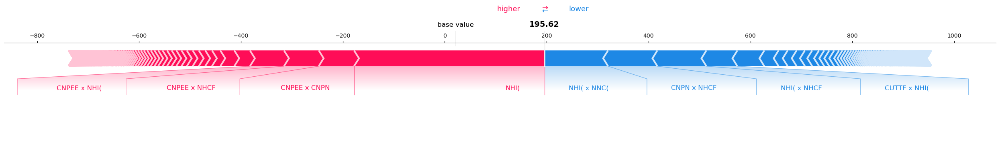

In [107]:
shapiq.plot.force_plot(explanation, feature_names=X_test.columns, show=True, abbreviate=True, figsize=(25,4))

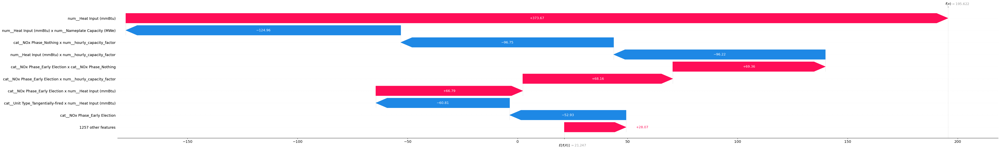

In [98]:
shapiq.plot.waterfall_plot(explanation, feature_names=X_test.columns, show=True, abbreviate=False)

<h5>With Lags, No Temps</h5>

In [ ]:
explainer = shap.TreeExplainer(xgb_default_model)

In [ ]:
X_test = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/X_test_processed", dtype=campd_type_dict)

In [ ]:
shap_values = explainer(X_test, approximate=False)

In [ ]:
joblib.dump(shap_values, "WY/Hourly/Concatted File/Modeling/XGB/Trained Models/shap_values_xgb_default_model_wy_with_lags_no_unmeasured.pkl", compress=True)

['NY/Hourly/Concatted File/Modeling/XGB/Trained Models/shap_values_xgb_default_model_ny_with_lags_no_unmeasured.pkl']

In [ ]:
shap_values = joblib.load("WY/Hourly/Concatted File/Modeling/XGB/Trained Models/shap_values_xgb_default_model_wy_with_lags_no_unmeasured.pkl")

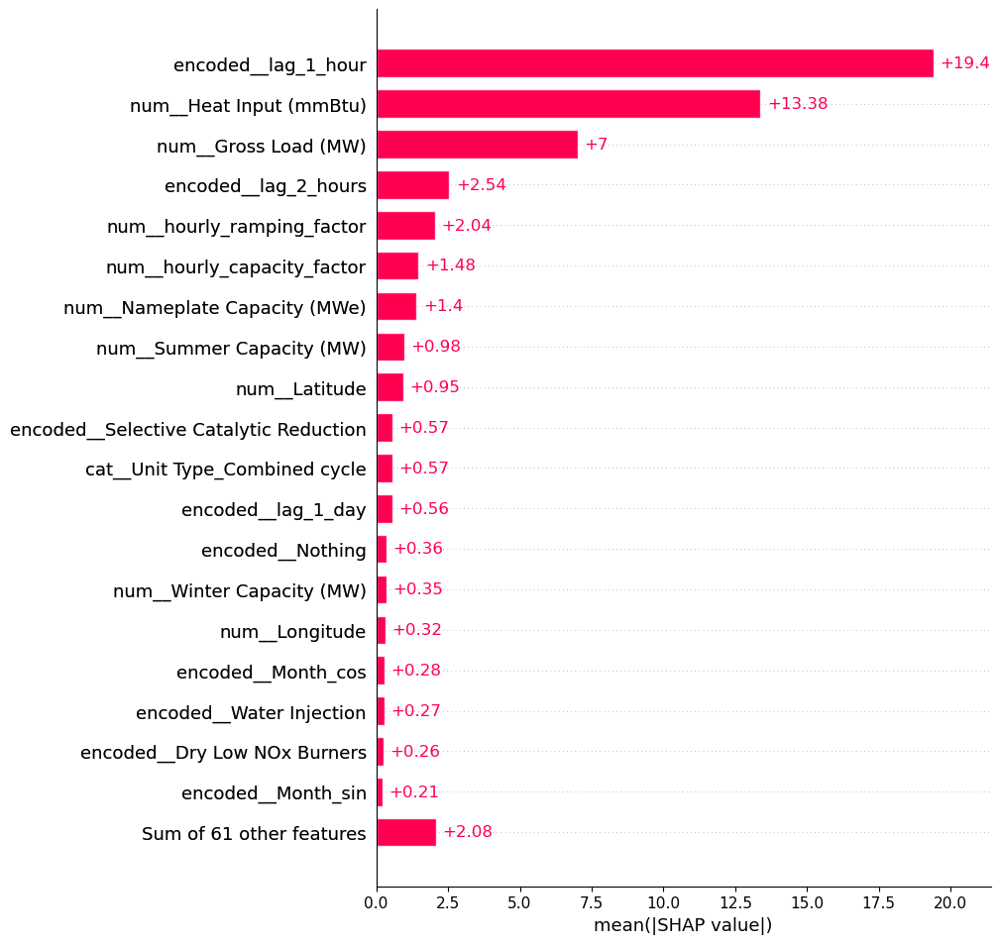

In [ ]:
shap.plots.bar(shap_values, max_display=20)

In [ ]:
shap.plots.waterfall(shap_values[0], max_display=20)

In [ ]:
# global visualizations

# shap.plots.bar(shap_values) # mean absolute value of each feature over all rows
# shap.plots.bar(shap_values.abs.max(0)) # gives max absolute values of features e. g. if features occur infrequently, but have significant effects
# shap.plots.beeswarm(shap_values) # beeswarm plot -> gives context on relationships of high and low feature values to SHAP values

# deal with clustering
# clustering = shap.utils.hclust(X_adult, y_adult)
# shap.plots.bar(shap_values, clustering=clustering)
# shap.plots.bar(shap_values, clustering=clustering, clustering_cutoff=1) # sets distance threshold for clusters, lower values will create smaller clusters

# shap.plots.scatter(shap_values, ylabel="SHAP value") # scatter plots between feature and shap values

<h4>Using HPO parameters</h4>

In [4]:
explainer = shap.TreeExplainer(xgb_hpo_model)

In [ ]:
X_test = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/X_test_processed", dtype=campd_type_dict)

In [6]:
shap_values = explainer(X_test, approximate=True) # need to approximate because otherwise it is to computationally expensive for the hpo model

In [ ]:
joblib.dump(shap_values, "WY/Hourly/Concatted File/Modeling/XGB/Trained Models/shap_values_xgb_hpo_model_wy_with_lags_no_unmeasured.pkl", compress=True)

['NY/Hourly/Concatted File/Modeling/XGB/Trained Models/shap_values_xgb_hpo_model_ny_with_lags_no_unmeasured.pkl']

In [ ]:
shap_values = joblib.load("WY/Hourly/Concatted File/Modeling/XGB/Trained Models/shap_values_xgb_hpo_model_wy_with_lags_no_unmeasured.pkl")

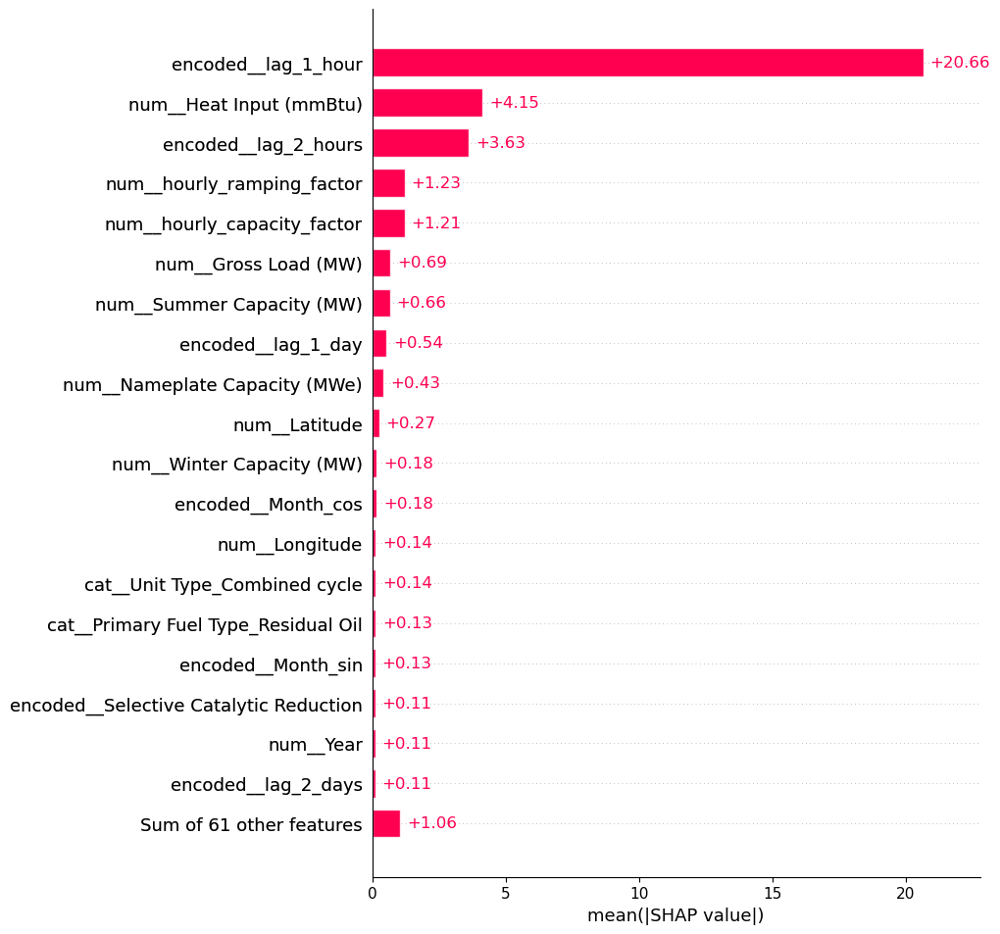

In [8]:
shap.plots.bar(shap_values, max_display=20)

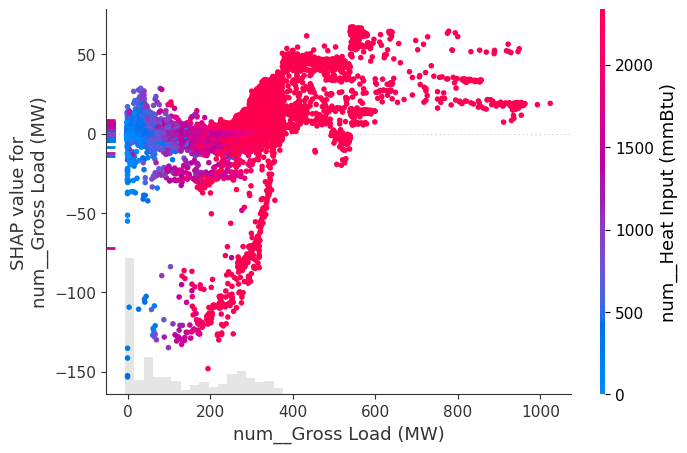

In [9]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"num__Heat Input (mmBtu)"])


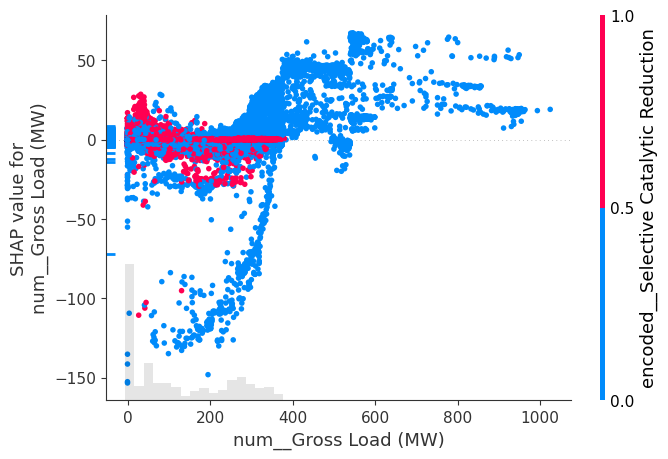

In [10]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"encoded__Selective Catalytic Reduction"])


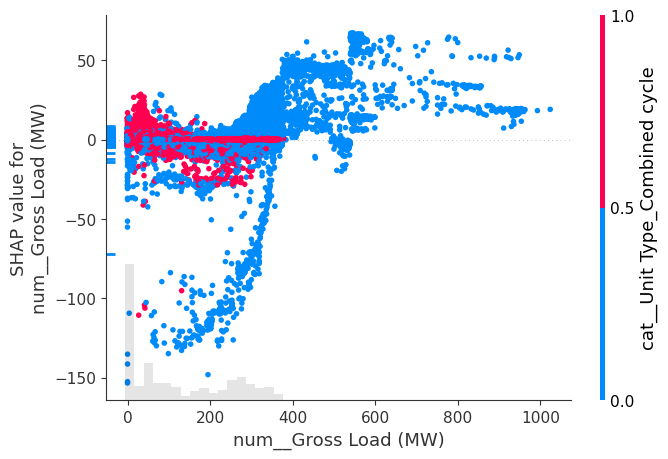

In [11]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"cat__Unit Type_Combined cycle"])  


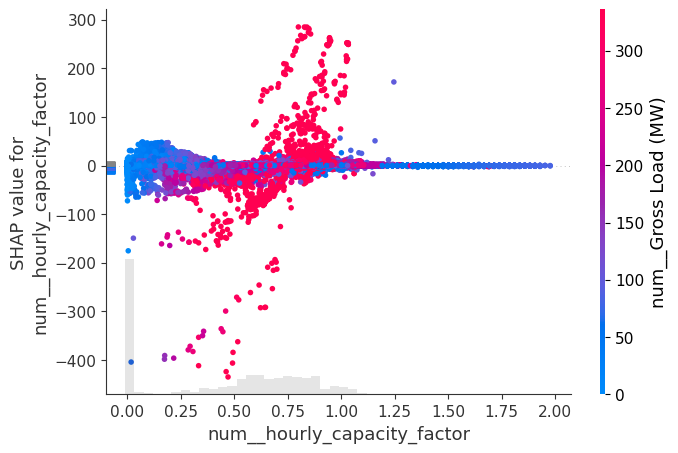

In [12]:
shap.plots.scatter(shap_values[:,"num__hourly_capacity_factor"], color=shap_values[:,"num__Gross Load (MW)"])


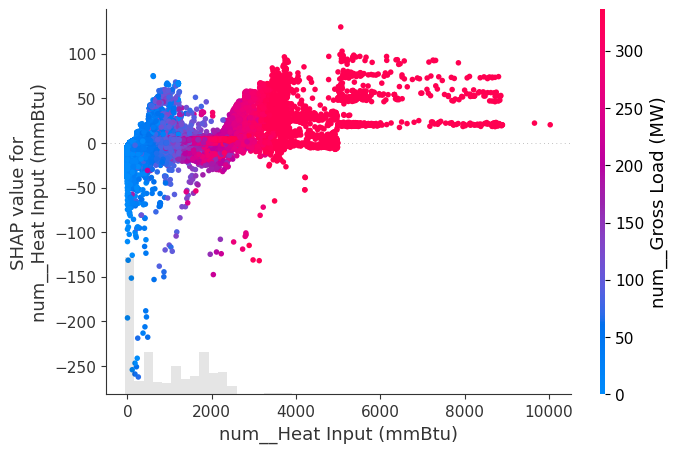

In [13]:
shap.plots.scatter(shap_values[:,"num__Heat Input (mmBtu)"], color=shap_values[:,"num__Gross Load (MW)"])


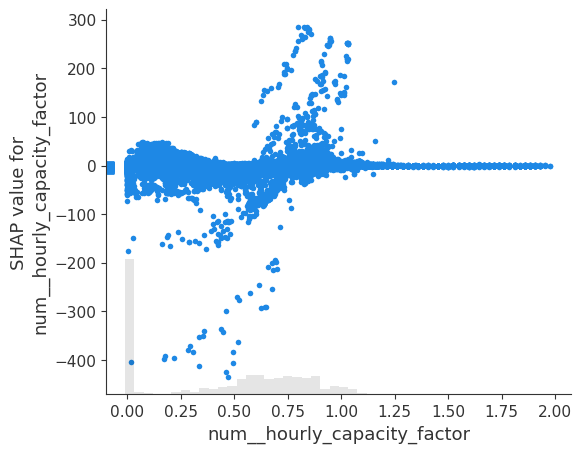

In [14]:
shap.plots.scatter(shap_values[:,"num__hourly_capacity_factor"])#, color=shap_values[:,"encoded__Selective Catalytic Reduction"])


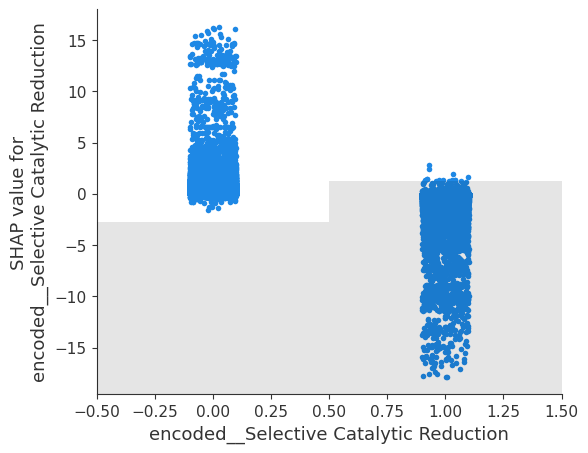

In [15]:
shap.plots.scatter(shap_values[:,"encoded__Selective Catalytic Reduction"])


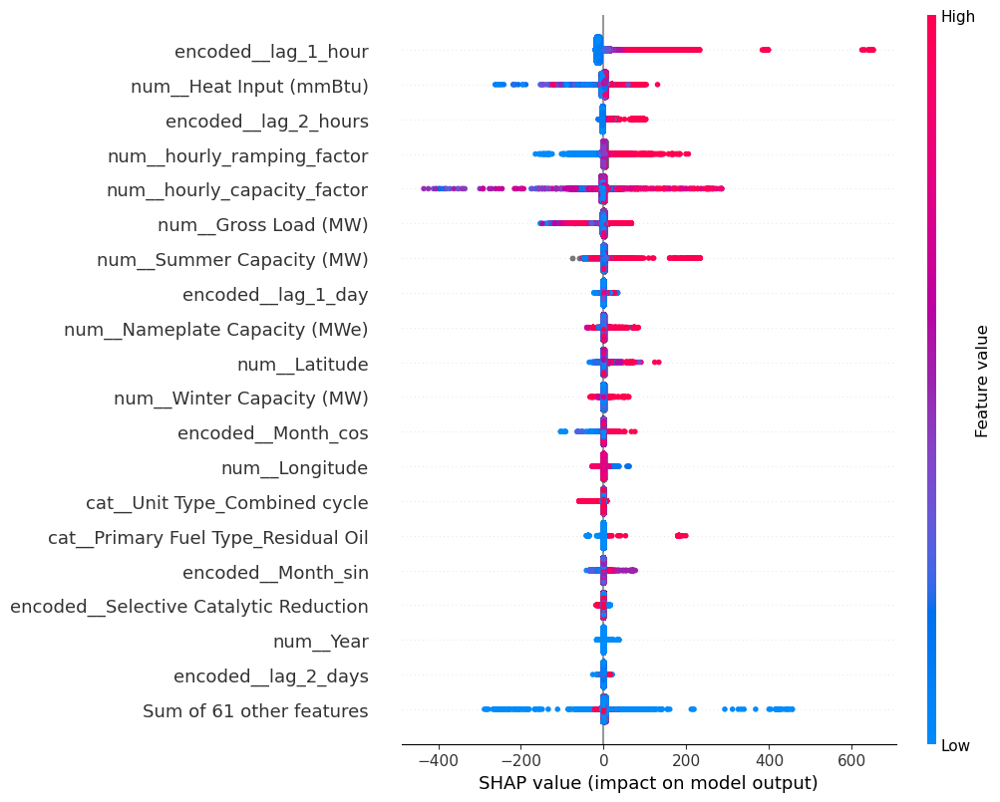

In [16]:
shap.plots.beeswarm(shap_values, max_display=20)


In [17]:
# define feature groups (important for aggregation of encoded cols)
feature_groups = {
    "Source Category": [
        'cat__Source Category_Cogeneration',
        'cat__Source Category_Electric Utility',
        'cat__Source Category_Missing'
    ],
    
    "NOx Phase": [
        'cat__NOx Phase_Early Election',
        'cat__NOx Phase_Nothing',
        'cat__NOx Phase_Phase 1 Group 1',
        'cat__NOx Phase_Phase 2 Group 1'
    ],
    
    "Unit Type": [
        'cat__Unit Type_Circulating fluidized bed boiler',
        'cat__Unit Type_Combined cycle',
        'cat__Unit Type_Combined cycle (Started Feb 23, 2020)',
        'cat__Unit Type_Combustion turbine',
        'cat__Unit Type_Dry bottom wall-fired boiler',
        'cat__Unit Type_Other boiler',
        'cat__Unit Type_Tangentially-fired'
    ],
    
    "Primary Fuel Type": [
        'cat__Primary Fuel Type_Coal',
        'cat__Primary Fuel Type_Diesel Oil',
        'cat__Primary Fuel Type_Natural Gas',
        'cat__Primary Fuel Type_Other Oil',
        'cat__Primary Fuel Type_Pipeline Natural Gas',
        'cat__Primary Fuel Type_Residual Oil',
        'cat__Primary Fuel Type_Wood'
    ],
    
    "Secondary Fuel Type": [
        'cat__Secondary Fuel Type_Diesel Oil',
        'cat__Secondary Fuel Type_Natural Gas, Wood',
        'cat__Secondary Fuel Type_Nothing',
        'cat__Secondary Fuel Type_Other Oil',
        'cat__Secondary Fuel Type_Other Solid Fuel, Petroleum Coke, Tire Derived Fuel',
        'cat__Secondary Fuel Type_Pipeline Natural Gas',
        'cat__Secondary Fuel Type_Residual Oil',
        'cat__Secondary Fuel Type_Wood'
    ],

    "Gross Load (MW)": ['num__Gross Load (MW)'],
    "Heat Input (mmBtu)": ['num__Heat Input (mmBtu)'],
    "Latitude": ['num__Latitude'],
    "Longitude": ['num__Longitude'],
    "Nameplate Capacity (MWe)": ['num__Nameplate Capacity (MWe)'],
    "hourly_capacity_factor": ['num__hourly_capacity_factor'],
    "hourly_ramping_factor": ['num__hourly_ramping_factor'],
    "Summer Capacity (MW)": ['num__Summer Capacity (MW)'],
    "Winter Capacity (MW)": ['num__Winter Capacity (MW)'],
    "Minimum Load (MW)": ['num__Minimum Load (MW)'],
    "Year": ['num__Year'],

    "Control Technologies": [
        'encoded__Ammonia Injection',
        'encoded__Combustion Modification/Fuel Reburning',
        'encoded__Dry Low NOx Burners',
        'encoded__Low NOx Burner Technology (Dry Bottom only)',
        'encoded__Low NOx Burner Technology w/ Closed-coupled OFA',
        'encoded__Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
        'encoded__Low NOx Burner Technology w/ Overfire Air',
        'encoded__Low NOx Burner Technology w/ Separated OFA',
        'encoded__Nothing',
        'encoded__Other',
        'encoded__Overfire Air',
        'encoded__Selective Catalytic Reduction',
        'encoded__Selective Non-catalytic Reduction',
        'encoded__Steam Injection',
        'encoded__Water Injection',
        'encoded__Water Injection (Began Jul 01, 2022)'
    ],

    "Programs / Regulations": [
        'encoded__ARP',
        'encoded__CSNOX',
        'encoded__CSOSG2',
        'encoded__CSOSG2E',
        'encoded__CSOSG3',
        'encoded__CSSO2G1',
        'encoded__MATS',
        'encoded__Missing',
        'encoded__NSPS4T',
        'encoded__RGGI',
        'encoded__SIPNOX'
    ],

    "Hour": [
        'encoded__Hour_sin',
        'encoded__Hour_cos'
    ],
    "Day": [
        'encoded__Day_sin',
        'encoded__Day_cos'
    ],
    "Month": [
        'encoded__Month_sin',
        'encoded__Month_cos'
    ],

    "Lag Features": [
        'encoded__lag_1_hour',
        'encoded__lag_2_hours',
        'encoded__lag_1_day',
        'encoded__lag_2_days',
        'encoded__lag_1_week',
        'encoded__lag_1_month',
        'encoded__lag_1_year'
    ]
}

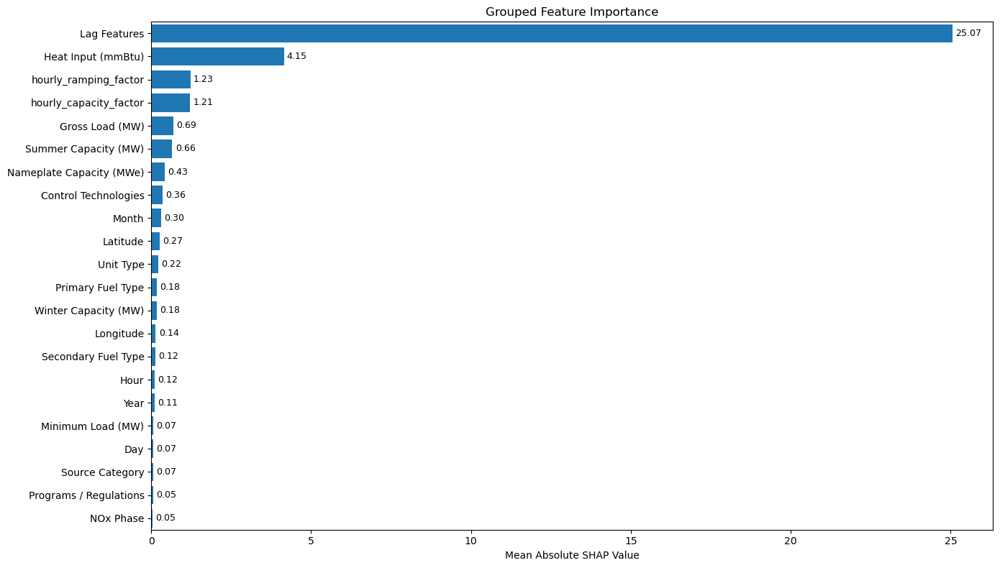

In [18]:
# Aggregate (sum) the shap values of encoded columns

# create series of mean absolute SHAP values per feature (using feature name as index)
mean_abs_shap = np.abs(shap_values.values).mean(axis=0) 
shap_importance = pd.Series(mean_abs_shap, index=shap_values.feature_names)

# aggregate by feature groups (sum the mean absolute values within pre-defined groups)
group_importance = {}
for group, features in feature_groups.items():
    group_importance[group] = shap_importance[features].sum() 

group_importance = pd.Series(group_importance).sort_values(ascending=False)

# plot
fig, ax = plt.subplots(figsize=(14, 8))
bars = ax.barh(group_importance.index, group_importance.values)
group_importance.plot(kind='barh')
ax.bar_label(bars, fmt='%.2f', label_type='edge', padding=3, fontsize=9) # add bar labels
plt.gca().invert_yaxis()  # invert to get largest at top
plt.title('Grouped Feature Importance')
plt.xlabel('Mean Absolute SHAP Value')
plt.tight_layout()
plt.show()
